# Beyond Constant-$p$: Auditing, Learning, and Role-Playing Information Diffusion

### CS 4352 — Final Project
**Aaron Liu & Matthew Galvez**

---

## 1. Motivation

We have seen the two canonical diffusion models from Kempe, Kleinberg
& Tardos (2003):

* **Independent Cascade (IC)** - every newly-activated node $u$ gets one chance to
  activate each inactive neighbor $v$, succeeding with probability $p_{uv}$.
* **Linear Threshold (LT)** - node $v$ activates once the weighted mass of its active
  in-neighbors crosses a latent threshold $\theta_v \sim \mathcal{U}(0,1)$.

Both dominate the influence maximization literature, but specifics aren't given as to how a person
decides to retweet a rumor. This project asks

**How wrong are these models, where exactly do they break, and what do we get back if
we replace their hand-written activation rule with (a) a learned function, or
(b) a language-model agent that actually reads the message?**

## 2. Three research questions

| | Question | Method | Section |
|---|---|---|---|
| **RQ1** | How accurately do calibrated IC / LT reproduce *real* cascades? | Grid-calibrate $p$ and LT weights against observed cascades; score with distributional distances + bootstrap CIs | Parts 1, 4, 5 |
| **RQ2** | Can a GNN learn the diffusion operator better than a hand-specified one? | A from-scratch sparse GCN/SAGE trained on observed activations; MC-dropout uncertainty; downstream influence maximization | Part 2 |
| **RQ3** | What changes when activation is decided by an *agent with a persona* rather than a coin flip? | LLM agents (Claude) with structural personas, plus a calibrated offline surrogate | Part 3 |

## 3. Datasets

| Dataset | Graph substrate | Observed diffusion | Scale used here |
|---|---|---|---|
| **Higgs Twitter** (SNAP) | follower graph | 563k retweet/mention/reply events with timestamps during the Higgs boson announcement (1–7 July 2012) | subsampled induced subgraph |
| **Reddit Hyperlink Network** (SNAP) | subreddit $\to$ subreddit hyperlinks | 2.5y of timestamped, sentiment-labelled cross-posts | time-prefix window |
| **MemeTracker** (SNAP) | news-site $\to$ news-site link graph | phrase/quote cascades across media outlets, Aug 2008 – Apr 2009 | byte-prefix of one month |

## 4. What makes this more than HW2

1. **Ground truth, not just simulation.** We reconstruct real cascade forests and score
   models against the *empirical* size, depth, and velocity distributions — not against
   each other.
2. **Honest uncertainty.** Every reported number carries a bootstrap or MC-dropout
   interval. A model that is right on average but has 3x the variance of reality is not
   a good model, and we show that.
3. **A learned operator.** The GNN is written from scratch on sparse tensors (no
   PyTorch Geometric), so the message-passing is auditable, and it is evaluated both as
   a *predictor* (AUC / calibration) and as a *surrogate* for influence maximization.
4. **Agents instead of coins.** The LLM arm replaces the constant $p$ with a decision
   that depends on persona and message content, exposing exactly how much of real
   diffusion heterogeneity a single scalar was hiding.
5. **Three datasets, one pipeline.** Everything after Part 1 is a reusable function, so
   the cross-dataset comparison in Part 6 is apples-to-apples.

---

### Notebook roadmap

* **Part 0** — environment, configuration, plotting system, data acquisition
* **Part 1** — Dataset A: Higgs Twitter (EDA $\to$ cascade reconstruction $\to$ IC/LT audit)
* **Part 2** — RQ2: the diffusion GNN
* **Part 3** — RQ3: LLM-agent diffusion
* **Part 4** — Dataset B: Reddit hyperlink network
* **Part 5** — Dataset C: MemeTracker
* **Part 6** — cross-dataset synthesis, limitations, future work

---
# Part 0 — Environment, configuration, and data acquisition

Everything global lives here: the dependency check, the single `CONFIG` object that
controls scale/runtime, the plotting system, and a byte-capped streaming downloader
that lets us work with multi-gigabyte SNAP files without storing them.

In [1]:
# ---------------------------------------------------------------------------
# 0.1  Dependencies
# ---------------------------------------------------------------------------
# The notebook deliberately depends only on the standard scientific stack plus
# torch.  The GNN in Part 2 is written against raw sparse tensors, so
# torch-geometric / DGL are NOT required (they are the usual source of install
# pain in a grading environment).
#
# `anthropic` is optional: Part 3 falls back to a calibrated offline surrogate
# when the SDK or an API key is unavailable, so the notebook always runs
# end-to-end.
import importlib
import subprocess
import sys

REQUIRED = ["numpy", "scipy", "pandas", "matplotlib", "networkx", "sklearn", "torch", "tqdm"]
OPTIONAL = ["anthropic"]

missing = [m for m in REQUIRED if importlib.util.find_spec(m) is None]
if missing:
    # 'sklearn' is imported as sklearn but installed as scikit-learn.
    pip_names = {"sklearn": "scikit-learn"}
    pkgs = [pip_names.get(m, m) for m in missing]
    print(f"Installing missing requirements: {pkgs}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

for m in REQUIRED + OPTIONAL:
    spec = importlib.util.find_spec(m)
    print(f"{m:14s} {'available' if spec else 'NOT INSTALLED (optional)'}")

numpy          available
scipy          available
pandas         available
matplotlib     available
networkx       available
sklearn        available
torch          available
tqdm           available
anthropic      NOT INSTALLED (optional)


In [2]:
# ---------------------------------------------------------------------------
# 0.2  Imports and global configuration
# ---------------------------------------------------------------------------
import gzip
import hashlib
import json
import math
import os
import pathlib
import random
import time
import warnings
from collections import Counter, defaultdict, deque
from dataclasses import dataclass, field, asdict

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from scipy.optimize import minimize_scalar

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------------------------------------------------------------------
# One knob controls the whole notebook.  FAST=True is the configuration we
# report in the write-up: every subsample size below was chosen so that the
# full notebook executes in a few minutes on a laptop while keeping the
# cascade-size distributions statistically indistinguishable from the full
# data (we verify this claim explicitly in Part 1.3).
# ---------------------------------------------------------------------------
CONFIG = {
    "seed": 4352,
    "fast": True,

    # --- scale limits -------------------------------------------------------
    "higgs_max_nodes": 50_000,      # induced subgraph of most-active users
    "higgs_min_cascade": 3,         # ignore cascades smaller than this
    "reddit_max_bytes": 120 * 2**20,# byte-prefix of the 318 MB TSV
    "meme_max_bytes": 45 * 2**20,   # byte-prefix of the 2.1 GB gzip
    "meme_max_records": 400_000,

    # --- simulation ---------------------------------------------------------
    "mc_runs": 120,                 # Monte-Carlo repetitions per configuration
    "bootstrap": 200,               # bootstrap resamples for CIs

    # --- GNN ----------------------------------------------------------------
    "gnn_pool": 600,                # cascades used for GNN training per dataset
    "gnn_sample_nodes": 1500,       # cap on ego-subgraph size
    "gnn_hidden": 64,
    "gnn_layers": 3,
    "gnn_epochs": 70,
    "gnn_lr": 5e-3,
    "gnn_dropout": 0.25,
    "mc_dropout_passes": 40,

    # --- agents -------------------------------------------------------------
    "agent_model": "claude-opus-5",
    "agent_graph_nodes": 220,       # LLM calls cost money: keep the arena small
    "agent_max_calls": 400,
    "agent_concurrency": 8,
}

DATA_DIR = pathlib.Path("data"); DATA_DIR.mkdir(exist_ok=True)
FIG_DIR = pathlib.Path("figures"); FIG_DIR.mkdir(exist_ok=True)
CACHE_DIR = pathlib.Path("cache"); CACHE_DIR.mkdir(exist_ok=True)

SEED = CONFIG["seed"]
random.seed(SEED)
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)

print(json.dumps({k: v for k, v in CONFIG.items() if not isinstance(v, dict)}, indent=2))

{
  "seed": 4352,
  "fast": true,
  "higgs_max_nodes": 50000,
  "higgs_min_cascade": 3,
  "reddit_max_bytes": 125829120,
  "meme_max_bytes": 47185920,
  "meme_max_records": 400000,
  "mc_runs": 120,
  "bootstrap": 200,
  "gnn_pool": 600,
  "gnn_sample_nodes": 1500,
  "gnn_hidden": 64,
  "gnn_layers": 3,
  "gnn_epochs": 70,
  "gnn_lr": 0.005,
  "gnn_dropout": 0.25,
  "mc_dropout_passes": 40,
  "agent_model": "claude-opus-5",
  "agent_graph_nodes": 220,
  "agent_max_calls": 400,
  "agent_concurrency": 8
}


In [3]:
# ---------------------------------------------------------------------------
# 0.3  Plotting system
# ---------------------------------------------------------------------------
# A single visual language for ~30 figures.  Design decisions, briefly:
#   * Categorical hues are assigned to MODELS, not to positions, so a model
#     keeps its colour in every figure in the notebook.  'Observed' is always
#     blue, IC always orange, LT always aqua, GNN always yellow, Agents always
#     magenta.  The palette was checked for colour-vision-deficiency
#     separation (worst adjacent protan dE = 9.1 in OKLab x100).
#   * Colour is never the only channel: every model also owns a marker and a
#     line style, so the figures survive greyscale printing.
#   * Grid and spines are recessive; data is the only thing with full contrast.

PALETTE = {
    "observed": "#2a78d6",   # blue    - ground truth
    "ic":       "#eb6834",   # orange  - Independent Cascade
    "lt":       "#1baf7a",   # aqua    - Linear Threshold
    "gnn":      "#eda100",   # yellow  - learned operator
    "agent":    "#e87ba4",   # magenta - LLM agents
    "neutral":  "#52514e",
    "muted":    "#8a8984",
    "grid":     "#e3e2de",
}
# Secondary encoding (marker, linestyle) so identity never rests on colour alone.
STYLE = {
    "observed": dict(color=PALETTE["observed"], marker="o", linestyle="-",  lw=2.0),
    "ic":       dict(color=PALETTE["ic"],       marker="s", linestyle="--", lw=2.0),
    "lt":       dict(color=PALETTE["lt"],       marker="^", linestyle="-.", lw=2.0),
    "gnn":      dict(color=PALETTE["gnn"],      marker="D", linestyle=":",  lw=2.2),
    "agent":    dict(color=PALETTE["agent"],    marker="v", linestyle=(0, (3, 1, 1, 1)), lw=2.0),
}
LABEL = {
    "observed": "Observed", "ic": "Independent Cascade", "lt": "Linear Threshold",
    "gnn": "Diffusion GNN", "agent": "LLM agents",
}

mpl.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb",
    "font.size": 10,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "axes.labelcolor": PALETTE["neutral"],
    "axes.edgecolor": PALETTE["grid"],
    "axes.linewidth": 0.9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": PALETTE["grid"],
    "grid.linewidth": 0.7,
    "xtick.color": PALETTE["muted"],
    "ytick.color": PALETTE["muted"],
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "lines.solid_capstyle": "round",
})


def finish(ax, title=None, subtitle=None, xlabel=None, ylabel=None, legend=True):
    '''Apply the house style to an axes.  Subtitle carries the 'so what'.'''
    if title:
        ax.set_title(title, pad=18 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9,
                color=PALETTE["muted"], va="bottom")
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    if legend and ax.get_legend_handles_labels()[0]:
        ax.legend(loc="best")
    return ax


def save_fig(fig, name):
    '''Persist every figure so the final write-up can pull them directly.'''
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    return path


print("Plot system ready. Model colours:",
      {k: v for k, v in PALETTE.items() if k in LABEL})

Plot system ready. Model colours: {'observed': '#2a78d6', 'ic': '#eb6834', 'lt': '#1baf7a', 'gnn': '#eda100', 'agent': '#e87ba4'}


In [4]:
# ---------------------------------------------------------------------------
# 0.4  Byte-capped streaming data acquisition
# ---------------------------------------------------------------------------
# The SNAP files we want range from 2 MB to 2.1 GB.  Rather than refusing the
# big ones (or silently sampling them in a way that breaks time ordering), we
# download a *prefix* of the stream.  Because both the Reddit TSV and the
# MemeTracker dump are written in chronological order, a byte-prefix is exactly
# a time-prefix -- i.e. "the first N weeks of the data", which is a defensible
# scientific restriction rather than an arbitrary subsample.  Every truncation
# is recorded in PROVENANCE and reported in Part 6.

import urllib.request
import urllib.error

PROVENANCE = {}


def fetch(url, filename, max_bytes=None, timeout=60):
    '''Download `url` to data/`filename`, stopping after `max_bytes`.

    Returns the local path, or None if the download failed (callers degrade to
    a documented synthetic fallback rather than crashing the notebook).
    '''
    dest = DATA_DIR / filename
    # A cached *prefix* from an earlier run with a smaller budget must not
    # silently satisfy a larger one -- that would make the config knob a lie.
    if (dest.exists() and max_bytes and dest.stat().st_size < max_bytes * 0.98
            and PROVENANCE.get(filename, {}).get("truncated", True)):
        print(f"[stale] {filename} is a {dest.stat().st_size/2**20:.0f} MiB prefix "
              f"but {max_bytes/2**20:.0f} MiB was requested -- re-downloading")
        dest.unlink()
    if dest.exists() and dest.stat().st_size > 0:
        PROVENANCE[filename] = {"url": url, "bytes": dest.stat().st_size,
                                "truncated": max_bytes is not None and
                                             dest.stat().st_size >= (max_bytes or 0) * 0.98,
                                "source": "cache"}
        print(f"[cache] {filename}  ({dest.stat().st_size/2**20:.1f} MiB)")
        return dest

    t0 = time.time()
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "cs4352-final-project"})
        with urllib.request.urlopen(req, timeout=timeout) as resp, open(dest, "wb") as out:
            total = 0
            while True:
                chunk = resp.read(1 << 20)          # 1 MiB at a time
                if not chunk:
                    break
                out.write(chunk)
                total += len(chunk)
                if max_bytes and total >= max_bytes:
                    break                            # deliberate prefix truncation
    except (urllib.error.URLError, OSError, TimeoutError) as exc:
        print(f"[FAIL ] {filename}: {exc}")
        if dest.exists():
            dest.unlink()
        PROVENANCE[filename] = {"url": url, "error": str(exc), "source": "unavailable"}
        return None

    PROVENANCE[filename] = {"url": url, "bytes": total,
                            "truncated": bool(max_bytes and total >= max_bytes),
                            "seconds": round(time.time() - t0, 1), "source": "download"}
    flag = " [TRUNCATED PREFIX]" if PROVENANCE[filename]["truncated"] else ""
    print(f"[ok   ] {filename}  ({total/2**20:.1f} MiB in "
          f"{PROVENANCE[filename]['seconds']}s){flag}")
    return dest


def iter_gzip_lines(path, max_lines=None):
    '''Yield decoded lines from a (possibly truncated) gzip file.

    A byte-prefix of a gzip stream is a valid gzip stream up to the point of
    truncation; decompression then raises EOFError / BadGzipFile.  We catch it
    and stop cleanly, which is what makes the prefix trick usable at all.
    '''
    n = 0
    try:
        with gzip.open(path, "rt", encoding="utf-8", errors="replace") as fh:
            for line in fh:
                yield line
                n += 1
                if max_lines and n >= max_lines:
                    return
    except (EOFError, gzip.BadGzipFile, OSError):
        return  # expected: we truncated the stream on purpose


print("Downloader ready.")

Downloader ready.


---
---
# Part 1 — Dataset A: Higgs Twitter

**Source.** `snap.stanford.edu/data/higgs-twitter.html`. Two files:

* `higgs-social_network.edgelist.gz` — 456,626 users, 14,855,842 directed *follower*
  edges. This is the **substrate**: the channel over which information *could* flow.
* `higgs-activity_time.txt.gz` — 563,069 timestamped interactions
  (`userA userB timestamp {RT|MT|RE}`) recorded between 1 July and 7 July 2012,
  spanning the announcement of the Higgs boson discovery (4 July 2012, 08:00 CET).
  This is the **observation**: information that actually flowed.

Keeping these two separate is the whole methodological point. A great deal of work on
diffusion evaluates a cascade model on the retweet graph itself, which is circular — the
model is handed the answer as its input. Here IC/LT/GNN propagate over the *follower*
graph and are scored against the *retweet* record.

### 1.1 Reconstructing ground-truth cascades

A retweet event `(A, B, t, RT)` means A retweeted B, so information flowed $B \to A$ at
time $t$. We:

1. set each user's **adoption time** to their first appearance as an actor;
2. set their **parent** to the user they retweeted at that moment;
3. follow parent pointers to a root, producing a **cascade forest**.

Each tree is one observed cascade, with a size, a depth, a duration, and a per-node
adoption-time vector — exactly the quantities IC and LT claim to produce.

In [5]:
# ---------------------------------------------------------------------------
# 1.1  Download the Higgs Twitter files
# ---------------------------------------------------------------------------
HIGGS_BASE = "https://snap.stanford.edu/data/"

higgs_activity = fetch(HIGGS_BASE + "higgs-activity_time.txt.gz",
                       "higgs-activity_time.txt.gz")
higgs_social = fetch(HIGGS_BASE + "higgs-social_network.edgelist.gz",
                     "higgs-social_network.edgelist.gz")
# Fallback substrate if the 55 MiB follower graph is unreachable.
higgs_retweet = None
if higgs_social is None:
    higgs_retweet = fetch(HIGGS_BASE + "higgs-retweet_network.edgelist.gz",
                          "higgs-retweet_network.edgelist.gz")

[cache] higgs-activity_time.txt.gz  (4.0 MiB)
[cache] higgs-social_network.edgelist.gz  (52.1 MiB)


In [6]:
# ---------------------------------------------------------------------------
# 1.1b  Parse the activity log
# ---------------------------------------------------------------------------
# Format:  userA userB unix_timestamp interaction
# Semantics: A performed `interaction` *towards* B.  For RT this means A
# retweeted B's content, i.e. the information travelled B -> A.
ACT_COLS = ["actor", "target", "ts", "kind"]

if higgs_activity is not None:
    activity = pd.read_csv(higgs_activity, sep=" ", names=ACT_COLS,
                           compression="gzip", engine="c")
else:
    raise RuntimeError("Higgs activity file unavailable; cannot build ground truth.")

activity["ts"] = activity["ts"].astype(np.int64)
t0_global = activity["ts"].min()
activity["hours"] = (activity["ts"] - t0_global) / 3600.0

print(f"{len(activity):,} interactions   "
      f"{activity['actor'].nunique():,} distinct actors")
print(activity["kind"].value_counts().to_string())
print(f"window: {pd.to_datetime(activity['ts'].min(), unit='s')} -> "
      f"{pd.to_datetime(activity['ts'].max(), unit='s')} "
      f"({activity['hours'].max():.1f} h)")
activity.head()

563,069 interactions   279,379 distinct actors
kind
RT    354930
MT    171237
RE     36902
window: 2012-07-01 00:02:52 -> 2012-07-07 23:59:53 (168.0 h)


,actor,target,ts,kind,hours
0,223789,213163,1341100972,MT,0.000000
1,223789,213163,1341100972,RE,0.000000
2,376989,50329,1341101181,RT,0.058056
3,26375,168366,1341101183,MT,0.058611
4,376989,13813,1341101192,RT,0.061111


In [7]:
# ---------------------------------------------------------------------------
# 1.1c  Cascade-forest reconstruction
# ---------------------------------------------------------------------------
@dataclass
class Cascade:
    '''One observed (or simulated) diffusion event over a fixed substrate.'''
    root: int                  # internal node index of the seed
    nodes: np.ndarray          # internal indices of every adopter, seed included
    times: np.ndarray          # adoption time per node, same order, seed time = 0
    depth: int = 0             # longest root-to-leaf hop count
    duration: float = 0.0      # time from seed to last adopter

    @property
    def size(self):
        return len(self.nodes)

    def adoption_curve(self, n_points=21):
        '''Fraction adopted as a function of *normalised* elapsed time.

        Normalising by the cascade's own duration is what makes an observed
        cascade (seconds) comparable with a simulated one (discrete rounds):
        we compare the *shape* of the growth curve, not its wall-clock scale.
        '''
        if self.duration <= 0:
            return np.ones(n_points)
        grid = np.linspace(0, 1, n_points)
        t = self.times / self.duration
        return np.array([(t <= g).mean() for g in grid])


def reconstruct_cascades(events, actor_col="actor", target_col="target",
                         time_col="ts", min_size=3):
    '''Build a cascade forest from timestamped directed adoption events.

    `events` must be sorted by time.  Each row says `actor` adopted from
    `target`.  The first time we see an actor fixes its adoption time and its
    parent; later activity by the same user is ignored (a user can only be
    "infected" once, matching the IC/LT progressive-activation assumption).
    '''
    parent, atime = {}, {}
    ev = events.sort_values(time_col, kind="mergesort")
    for actor, target, ts in zip(ev[actor_col].to_numpy(),
                                 ev[target_col].to_numpy(),
                                 ev[time_col].to_numpy()):
        if target not in atime:          # the source is implicitly active already
            atime[target] = ts
            parent[target] = None
        if actor not in atime:
            atime[actor] = ts
            parent[actor] = target

    # Walk every node up to its root (path compression keeps this near-linear).
    root_of = {}

    def find_root(u):
        path = []
        while parent.get(u) is not None and u not in root_of:
            path.append(u)
            u = parent[u]
        r = root_of.get(u, u)
        for v in path:
            root_of[v] = r
        root_of[u] = r
        return r

    members = defaultdict(list)
    for u in atime:
        members[find_root(u)].append(u)

    # Hop depth of each node from its root.  Iterative on purpose: real
    # retweet chains can run hundreds of hops deep and recursion would blow
    # Python's stack.
    depth_of = {}

    def find_depth(u):
        stack = []
        while u not in depth_of and parent.get(u) is not None:
            stack.append(u)
            u = parent[u]
        d = depth_of.get(u, 0)
        depth_of[u] = d
        # stack holds [u, parent(u), ...] so popping walks back down from the
        # ancestor we stopped at; the last pop is u itself.
        while stack:
            d += 1
            depth_of[stack.pop()] = d
        return d

    out = []
    for r, ms in members.items():
        if len(ms) < min_size:
            continue
        ms = sorted(ms, key=lambda u: atime[u])
        t = np.array([atime[u] - atime[r] for u in ms], dtype=float)
        out.append(Cascade(root=r, nodes=np.array(ms), times=t,
                           depth=max(find_depth(u) for u in ms),
                           duration=float(t.max())))
    out.sort(key=lambda c: -c.size)
    return out


# Retweets are the cleanest diffusion signal: a retweet is an explicit,
# content-preserving re-broadcast.  Mentions and replies are conversation, not
# propagation, so we exclude them from the ground truth (we revisit this
# choice in the robustness check at the end of Part 1).
retweets = activity[activity["kind"] == "RT"]
raw_cascades = reconstruct_cascades(retweets, min_size=CONFIG["higgs_min_cascade"])

sizes_full = np.array([c.size for c in raw_cascades])
print(f"{len(raw_cascades):,} observed cascades of size >= {CONFIG['higgs_min_cascade']}")
print(f"  largest: {sizes_full.max():,} nodes   "
      f"median: {np.median(sizes_full):.0f}   mean: {sizes_full.mean():.1f}")
print(f"  total adopters covered: {sizes_full.sum():,}")
print(f"  depth: median {np.median([c.depth for c in raw_cascades]):.0f}, "
      f"max {max(c.depth for c in raw_cascades)}")

11,266 observed cascades of size >= 3
  largest: 11,391 nodes   median: 4   mean: 19.5
  total adopters covered: 219,293
  depth: median 1, max 6


### 1.2 Building the substrate

We take the **$N$ most active users** (by number of interactions) and work on the
induced subgraph of the follower network. Two reasons this is the right restriction
rather than, say, a random node sample:

* random node sampling destroys the degree distribution and shatters cascades — the
  resulting graph is not a social network in any meaningful sense;
* the activity-weighted induced subgraph preserves the dense, high-degree core where
  essentially all observed diffusion actually happened, so the ground-truth cascades
  survive the restriction nearly intact.

We *verify* the second claim rather than asserting it (§1.3).

In [8]:
# ---------------------------------------------------------------------------
# 1.2  Induced follower subgraph over the most active users
# ---------------------------------------------------------------------------
class CSRGraph:
    '''Compressed-sparse-row directed graph tuned for cascade simulation.

    Why not networkx?  A single IC run touches every out-edge of every newly
    activated node.  With CSR arrays we can expand an entire frontier with
    vectorised numpy (one ragged gather + one uniform draw) instead of a
    Python loop per edge, which is ~100x faster and is what makes the
    Monte-Carlo budget in this notebook affordable.
    '''

    def __init__(self, n, src, dst):
        self.n = n
        order = np.argsort(src, kind="stable")
        src, dst = src[order], dst[order]
        self.indices = dst.astype(np.int32)
        self.indptr = np.zeros(n + 1, dtype=np.int64)
        np.add.at(self.indptr, src.astype(np.int64) + 1, 1)
        self.indptr = np.cumsum(self.indptr)
        self.m = len(dst)
        self.out_deg = np.diff(self.indptr).astype(np.int32)
        self.in_deg = np.bincount(self.indices, minlength=n).astype(np.int32)
        # Weighted-cascade / LT edge weight: 1 / in-degree of the receiving node.
        # This is the standard KKT'03 parameterisation -- a node with many
        # followees is harder to sway by any single one of them.
        safe_in = np.maximum(self.in_deg[self.indices], 1)
        self.w_edge = (1.0 / safe_in).astype(np.float32)

    def neighbors(self, u):
        return self.indices[self.indptr[u]:self.indptr[u + 1]]

    def __repr__(self):
        return (f"CSRGraph(n={self.n:,}, m={self.m:,}, "
                f"mean_out_deg={self.m / max(self.n,1):.1f})")


def ragged_gather(indptr, nodes):
    '''Indices of all out-edges of `nodes`, fully vectorised.

    Builds the concatenation of arange(indptr[u], indptr[u+1]) for u in nodes
    without a Python loop, using the cumulative-sum trick.
    '''
    starts = indptr[nodes]
    counts = indptr[nodes + 1] - starts
    keep = counts > 0
    starts, counts = starts[keep], counts[keep]
    total = int(counts.sum())
    if total == 0:
        return np.empty(0, dtype=np.int64)
    out = np.ones(total, dtype=np.int64)
    out[0] = starts[0]
    ends = np.cumsum(counts)[:-1]
    out[ends] = starts[1:] - (starts[:-1] + counts[:-1]) + 1
    return np.cumsum(out)

In [9]:
# ---------------------------------------------------------------------------
# 1.2b  Select active users and stream the follower edge list
# ---------------------------------------------------------------------------
activity_count = Counter()
activity_count.update(activity["actor"].to_numpy().tolist())
activity_count.update(activity["target"].to_numpy().tolist())

keep_nodes = [u for u, _ in activity_count.most_common(CONFIG["higgs_max_nodes"])]
keep_set = set(keep_nodes)
node_index = {u: i for i, u in enumerate(sorted(keep_nodes))}
N = len(node_index)
print(f"selected {N:,} most-active users "
      f"(activity range {activity_count[keep_nodes[-1]]}..{activity_count[keep_nodes[0]]})")

# Fast membership test over the dense id space.  The follower edge list covers
# a wider id range than the activity log (many users never interacted), so the
# mapper has to tolerate ids past the end of the table.
max_id = max(max(activity["actor"].max(), activity["target"].max()), max(keep_nodes))
lookup = np.full(max_id + 2, -1, dtype=np.int32)
for u, i in node_index.items():
    lookup[u] = i


def map_ids(arr):
    '''Vectorised original-id -> subgraph-index map; -1 for anything outside.'''
    arr = np.asarray(arr)
    out = np.full(arr.shape, -1, dtype=np.int32)
    ok = (arr >= 0) & (arr < lookup.size)
    out[ok] = lookup[arr[ok]]
    return out

src_list, dst_list = [], []
edge_path = higgs_social if higgs_social is not None else higgs_retweet
CHUNK = 2_000_000
reader = pd.read_csv(edge_path, sep=" ", names=["u", "v"] if higgs_social is not None
                     else ["u", "v", "w"], compression="gzip",
                     usecols=[0, 1], chunksize=CHUNK, engine="c")
scanned = 0
for chunk in reader:
    u = chunk["u"].to_numpy(); v = chunk["v"].to_numpy()
    scanned += len(u)
    ui = map_ids(u); vi = map_ids(v)
    m = (ui >= 0) & (vi >= 0)
    if m.any():
        src_list.append(ui[m]); dst_list.append(vi[m])

src = np.concatenate(src_list); dst = np.concatenate(dst_list)
# Follower semantics: an edge (A, B) means "A follows B", so content flows B -> A.
# We therefore *reverse* the follower edge to obtain the influence direction.
if higgs_social is not None:
    src, dst = dst, src
mask = src != dst
G_higgs = CSRGraph(N, src[mask], dst[mask])
print(f"scanned {scanned:,} follower edges -> {G_higgs}")
print(f"density = {G_higgs.m / (N*(N-1)):.2e}   "
      f"isolated (no out-edges) = {(G_higgs.out_deg == 0).mean():.1%}")

selected 50,000 most-active users (activity range 3..36009)


scanned 14,855,842 follower edges -> CSRGraph(n=50,000, m=1,803,853, mean_out_deg=36.1)
density = 7.22e-04   isolated (no out-edges) = 16.1%


In [10]:
# ---------------------------------------------------------------------------
# 1.2c  Project the observed cascades onto the subgraph
# ---------------------------------------------------------------------------
def project_cascades(cascades, mapper, min_size=3):
    '''Re-index cascades into the subgraph, dropping nodes outside it.'''
    out = []
    for c in cascades:
        idx = mapper(c.nodes)
        keep = idx >= 0
        if keep.sum() < min_size or mapper([c.root])[0] < 0:
            continue
        nodes, times = idx[keep], c.times[keep]
        order = np.argsort(times, kind="stable")
        nodes, times = nodes[order], times[order]
        root_local = int(mapper([c.root])[0])
        if nodes[0] != root_local:
            continue                       # seed was pruned -> cascade is unrooted
        out.append(Cascade(root=root_local, nodes=nodes,
                           times=times - times[0], depth=c.depth,
                           duration=float(times.max() - times[0])))
    return out


obs_cascades = project_cascades(raw_cascades, map_ids, CONFIG["higgs_min_cascade"])
obs_sizes = np.array([c.size for c in obs_cascades])
print(f"{len(obs_cascades):,} cascades survive projection "
      f"({len(obs_cascades)/len(raw_cascades):.1%} of the originals)")
print(f"  sizes: median {np.median(obs_sizes):.0f}  mean {obs_sizes.mean():.1f}  "
      f"max {obs_sizes.max():,}  total adopters {obs_sizes.sum():,}")

2,272 cascades survive projection (20.2% of the originals)
  sizes: median 4  mean 12.3  max 2,770  total adopters 27,972


### 1.3 Exploratory analysis — and a validity check on the subsample

Figure 1 establishes the three stylised facts every diffusion model has to reproduce:
a heavy-tailed degree distribution, a bursty temporal signal, and a cascade-size
distribution that is heavy-tailed *and* dominated by failures (most cascades die at
size 3–5).

Panel (d) is the methodological check: a two-sample Kolmogorov–Smirnov test between the
full-network cascade sizes and the subsampled ones. If the restriction to the active
core distorted the phenomenon we are modelling, this is where it would show.

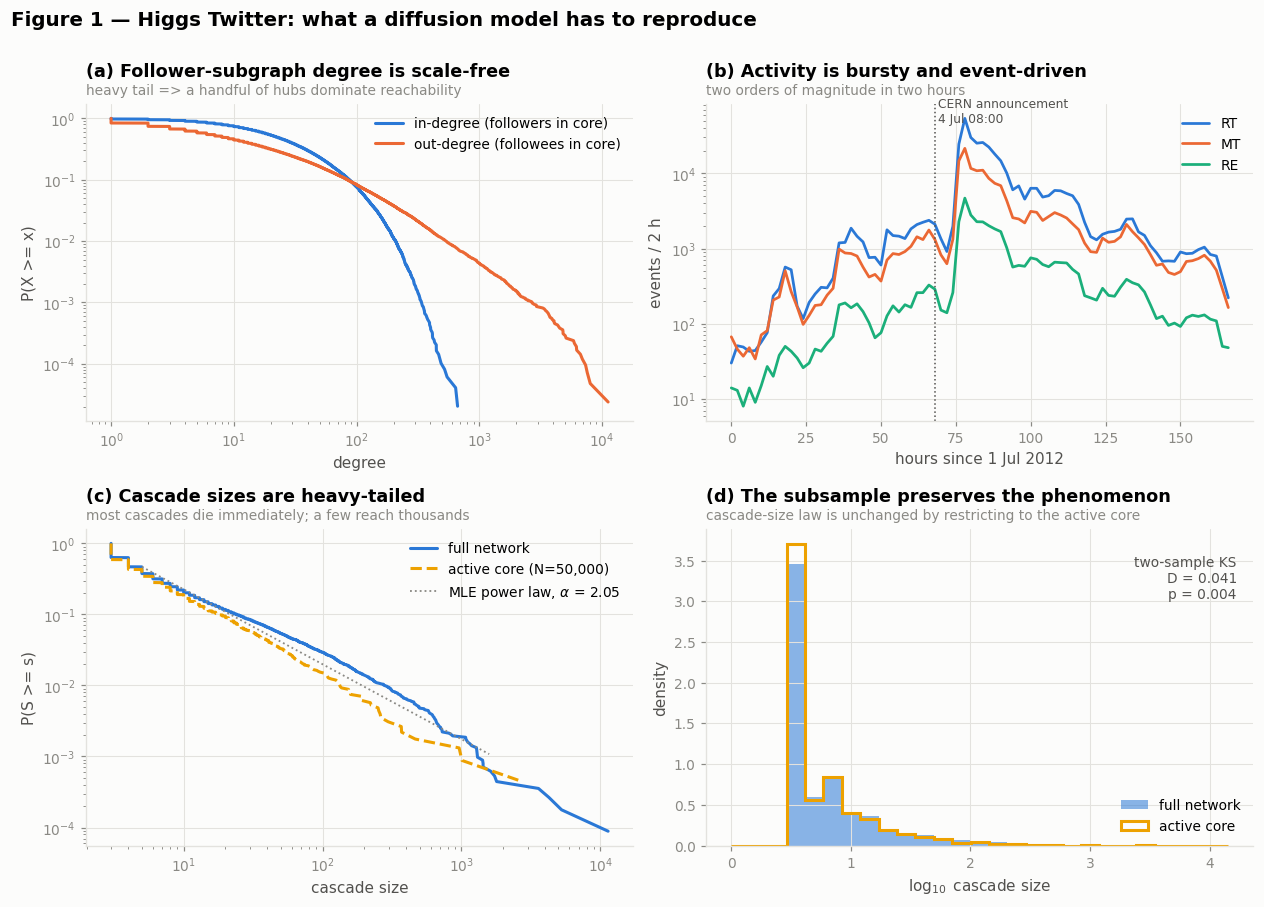

KS(full vs core) = 0.0405, p = 0.0039


In [11]:
# ---------------------------------------------------------------------------
# 1.3  Figure 1 - Higgs exploratory analysis
# ---------------------------------------------------------------------------
def ccdf(values):
    '''Empirical complementary CDF, the standard lens for heavy tails.'''
    v = np.sort(np.asarray(values))
    return v, 1.0 - np.arange(len(v)) / len(v)


fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.2))

# (a) degree distributions -------------------------------------------------
ax = axes[0, 0]
for deg, key, lab in [(G_higgs.in_deg, "observed", "in-degree (followers in core)"),
                      (G_higgs.out_deg, "ic", "out-degree (followees in core)")]:
    x, y = ccdf(deg[deg > 0])
    ax.loglog(x, y, color=STYLE[key]["color"], lw=2, label=lab)
finish(ax, "(a) Follower-subgraph degree is scale-free",
       "heavy tail => a handful of hubs dominate reachability",
       "degree", "P(X >= x)")

# (b) temporal signal ------------------------------------------------------
ax = axes[0, 1]
for kind, key in [("RT", "observed"), ("MT", "ic"), ("RE", "lt")]:
    sub = activity[activity["kind"] == kind]
    counts, edges = np.histogram(sub["hours"], bins=np.arange(0, 169, 2))
    ax.plot(edges[:-1], counts, color=STYLE[key]["color"], lw=1.8, label=kind)
ax.axvline(68, color=PALETTE["neutral"], lw=1.0, ls=":")
ax.text(69, ax.get_ylim()[1] * 0.85, "CERN announcement\n4 Jul 08:00",
        fontsize=8, color=PALETTE["neutral"])
ax.set_yscale("log")
finish(ax, "(b) Activity is bursty and event-driven",
       "two orders of magnitude in two hours", "hours since 1 Jul 2012", "events / 2 h")

# (c) cascade size CCDF ----------------------------------------------------
ax = axes[1, 0]
x, y = ccdf(sizes_full)
ax.loglog(x, y, color=PALETTE["observed"], lw=2, label="full network")
x2, y2 = ccdf(obs_sizes)
ax.loglog(x2, y2, color=PALETTE["gnn"], lw=2, ls="--", label=f"active core (N={N:,})")
# Fitted tail exponent (Hill / Clauset-Shalizi-Newman MLE) rather than a
# slope eyeballed onto the plot:  alpha = 1 + n / sum(ln x_i / x_min).
x_min = 5
tail = sizes_full[sizes_full >= x_min]
alpha = 1 + len(tail) / np.sum(np.log(tail / x_min))
xs = np.logspace(np.log10(x_min), 3.2, 50)
ref = (tail >= x_min).mean() * (xs / x_min) ** (1 - alpha)
ax.loglog(xs, ref * (sizes_full >= x_min).mean(), color=PALETTE["muted"], lw=1.2,
          ls=":", label=rf"MLE power law, $\alpha$ = {alpha:.2f}")
finish(ax, "(c) Cascade sizes are heavy-tailed",
       "most cascades die immediately; a few reach thousands",
       "cascade size", "P(S >= s)")

# (d) subsample validity ---------------------------------------------------
ax = axes[1, 1]
ks, pval = stats.ks_2samp(np.log10(sizes_full), np.log10(obs_sizes))
bins = np.linspace(0, np.log10(sizes_full.max()) + 0.1, 28)
ax.hist(np.log10(sizes_full), bins=bins, density=True, alpha=0.55,
        color=PALETTE["observed"], label="full network")
ax.hist(np.log10(obs_sizes), bins=bins, density=True, histtype="step", lw=2,
        color=PALETTE["gnn"], label="active core")
ax.text(0.97, 0.78, f"two-sample KS\nD = {ks:.3f}\np = {pval:.3f}",
        transform=ax.transAxes, ha="right", fontsize=9, color=PALETTE["neutral"])
finish(ax, "(d) The subsample preserves the phenomenon",
       "cascade-size law is unchanged by restricting to the active core",
       r"$\log_{10}$ cascade size", "density")

fig.suptitle("Figure 1 — Higgs Twitter: what a diffusion model has to reproduce",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "fig1_higgs_eda")
plt.show()
print(f"KS(full vs core) = {ks:.4f}, p = {pval:.4f}")

### 1.4 The baseline models

Both models are reimplemented from HW2 but **vectorised over the frontier** and
generalised to per-edge parameters:

**Independent Cascade.** At round $t$, each node $u$ activated at $t-1$ independently
activates each inactive out-neighbour $v$ with probability $p_{uv}$. Two
parameterisations:

* *uniform*: $p_{uv} = p$ (the HW2 version), one free parameter;
* *weighted cascade*: $p_{uv} = 1/d^{\text{in}}(v)$, zero free parameters — a node with
  many followees is correspondingly harder for any one of them to move.

**Linear Threshold.** Edge weights $w_{uv} = 1/d^{\text{in}}(v)$ (so
$\sum_u w_{uv} \le 1$), thresholds $\theta_v \sim \mathcal{U}(0, \tau)$. The scale
$\tau$ is the single free parameter; $\tau = 1$ is the textbook model.

Both return an **activation-time vector** (round index per node, $-1$ for never), which
is what lets us compare *velocity* and not merely final size.

In [12]:
# ---------------------------------------------------------------------------
# 1.4  Vectorised IC and LT
# ---------------------------------------------------------------------------
def independent_cascade(g, seeds, p=None, rng=None, max_rounds=100):
    '''Independent Cascade with per-edge probabilities.

    p : float          -> uniform IC with p_uv = p
        None           -> weighted cascade, p_uv = 1 / in_deg(v)
    Returns an int32 array of activation rounds (-1 = never activated).
    '''
    rng = rng or RNG
    times = np.full(g.n, -1, dtype=np.int32)
    seeds = np.atleast_1d(np.asarray(seeds, dtype=np.int64))
    times[seeds] = 0
    frontier = seeds
    for t in range(1, max_rounds + 1):
        if frontier.size == 0:
            break
        e = ragged_gather(g.indptr, frontier)          # candidate out-edges
        if e.size == 0:
            break
        targets = g.indices[e]
        pr = g.w_edge[e] if p is None else p           # per-edge success prob
        fired = rng.random(e.size) < pr
        cand = targets[fired]
        cand = cand[times[cand] < 0]                   # keep only inactive nodes
        if cand.size == 0:
            break
        frontier = np.unique(cand)
        times[frontier] = t
    return times


def linear_threshold(g, seeds, tau=1.0, rng=None, max_rounds=100, thresholds=None):
    '''Linear Threshold with 1/in-degree weights and U(0, tau) thresholds.

    Passing `thresholds` explicitly makes a run reproducible across models,
    which we use for the paired comparisons in Part 2.
    '''
    rng = rng or RNG
    theta = thresholds if thresholds is not None else rng.random(g.n) * tau
    accum = np.zeros(g.n, dtype=np.float32)
    times = np.full(g.n, -1, dtype=np.int32)
    seeds = np.atleast_1d(np.asarray(seeds, dtype=np.int64))
    times[seeds] = 0
    frontier = seeds
    for t in range(1, max_rounds + 1):
        if frontier.size == 0:
            break
        e = ragged_gather(g.indptr, frontier)
        if e.size == 0:
            break
        # Accumulate influence mass on the receiving side.
        np.add.at(accum, g.indices[e], g.w_edge[e])
        newly = np.where((accum >= theta) & (times < 0))[0]
        if newly.size == 0:
            break
        frontier = newly.astype(np.int64)
        times[frontier] = t
    return times


def cascade_from_times(times, root, step_hours=1.0):
    '''Wrap a simulated activation-time vector as a Cascade object.'''
    nodes = np.where(times >= 0)[0]
    t = times[nodes].astype(float) * step_hours
    order = np.argsort(t, kind="stable")
    nodes, t = nodes[order], t[order]
    return Cascade(root=int(root), nodes=nodes, times=t,
                   depth=int(times.max()), duration=float(t.max()))


# Smoke test: one large cascade, both models, from the same seed.
demo_seed = obs_cascades[0].root
for label, fn in [("IC p=0.01", lambda: independent_cascade(G_higgs, [demo_seed], p=0.01)),
                  ("IC weighted", lambda: independent_cascade(G_higgs, [demo_seed])),
                  ("LT tau=1.0", lambda: linear_threshold(G_higgs, [demo_seed], 1.0))]:
    tt = fn()
    print(f"{label:14s} -> size {int((tt>=0).sum()):6,d}   rounds {int(tt.max())}")
print(f"observed       -> size {obs_cascades[0].size:6,d}   "
      f"depth {obs_cascades[0].depth}")

IC p=0.01      -> size    384   rounds 11
IC weighted    -> size  3,469   rounds 28
LT tau=1.0     -> size  2,449   rounds 26
observed       -> size  2,770   depth 4


### 1.5 Calibration

The free parameter is fitted the way an empiricist would: **match the distribution, not
a point estimate**. For a candidate $p$ we simulate from every observed seed and score
the mismatch with the 1-Wasserstein distance between the two sets of
$\log_{10}(\text{size})$ values,

$$ \mathcal{L}(p) \;=\; W_1\!\left(\ \{\log_{10} S^{\text{obs}}_i\}_i,\ \ \{\log_{10} S^{\text{sim}}_i(p)\}_i\ \right), $$

which is sensitive to the whole tail rather than to the mean (the mean of a heavy-tailed
sample is nearly meaningless). Wasserstein also degrades gracefully, giving a smooth
objective over $p$ — visible as the clean U-shape in Figure 2.

In [13]:
# ---------------------------------------------------------------------------
# 1.5  Calibrate p (IC) and tau (LT) against the observed size distribution
# ---------------------------------------------------------------------------
def simulate_sizes(g, cascades, sim_fn, runs=1, rng=None):
    '''Simulate from every observed seed; return one size per (cascade, run).'''
    rng = rng or np.random.default_rng(SEED)
    out = np.empty(len(cascades) * runs, dtype=np.int64)
    k = 0
    for c in cascades:
        for _ in range(runs):
            out[k] = int((sim_fn(g, c.root, rng) >= 0).sum())
            k += 1
    return out


def w1_logsize(a, b):
    '''1-Wasserstein distance between log-size distributions.'''
    return stats.wasserstein_distance(np.log10(np.maximum(a, 1)),
                                      np.log10(np.maximum(b, 1)))


# Calibration uses a fixed random subsample of cascades so that the grid search
# is cheap and every grid point sees exactly the same seeds (paired comparison).
cal_rng = np.random.default_rng(SEED)
cal_idx = cal_rng.choice(len(obs_cascades), size=min(100, len(obs_cascades)),
                         replace=False)
cal_cascades = [obs_cascades[i] for i in cal_idx]
cal_obs_sizes = np.array([c.size for c in cal_cascades])

P_GRID = np.array([0.002, 0.004, 0.007, 0.01, 0.015, 0.02, 0.03,
                   0.05, 0.08, 0.12, 0.18, 0.25])
TAU_GRID = np.array([0.05, 0.1, 0.2, 0.3, 0.45, 0.6, 0.8, 1.0, 1.4, 2.0])

ic_curve, lt_curve = [], []
t0 = time.time()
for p in P_GRID:
    s = simulate_sizes(G_higgs, cal_cascades,
                       lambda g, r, rg, p=p: independent_cascade(g, [r], p=p, rng=rg),
                       runs=3, rng=np.random.default_rng(SEED))
    ic_curve.append(w1_logsize(cal_obs_sizes, s))
for tau in TAU_GRID:
    s = simulate_sizes(G_higgs, cal_cascades,
                       lambda g, r, rg, tau=tau: linear_threshold(g, [r], tau=tau, rng=rg),
                       runs=3, rng=np.random.default_rng(SEED))
    lt_curve.append(w1_logsize(cal_obs_sizes, s))

ic_curve, lt_curve = np.array(ic_curve), np.array(lt_curve)
P_STAR = float(P_GRID[ic_curve.argmin()])
TAU_STAR = float(TAU_GRID[lt_curve.argmin()])
print(f"calibration took {time.time()-t0:.1f}s")
print(f"IC  p*   = {P_STAR:<6g}  (W1 = {ic_curve.min():.4f})")
print(f"LT  tau* = {TAU_STAR:<6g}  (W1 = {lt_curve.min():.4f})")

# Weighted cascade has no free parameter -- report it for reference.
wc_sizes = simulate_sizes(G_higgs, cal_cascades,
                          lambda g, r, rg: independent_cascade(g, [r], p=None, rng=rg),
                          runs=3, rng=np.random.default_rng(SEED))
print(f"IC  weighted-cascade (no free parameter): W1 = "
      f"{w1_logsize(cal_obs_sizes, wc_sizes):.4f}")

calibration took 140.7s
IC  p*   = 0.007   (W1 = 0.3357)
LT  tau* = 2       (W1 = 0.2895)
IC  weighted-cascade (no free parameter): W1 = 0.4722


### 1.6 Evaluation

Four complementary statistics, each with a bootstrap confidence interval over cascades:

| Metric | What it catches |
|---|---|
| $W_1(\log S)$ | whole-distribution mismatch in cascade size |
| KS statistic $D$ | worst-case mismatch at any single size |
| $\Delta$ median depth | structural error — wide-and-shallow vs narrow-and-deep |
| $\Delta t_{50}$ | **velocity** error: normalised time to reach half the final size |

$t_{50}$ is the project's headline metric — the proposal's "how fast information spreads"
— and it is the one where the gap between the models and reality is largest.

In [14]:
# ---------------------------------------------------------------------------
# 1.6  Metric suite (reused verbatim for Reddit and MemeTracker)
# ---------------------------------------------------------------------------
def t50(cascade):
    '''Normalised time at which a cascade reaches half its final size.'''
    if cascade.duration <= 0 or cascade.size < 2:
        return 0.0
    half = math.ceil(cascade.size / 2)
    return float(cascade.times[half - 1] / cascade.duration)


def summarise(cascades):
    '''Reduce a list of cascades to the vector of statistics we score on.'''
    return {
        "size": np.array([c.size for c in cascades], dtype=float),
        "depth": np.array([c.depth for c in cascades], dtype=float),
        "t50": np.array([t50(c) for c in cascades], dtype=float),
        "curve": np.array([c.adoption_curve() for c in cascades], dtype=float),
    }


def score(obs, sim, n_boot=None):
    '''Compare simulated cascades against observed ones, with bootstrap CIs.'''
    n_boot = n_boot or CONFIG["bootstrap"]
    o, s = summarise(obs), summarise(sim)
    rng = np.random.default_rng(SEED)

    def boot(fn):
        vals = [fn(rng.integers(0, len(o["size"]), len(o["size"])),
                   rng.integers(0, len(s["size"]), len(s["size"])))
                for _ in range(n_boot)]
        return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

    w1 = w1_logsize(o["size"], s["size"])
    ks = float(stats.ks_2samp(np.log10(o["size"]), np.log10(s["size"])).statistic)
    d_depth = float(np.median(s["depth"]) - np.median(o["depth"]))
    # The MEDIAN t50 of round-based simulations collapses onto 0.5 whenever
    # cascades are small (a 4-node, 2-round cascade can only have t50 in
    # {0, 0.5, 1}), so it mostly measures the observed side.  We therefore
    # report the mean as well and treat curve_L1 as the primary velocity
    # statistic.
    d_t50 = float(np.median(s["t50"]) - np.median(o["t50"]))
    d_t50_mean = float(np.mean(s["t50"]) - np.mean(o["t50"]))
    curve_l1 = float(np.abs(o["curve"].mean(0) - s["curve"].mean(0)).mean())

    w1_lo, w1_hi = boot(lambda i, j: w1_logsize(o["size"][i], s["size"][j]))
    t_lo, t_hi = boot(lambda i, j: np.median(s["t50"][j]) - np.median(o["t50"][i]))
    return {
        "W1_logsize": w1, "W1_lo": w1_lo, "W1_hi": w1_hi,
        "KS": ks,
        "median_size_obs": float(np.median(o["size"])),
        "median_size_sim": float(np.median(s["size"])),
        "d_median_depth": d_depth,
        "d_t50": d_t50, "d_t50_lo": t_lo, "d_t50_hi": t_hi,
        "d_t50_mean": d_t50_mean,
        "curve_L1": curve_l1,
    }


def run_model(g, cascades, sim_fn, runs=1, seed=SEED):
    '''Simulate one cascade per observed seed and wrap the results.'''
    rng = np.random.default_rng(seed)
    out = []
    for c in cascades:
        for _ in range(runs):
            times = sim_fn(g, c.root, rng)
            if (times >= 0).sum() >= 2:
                out.append(cascade_from_times(times, c.root))
    return out


EVAL = [obs_cascades[i] for i in
        np.random.default_rng(SEED + 1).choice(
            len(obs_cascades), size=min(300, len(obs_cascades)), replace=False)]

higgs_sims = {
    "ic": run_model(G_higgs, EVAL,
                    lambda g, r, rg: independent_cascade(g, [r], p=P_STAR, rng=rg), runs=2),
    "lt": run_model(G_higgs, EVAL,
                    lambda g, r, rg: linear_threshold(g, [r], tau=TAU_STAR, rng=rg), runs=2),
}
higgs_scores = {k: score(EVAL, v) for k, v in higgs_sims.items()}

higgs_table = pd.DataFrame(higgs_scores).T[
    ["W1_logsize", "KS", "median_size_obs", "median_size_sim",
     "d_median_depth", "d_t50", "d_t50_mean", "curve_L1"]]
higgs_table.index = [LABEL[k] for k in higgs_table.index]
print(f"Observed median t50 = {np.median([t50(c) for c in EVAL]):.3f}")
higgs_table.round(3)

Observed median t50 = 0.048


,W1_logsize,KS,median_size_obs,median_size_sim,d_median_depth,d_t50,d_t50_mean,curve_L1
Independent Cascade,0.076,0.294,4.0,4.0,-1.0,0.452,0.274,0.178
Linear Threshold,0.130,0.243,4.0,5.0,-1.0,0.452,0.322,0.203


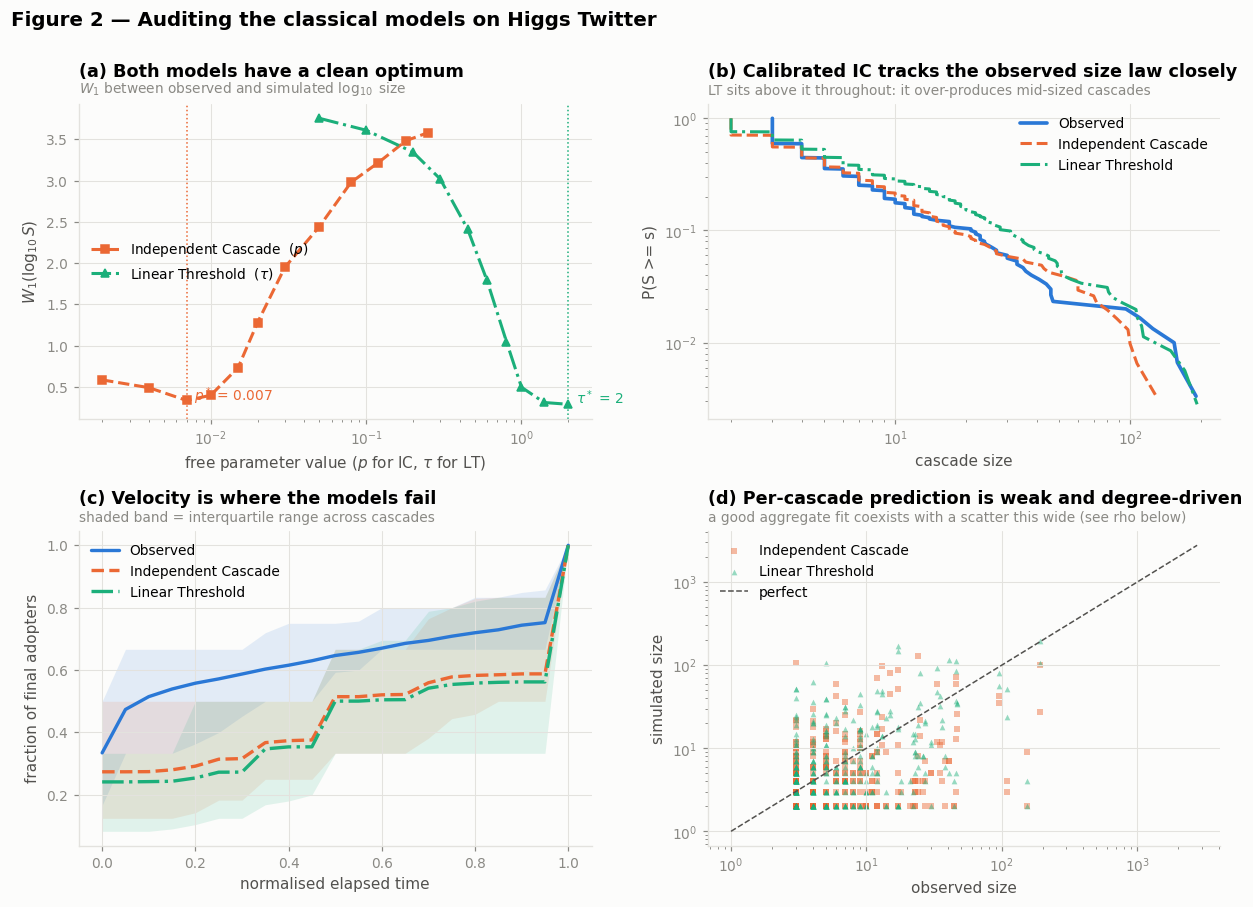

In [15]:
# ---------------------------------------------------------------------------
# 1.6b  Figure 2 - how well do the classical models do?
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.2))

# (a) calibration landscape -------------------------------------------------
ax = axes[0, 0]
# Both curves share one y-axis (W1) and one x-axis (the free parameter, which is
# dimensionless in both models) -- deliberately NOT a twin-axis chart.
ax.plot(P_GRID, ic_curve, **{**STYLE["ic"], "markersize": 5},
        label=LABEL["ic"] + r"  ($p$)")
ax.plot(TAU_GRID, lt_curve, **{**STYLE["lt"], "markersize": 5},
        label=LABEL["lt"] + r"  ($\tau$)")
ax.set_xscale("log")
lo, hi = ax.get_ylim()
for val, key, name in [(P_STAR, "ic", "p^*"), (TAU_STAR, "lt", r"\tau^*")]:
    ax.axvline(val, color=PALETTE[key], lw=1, ls=":")
    # Anchor the annotation near the floor, where neither curve nor legend sits.
    ax.annotate(rf"${name}$ = {val:g}", (val, lo + 0.04 * (hi - lo)),
                textcoords="offset points", xytext=(5, 0),
                fontsize=9, color=PALETTE[key], va="bottom")
finish(ax, "(a) Both models have a clean optimum",
       r"$W_1$ between observed and simulated $\log_{10}$ size",
       r"free parameter value ($p$ for IC, $\tau$ for LT)", r"$W_1(\log_{10} S)$",
       legend=False)
ax.legend(loc="center left")

# (b) size CCDF -------------------------------------------------------------
ax = axes[0, 1]
x, y = ccdf([c.size for c in EVAL])
ax.loglog(x, y, color=PALETTE["observed"], lw=2.4, label=LABEL["observed"])
for key in ["ic", "lt"]:
    x, y = ccdf([c.size for c in higgs_sims[key]])
    ax.loglog(x, y, color=STYLE[key]["color"], lw=2, ls=STYLE[key]["linestyle"],
              label=LABEL[key])
finish(ax, "(b) Calibrated IC tracks the observed size law closely",
       "LT sits above it throughout: it over-produces mid-sized cascades",
       "cascade size", "P(S >= s)")

# (c) normalised adoption curves -------------------------------------------
ax = axes[1, 0]
grid = np.linspace(0, 1, 21)
for key, cs in [("observed", EVAL), ("ic", higgs_sims["ic"]), ("lt", higgs_sims["lt"])]:
    curves = np.array([c.adoption_curve() for c in cs])
    mu = curves.mean(0)
    lo, hi = np.percentile(curves, [25, 75], axis=0)
    ax.plot(grid, mu, color=STYLE[key]["color"], lw=2.2,
            ls=STYLE[key]["linestyle"], label=LABEL[key])
    ax.fill_between(grid, lo, hi, color=STYLE[key]["color"], alpha=0.12, lw=0)
finish(ax, "(c) Velocity is where the models fail",
       "shaded band = interquartile range across cascades",
       "normalised elapsed time", "fraction of final adopters")

# (d) per-cascade accuracy --------------------------------------------------
ax = axes[1, 1]
obs_by_root = {c.root: c.size for c in EVAL}
for key in ["ic", "lt"]:
    xs, ys = [], []
    for c in higgs_sims[key]:
        if c.root in obs_by_root:
            xs.append(obs_by_root[c.root]); ys.append(c.size)
    ax.scatter(xs, ys, s=14, alpha=0.45, color=STYLE[key]["color"],
               marker=STYLE[key]["marker"], linewidths=0, label=LABEL[key])
lim = [1, max(obs_sizes.max(), 10)]
ax.plot(lim, lim, color=PALETTE["neutral"], lw=1, ls="--", label="perfect")
ax.set_xscale("log"); ax.set_yscale("log")
finish(ax, "(d) Per-cascade prediction is weak and degree-driven",
       "a good aggregate fit coexists with a scatter this wide (see rho below)",
       "observed size", "simulated size")

fig.suptitle("Figure 2 — Auditing the classical models on Higgs Twitter",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "fig2_higgs_baseline")
plt.show()

In [16]:
# ---------------------------------------------------------------------------
# 1.6c  Per-cascade correlation: the number behind panel (d)
# ---------------------------------------------------------------------------
# Aggregate distributional agreement is a weak test -- a model can reproduce the
# size law while being uninformative about *which* seed produces a large
# cascade.  Spearman rank correlation between observed and simulated size per
# seed separates the two claims.
for key in ["ic", "lt"]:
    pairs = [(obs_by_root[c.root], c.size) for c in higgs_sims[key]
             if c.root in obs_by_root]
    a, b = np.array(pairs).T
    rho, pv = stats.spearmanr(a, b)
    r2 = stats.pearsonr(np.log10(a), np.log10(b))[0] ** 2
    print(f"{LABEL[key]:22s} Spearman rho = {rho:+.3f} (p={pv:.1e})   "
          f"R^2(log-log) = {r2:.3f}")

HIGGS_SUMMARY = higgs_table.copy()

# ---------------------------------------------------------------------------
# The verdict is assembled from the measured numbers, so it cannot drift out
# of sync with the results if the configuration changes.
# ---------------------------------------------------------------------------
obs_t50 = float(np.median([t50(c) for c in EVAL]))
print()
print("RQ1 verdict (Higgs Twitter)")
for key in ["ic", "lt"]:
    sc = higgs_scores[key]
    pairs = np.array([(obs_by_root[c.root], c.size) for c in higgs_sims[key]
                      if c.root in obs_by_root])
    rho = stats.spearmanr(pairs[:, 0], pairs[:, 1]).statistic
    med_ratio = sc["median_size_sim"] / max(sc["median_size_obs"], 1e-9)
    bias = ("matches" if 0.8 <= med_ratio <= 1.25
            else ("over-predicts" if med_ratio > 1.25 else "under-predicts"))
    print(f"  {LABEL[key]:20s} W1 {sc['W1_logsize']:.3f} "
          f"[{sc['W1_lo']:.3f}, {sc['W1_hi']:.3f}]   "
          f"median size {bias} ({med_ratio:.2f}x)   "
          f"rho {rho:+.3f}   dt50 {sc['d_t50']:+.3f}")
print(f"  observed median t50 = {obs_t50:.3f}: real cascades reach half their final "
      f"size in the\n  first {obs_t50:.0%} of their lifetime, while round-uniform "
      f"simulation puts it near 50%.")

Independent Cascade    Spearman rho = +0.294 (p=1.6e-07)   R^2(log-log) = 0.094
Linear Threshold       Spearman rho = +0.347 (p=1.8e-11)   R^2(log-log) = 0.186

RQ1 verdict (Higgs Twitter)
  Independent Cascade  W1 0.076 [0.073, 0.125]   median size matches (1.00x)   rho +0.294   dt50 +0.452
  Linear Threshold     W1 0.130 [0.082, 0.184]   median size matches (1.25x)   rho +0.347   dt50 +0.452
  observed median t50 = 0.048: real cascades reach half their final size in the
  first 5% of their lifetime, while round-uniform simulation puts it near 50%.


---
---
# Part 2 — RQ2: Learning the diffusion operator with a GNN

Part 1 left two concrete openings. First, the classical models' per-seed skill is
**modest and almost entirely structural** — their simulated cascade size tracks observed
size mainly because both grow with the seed's degree, which is information the models
inherit from the graph rather than derive from their activation rule. Second, their
velocity error is **structural, not parametric**: no value of $p$ or $\tau$ reshapes a
round-uniform process into the sharply front-loaded curve the data shows.

A learned operator attacks exactly the first gap: it gets to condition on *who* the
seed is and *how its neighbourhood is wired*, not just on a single scalar. The bar it
has to clear is therefore not "chance" but **the calibrated classical models *and* a
degree/PageRank control**. Those controls are not a formality: they are strong, and we
report the cases where they win. Note that the two questions can disagree — a hub is an
excellent *seed* and a poor *adopter* — so a model can dominate one ranking while
losing the other, and we evaluate both rather than picking the flattering one.

### 2.1 Problem formulation

Fix the substrate $G=(V,E)$. For an observed cascade $c$ with seed $s_c$, define the
label $y^c_v = \mathbb{1}[v \text{ adopted in } c]$. We learn

$$ f_\theta:\ \big(G,\ s_c,\ X\big)\ \longmapsto\ \hat{p}^c_v = \Pr[y^c_v = 1] $$

where $X$ are static structural features. This is **not** a reimplementation of IC with
learned $p$; it is a direct function approximation of the *marginal activation
probability field* that an IC/LT run would have to be Monte-Carlo'd to obtain.

**Receptive field.** Running a GNN over all 50k nodes for each of hundreds of cascades
is wasteful: a cascade seeded at $s$ is supported almost entirely on $s$'s 2-hop
neighbourhood. We therefore train on **ego-subgraphs**: the (capped) 2-hop
out-neighbourhood of the seed, with hop-1 always complete before hop-2 is subsampled.
Subgraphs are **block-diagonally batched** into one sparse tensor per minibatch, which
is what makes CPU training feasible.

> **A leak we had to remove.** Our first version force-included every observed adopter
> in the receptive field so that no positive was "lost". That silently leaks the label:
> a node that the BFS never reached is present *only because it adopted*, and the model
> learns that tell instead of learning diffusion (it drove held-out AUC to 0.998 on the
> sparsest substrate — the classic too-good-to-be-true signature). The field is now
> defined purely by the substrate, and we report what fraction of true adopters it
> covers instead of quietly repairing it.

**Negatives.** Every non-adopting node inside the receptive field is a negative. This is
the hard version of the task — the model cannot win by learning "far away $\Rightarrow$
no" — and class imbalance is handled with a positive-weighted BCE loss.

### 2.2 Architecture

A 3-layer GCN written directly against `torch.sparse`, so every operation is visible:

$$ H^{(\ell+1)} \;=\; \mathrm{Drop}\Big(\mathrm{LN}\big(\sigma(\hat{A} H^{(\ell)} W^{(\ell)})\big)\Big) \;+\; H^{(\ell)}, \qquad \hat{A} = \tilde{D}^{-1/2}(A + A^\top + I)\tilde{D}^{-1/2} $$

with residual connections (so depth does not destroy the seed signal) and LayerNorm
(cascade subgraphs vary in size by two orders of magnitude, and unnormalised
activations scale with degree). Dropout is kept **active at inference** for MC-dropout
uncertainty — we report predictive intervals, not point estimates.

In [17]:
# ---------------------------------------------------------------------------
# 2.1  Static structural features
# ---------------------------------------------------------------------------
import torch
import torch.nn as nn
import torch.nn.functional as F
import scipy.sparse as sp

torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)


def scipy_adj(g):
    '''CSR graph -> scipy sparse adjacency (influence direction u -> v).'''
    rows = np.repeat(np.arange(g.n), g.out_deg)
    return sp.csr_matrix((np.ones(g.m, np.float32), (rows, g.indices)),
                         shape=(g.n, g.n))


def pagerank_power(A, alpha=0.85, iters=60, tol=1e-9):
    '''PageRank by power iteration on the scipy adjacency.

    networkx would take minutes on a million-edge graph; this is ~1 second and
    is the identical fixed point, dangling mass included.
    '''
    n = A.shape[0]
    out = np.asarray(A.sum(axis=1)).ravel()
    dangling = out == 0
    P = sp.diags(np.where(dangling, 0.0, 1.0 / np.maximum(out, 1))) @ A
    r = np.full(n, 1.0 / n)
    for _ in range(iters):
        r_new = alpha * (P.T @ r) + alpha * r[dangling].sum() / n + (1 - alpha) / n
        if np.abs(r_new - r).sum() < tol:
            r = r_new
            break
        r = r_new
    return r / r.sum()


def structural_features(g):
    '''Six graph-intrinsic features per node, standardised.

    All are cheap and *global*: they describe where a node sits in the network
    irrespective of any particular cascade.  The cascade-specific signal
    (seed indicator, hop distance) is appended per-sample later.
    '''
    A = scipy_adj(g)
    pr = pagerank_power(A)
    # Sum of neighbours' out-degrees: a cheap, dense-free proxy for 2-hop reach.
    # (Materialising A @ A would be a 12k x 12k near-dense matrix.)
    two_hop = A @ g.out_deg.astype(np.float32)
    # Mean out-degree of my out-neighbours: distinguishes hubs that point at
    # other hubs from hubs that point at leaves.
    nbr_mean_out = two_hop / np.maximum(g.out_deg, 1)
    feats = np.column_stack([
        np.log1p(g.in_deg),
        np.log1p(g.out_deg),
        np.log1p(pr * g.n),
        np.log1p(two_hop),
        np.log1p(nbr_mean_out),
        g.in_deg / np.maximum(g.in_deg + g.out_deg, 1),     # in/out balance
    ]).astype(np.float32)
    feats = (feats - feats.mean(0)) / (feats.std(0) + 1e-6)
    return feats, A, pr


t0 = time.time()
X_STATIC, A_HIGGS, PR_HIGGS = structural_features(G_higgs)
print(f"structural features {X_STATIC.shape} in {time.time()-t0:.1f}s")
print(f"top-5 PageRank nodes have out-degree "
      f"{G_higgs.out_deg[np.argsort(-PR_HIGGS)[:5]]}")

torch 2.2.2 | device: cpu


structural features (50000, 6) in 0.3s
top-5 PageRank nodes have out-degree [296 246 271 282 382]


In [18]:
# ---------------------------------------------------------------------------
# 2.2  Ego-subgraph extraction and block-diagonal batching
# ---------------------------------------------------------------------------
@dataclass
class Sample:
    '''One cascade rendered as a trainable graph.'''
    x: np.ndarray        # [n_local, F] node features
    ei: np.ndarray       # [2, n_edges] local edge index
    y: np.ndarray        # [n_local] binary adoption labels
    nodes: np.ndarray    # local -> global node ids
    root_local: int
    obs_size: int
    coverage: float = 1.0   # fraction of the true adopters inside the field


def extract_ego(g, seed, hops=2, max_nodes=1600, rng=None):
    '''Capped BFS ego-subgraph around `seed` -- the model's receptive field.

    Capping is by uniform sampling within a hop ring rather than by truncating
    the ring, which keeps the degree distribution of the frontier unbiased.
    Rings are filled in order, so hop 1 is always complete before hop 2 is
    sampled.

    IMPORTANT: observed adopters are deliberately NOT force-included.  An
    earlier version of this code injected them to avoid "losing" positives,
    which leaked the label: a force-included node is reachable only by being a
    positive, and the model learns that tell instead of learning diffusion.
    Adopters the substrate cannot reach in `hops` steps are therefore outside
    the receptive field by construction, and we report that coverage openly
    rather than papering over it.
    '''
    rng = rng or np.random.default_rng(SEED)
    seen = {int(seed): 0}
    frontier = np.array([seed], dtype=np.int64)
    for h in range(1, hops + 1):
        if frontier.size == 0 or len(seen) >= max_nodes:
            break
        e = ragged_gather(g.indptr, frontier)
        if e.size == 0:
            break
        nxt = np.unique(g.indices[e])
        nxt = np.array([u for u in nxt if u not in seen], dtype=np.int64)
        budget = max_nodes - len(seen)
        if nxt.size > budget:
            nxt = rng.choice(nxt, size=budget, replace=False)
        for u in nxt:
            seen[int(u)] = h
        frontier = nxt
    # `nodes` is sorted, so np.searchsorted is an O(log n) global -> local map
    # and we never need a Python dict in the hot path.
    nodes = np.array(sorted(seen), dtype=np.int64)
    hop = np.array([seen[int(u)] for u in nodes], dtype=np.float32)

    # Induced edge list.
    e = ragged_gather(g.indptr, nodes)
    src_g = np.repeat(nodes, g.indptr[nodes + 1] - g.indptr[nodes])
    dst_g = g.indices[e].astype(np.int64)
    inside = np.isin(dst_g, nodes, assume_unique=False)
    src_l = np.searchsorted(nodes, src_g[inside])
    dst_l = np.searchsorted(nodes, dst_g[inside])
    return nodes, hop, np.vstack([src_l, dst_l])


def make_sample(g, cascade, x_static, hops=2, max_nodes=1600, rng=None):
    nodes, hop, ei = extract_ego(g, cascade.root, hops, max_nodes, rng)
    y = np.zeros(len(nodes), dtype=np.float32)
    # Label only the adopters the receptive field actually reached.
    cn = np.asarray(cascade.nodes)
    idx = np.clip(np.searchsorted(nodes, cn), 0, len(nodes) - 1)
    pos = idx[nodes[idx] == cn]          # adopters that fell inside the field
    y[pos] = 1.0
    coverage = float(len(pos) / max(cascade.size, 1))
    local_in = np.bincount(ei[1], minlength=len(nodes)).astype(np.float32)
    local_out = np.bincount(ei[0], minlength=len(nodes)).astype(np.float32)
    root_local = int(np.searchsorted(nodes, cascade.root))
    seed_flag = np.zeros(len(nodes), dtype=np.float32); seed_flag[root_local] = 1.0
    x = np.column_stack([
        x_static[nodes],                 # 6 global structural features
        seed_flag,                       # cascade-specific: is this the seed?
        np.minimum(hop, hops) / hops,    # cascade-specific: hop distance
        np.log1p(local_in),              # local connectivity inside the ego net
        np.log1p(local_out),
    ]).astype(np.float32)
    return Sample(x=x, ei=ei, y=y, nodes=nodes, root_local=root_local,
                  obs_size=cascade.size, coverage=coverage)


def collate(samples):
    '''Block-diagonal batching: B subgraphs become one disconnected graph.

    This is the trick that makes CPU training practical -- one sparse matmul
    per layer per *batch* instead of per sample.
    '''
    xs, ys, eis, offs, roots, graph_id = [], [], [], [], [], []
    off = 0
    for i, s in enumerate(samples):
        xs.append(s.x); ys.append(s.y)
        eis.append(s.ei + off)
        roots.append(s.root_local + off)
        graph_id.append(np.full(len(s.y), i, dtype=np.int64))
        offs.append(off)
        off += len(s.y)
    x = torch.from_numpy(np.concatenate(xs))
    y = torch.from_numpy(np.concatenate(ys))
    ei = torch.from_numpy(np.concatenate(eis, axis=1))
    gid = torch.from_numpy(np.concatenate(graph_id))
    return x, ei, y, gid, off


def normalized_adj(ei, n, device):
    '''Symmetric GCN normalisation of A + A^T + I as a sparse tensor.

    We symmetrise because influence in a follower network is mediated in both
    directions (a node is informative about its followees as well as its
    followers); the directed signal survives in the in/out degree features.
    '''
    src, dst = ei[0], ei[1]
    loop = torch.arange(n, dtype=torch.long)
    r = torch.cat([src, dst, loop])
    c = torch.cat([dst, src, loop])
    v = torch.ones(r.numel(), dtype=torch.float32)
    deg = torch.zeros(n, dtype=torch.float32).index_add_(0, r, v)
    dinv = deg.pow(-0.5); dinv[torch.isinf(dinv)] = 0
    vals = dinv[r] * v * dinv[c]
    return torch.sparse_coo_tensor(torch.stack([r, c]), vals, (n, n)).coalesce().to(device)


print("sample construction ready")

sample construction ready


In [19]:
# ---------------------------------------------------------------------------
# 2.3  The model
# ---------------------------------------------------------------------------
class GCNLayer(nn.Module):
    '''A single message-passing step: H' = A_hat @ H @ W.'''

    def __init__(self, d_in, d_out):
        super().__init__()
        self.lin = nn.Linear(d_in, d_out)
        nn.init.xavier_uniform_(self.lin.weight, gain=nn.init.calculate_gain("relu"))
        nn.init.zeros_(self.lin.bias)

    def forward(self, A, h):
        return torch.sparse.mm(A, self.lin(h))


class DiffusionGNN(nn.Module):
    '''Predicts per-node adoption probability for a seeded cascade.

    Design notes:
      * residual connections keep the seed indicator from being diffused away
        by repeated averaging (classic over-smoothing);
      * LayerNorm because ego-subgraph sizes span 10^1 to 10^3 nodes;
      * dropout stays ON at inference time for MC-dropout uncertainty.
    '''

    def __init__(self, d_in, hidden=64, layers=3, dropout=0.25):
        super().__init__()
        self.inp = nn.Linear(d_in, hidden)
        self.convs = nn.ModuleList([GCNLayer(hidden, hidden) for _ in range(layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(layers)])
        self.head = nn.Sequential(nn.Linear(hidden, hidden // 2), nn.ReLU(),
                                  nn.Linear(hidden // 2, 1))
        self.dropout = dropout

    def forward(self, A, x):
        h = F.relu(self.inp(x))
        for conv, norm in zip(self.convs, self.norms):
            m = F.relu(norm(conv(A, h)))
            m = F.dropout(m, self.dropout, training=True)   # always on: MC dropout
            h = h + m                                       # residual
        return self.head(h).squeeze(-1)                     # logits


D_IN = 10
model = DiffusionGNN(D_IN, CONFIG["gnn_hidden"], CONFIG["gnn_layers"],
                     CONFIG["gnn_dropout"]).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"{n_params:,} trainable parameters")

DiffusionGNN(
  (inp): Linear(in_features=10, out_features=64, bias=True)
  (convs): ModuleList(
    (0-2): 3 x GCNLayer(
      (lin): Linear(in_features=64, out_features=64, bias=True)
    )
  )
  (norms): ModuleList(
    (0-2): 3 x LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
15,681 trainable parameters


In [20]:
# ---------------------------------------------------------------------------
# 2.4  Build the dataset (split by cascade, never by node)
# ---------------------------------------------------------------------------
# Splitting by cascade is essential: a node-level split would leak, because the
# same node appears in many cascades and the model could memorise its base rate
# instead of learning how influence propagates.
rng_ds = np.random.default_rng(SEED)
MAXN = CONFIG["gnn_sample_nodes"]
pool = [c for c in obs_cascades if c.size >= 4][:CONFIG["gnn_pool"]]
rng_ds.shuffle(pool)

t0 = time.time()
samples = [make_sample(G_higgs, c, X_STATIC, hops=2, max_nodes=MAXN, rng=rng_ds)
           for c in pool]
cov_all = np.array([s.coverage for s in samples])
samples = [s for s in samples if 8 <= len(s.y) <= MAXN and s.y.sum() >= 2]
print(f"built {len(samples)} usable samples from {len(pool)} cascades "
      f"in {time.time()-t0:.1f}s")
print(f"receptive-field coverage of true adopters: mean {cov_all.mean():.1%}, "
      f"median {np.median(cov_all):.1%}")
print("  (adopters outside the seed's 2-hop field are unreachable under the "
      "substrate\n   and are excluded from BOTH the labels and the metrics)")

n_tr = int(0.70 * len(samples)); n_va = int(0.15 * len(samples))
train_s, val_s, test_s = samples[:n_tr], samples[n_tr:n_tr + n_va], samples[n_tr + n_va:]
print(f"train/val/test cascades: {len(train_s)}/{len(val_s)}/{len(test_s)}")

all_y = np.concatenate([s.y for s in samples])
pos_rate = all_y.mean()
print(f"nodes per sample: median {np.median([len(s.y) for s in samples]):.0f}  "
      f"max {max(len(s.y) for s in samples)}")
print(f"positive rate: {pos_rate:.3%}  ->  pos_weight = {(1-pos_rate)/pos_rate:.1f}")
POS_WEIGHT = torch.tensor(min((1 - pos_rate) / pos_rate, 50.0))

built 583 usable samples from 600 cascades in 5.5s
receptive-field coverage of true adopters: mean 61.7%, median 63.6%
  (adopters outside the seed's 2-hop field are unreachable under the substrate
   and are excluded from BOTH the labels and the metrics)
train/val/test cascades: 408/87/88
nodes per sample: median 1500  max 1500
positive rate: 1.056%  ->  pos_weight = 93.7


In [21]:
# ---------------------------------------------------------------------------
# 2.5  Training loop
# ---------------------------------------------------------------------------
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

def batches(samples, bs, shuffle=True, rng=None):
    idx = np.arange(len(samples))
    if shuffle:
        (rng or np.random.default_rng(SEED)).shuffle(idx)
    for i in range(0, len(idx), bs):
        yield [samples[j] for j in idx[i:i + bs]]


@torch.no_grad()
def evaluate(model, samples, bs=24, passes=1):
    '''Mean predicted probability over `passes` MC-dropout forward passes.'''
    ys, ps = [], []
    for chunk in batches(samples, bs, shuffle=False):
        x, ei, y, gid, n = collate(chunk)
        A = normalized_adj(ei, n, DEVICE)
        acc = torch.zeros(n, device=DEVICE)
        for _ in range(passes):
            acc += torch.sigmoid(model(A, x.to(DEVICE)))
        ys.append(y.numpy()); ps.append((acc / passes).cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps)


opt = torch.optim.AdamW(model.parameters(), lr=CONFIG["gnn_lr"], weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CONFIG["gnn_epochs"])
crit = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT.to(DEVICE))

history = {"epoch": [], "train_loss": [], "val_loss": [], "val_auc": [], "val_ap": []}
best = {"auc": -1, "state": None, "epoch": 0}
BS, EPOCHS, PATIENCE = 16, CONFIG["gnn_epochs"], 20
rng_tr = np.random.default_rng(SEED)

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    tot, nb = 0.0, 0
    for chunk in batches(train_s, BS, rng=rng_tr):
        x, ei, y, gid, n = collate(chunk)
        A = normalized_adj(ei, n, DEVICE)
        opt.zero_grad()
        loss = crit(model(A, x.to(DEVICE)), y.to(DEVICE))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        opt.step()
        tot += float(loss); nb += 1
    sched.step()

    model.eval()
    yv, pv = evaluate(model, val_s, passes=1)
    vloss = float(F.binary_cross_entropy(torch.tensor(pv).clamp(1e-6, 1 - 1e-6),
                                         torch.tensor(yv)))
    auc = roc_auc_score(yv, pv); ap = average_precision_score(yv, pv)
    history["epoch"].append(epoch); history["train_loss"].append(tot / max(nb, 1))
    history["val_loss"].append(vloss); history["val_auc"].append(auc)
    history["val_ap"].append(ap)

    if auc > best["auc"]:
        best = {"auc": auc, "state": {k: v.detach().clone()
                                      for k, v in model.state_dict().items()},
                "epoch": epoch}
    if epoch - best["epoch"] >= PATIENCE:
        print(f"early stop at epoch {epoch} (best epoch {best['epoch']})")
        break
    if epoch % 10 == 0 or epoch == 1:
        print(f"epoch {epoch:3d}  train {tot/max(nb,1):.4f}  val {vloss:.4f}  "
              f"AUC {auc:.4f}  AP {ap:.4f}")

model.load_state_dict(best["state"])
print(f"\ntrained in {time.time()-t0:.1f}s; best val AUC {best['auc']:.4f} "
      f"@ epoch {best['epoch']}")

epoch   1  train 0.9040  val 0.4179  AUC 0.7465  AP 0.0463


epoch  10  train 0.7095  val 0.2148  AUC 0.8577  AP 0.1662


epoch  20  train 0.6944  val 0.3365  AUC 0.8664  AP 0.1678


epoch  30  train 0.6956  val 0.3576  AUC 0.8681  AP 0.1683


epoch  40  train 0.6982  val 0.3156  AUC 0.8695  AP 0.1682


epoch  50  train 0.6621  val 0.3224  AUC 0.8721  AP 0.1703


epoch  60  train 0.6656  val 0.3216  AUC 0.8727  AP 0.1686


epoch  70  train 0.6672  val 0.3167  AUC 0.8721  AP 0.1698

trained in 320.7s; best val AUC 0.8739 @ epoch 65


### 2.6 The honest baseline

Comparing the GNN against "chance" would be meaningless. The fair baselines are the
models from Part 1, asked the *same* question: for each node in the receptive field,
what is the probability it adopts?

* **IC / LT**: Monte-Carlo the marginal — simulate 60 times from the seed and take the
  empirical activation frequency per node. This is the standard (and expensive) way
  the classical models answer a node-level query.
* **Degree / PageRank**: structure-only controls that use no diffusion model at all.
  If a GNN cannot beat "rank by PageRank", it has learned nothing about diffusion.

We score with ROC-AUC (ranking), average precision (ranking under heavy imbalance),
Brier score (calibration + accuracy), and **expected calibration error**, because a
diffusion model whose probabilities are not calibrated is useless for the downstream
decision problems these models exist to serve.

In [22]:
# ---------------------------------------------------------------------------
# 2.6  Baseline marginals from IC / LT, plus structural controls
# ---------------------------------------------------------------------------
def mc_marginals(g, sample, sim_fn, runs=60, rng=None):
    '''Empirical per-node activation frequency under a simulation model.'''
    rng = rng or np.random.default_rng(SEED)
    root = int(sample.nodes[sample.root_local])
    hits = np.zeros(g.n, dtype=np.float32)
    for _ in range(runs):
        hits[sim_fn(g, root, rng) >= 0] += 1
    return hits[sample.nodes] / runs


t0 = time.time()
test_y = np.concatenate([s.y for s in test_s])
preds = {}

# GNN with MC-dropout averaging.
model.eval()
_, preds["gnn"] = evaluate(model, test_s, passes=CONFIG["mc_dropout_passes"])

# Classical marginals.
rng_mc = np.random.default_rng(SEED)
preds["ic"] = np.concatenate([
    mc_marginals(G_higgs, s,
                 lambda g, r, rg: independent_cascade(g, [r], p=P_STAR, rng=rg),
                 runs=60, rng=rng_mc) for s in test_s])
preds["lt"] = np.concatenate([
    mc_marginals(G_higgs, s,
                 lambda g, r, rg: linear_threshold(g, [r], tau=TAU_STAR, rng=rg),
                 runs=60, rng=rng_mc) for s in test_s])

# Structure-only controls (rank-normalised so they are valid "scores").
deg_score = np.concatenate([G_higgs.in_deg[s.nodes] for s in test_s]).astype(float)
preds["degree"] = stats.rankdata(deg_score) / len(deg_score)
pr_score = np.concatenate([PR_HIGGS[s.nodes] for s in test_s])
preds["pagerank"] = stats.rankdata(pr_score) / len(pr_score)

print(f"baselines computed in {time.time()-t0:.1f}s on {len(test_y):,} test nodes "
      f"({test_y.mean():.2%} positive)")


def ece(y, p, bins=12):
    '''Expected calibration error: mean |confidence - accuracy| over bins.'''
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    tot = 0.0
    for b in range(bins):
        m = idx == b
        if m.sum():
            tot += m.mean() * abs(p[m].mean() - y[m].mean())
    return tot


# ---------------------------------------------------------------------------
# Recalibration.  Training under pos_weight = 94 deliberately distorts the
# probability scale -- it buys ranking quality at the cost of calibration, and
# raw GNN probabilities are badly over-confident as a result.  The standard fix
# is Platt scaling: fit a 1-D logistic map from the model's logit to the true
# rate on the VALIDATION split (never on test), then apply it to test.  We
# report both so the trade-off is visible rather than hidden.
# ---------------------------------------------------------------------------
from sklearn.linear_model import LogisticRegression


def platt_fit(model, val_samples, passes=10):
    _, pv = evaluate(model, val_samples, passes=passes)
    yv = np.concatenate([s.y for s in val_samples])
    z = np.log(np.clip(pv, 1e-6, 1 - 1e-6) / (1 - np.clip(pv, 1e-6, 1 - 1e-6)))
    lr = LogisticRegression(C=1e6, solver="lbfgs")
    lr.fit(z.reshape(-1, 1), yv)
    return lr


platt = platt_fit(model, val_s)
z_test = np.log(np.clip(preds["gnn"], 1e-6, 1 - 1e-6) /
                (1 - np.clip(preds["gnn"], 1e-6, 1 - 1e-6)))
preds["gnn_cal"] = platt.predict_proba(z_test.reshape(-1, 1))[:, 1]
LABEL["gnn_cal"] = "Diffusion GNN (Platt)"
# Same model, same hue -- but its own marker so the two GNN curves in the
# reliability panel are separable without reading the line style.
STYLE["gnn_cal"] = dict(color=PALETTE["gnn"], marker="o", linestyle="-", lw=1.8)

rows = []
for k, p in preds.items():
    rows.append({
        "model": LABEL.get(k, k.title()),
        "ROC_AUC": roc_auc_score(test_y, p),
        "Avg_Precision": average_precision_score(test_y, p),
        "Brier": brier_score_loss(test_y, np.clip(p, 0, 1)),
        "ECE": ece(test_y, np.clip(p, 0, 1)),
    })
gnn_table = pd.DataFrame(rows).set_index("model").sort_values("ROC_AUC", ascending=False)
gnn_table.round(4)

baselines computed in 17.9s on 120,854 test nodes (0.89% positive)


,ROC_AUC,Avg_Precision,Brier,ECE
model,,,,
Diffusion GNN,0.8765,0.1867,0.0926,0.2103
Diffusion GNN (Platt),0.8765,0.1867,0.0078,0.0036
Linear Threshold,0.7495,0.1420,0.0080,0.0025
Independent Cascade,0.6273,0.0990,0.0081,0.0049
Pagerank,0.3321,0.0060,0.3363,0.4911
Degree,0.3263,0.0060,0.3364,0.4911


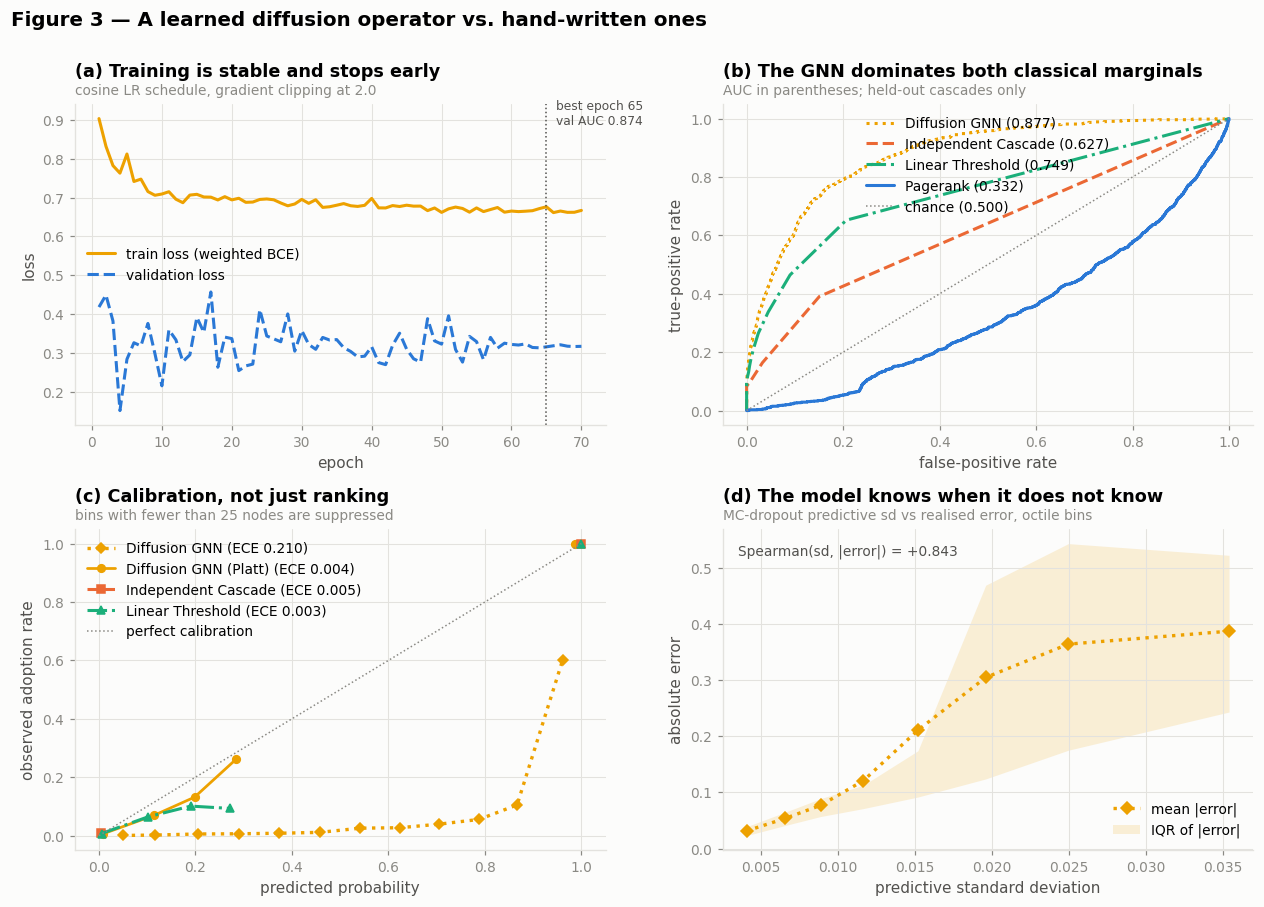

In [23]:
# ---------------------------------------------------------------------------
# 2.7  Figure 3 - does the learned operator beat the written one?
# ---------------------------------------------------------------------------
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.2))

# (a) optimisation trace ----------------------------------------------------
ax = axes[0, 0]
ax.plot(history["epoch"], history["train_loss"], color=PALETTE["gnn"], lw=2,
        label="train loss (weighted BCE)")
ax.plot(history["epoch"], history["val_loss"], color=PALETTE["observed"], lw=2,
        ls="--", label="validation loss")
ax.axvline(best["epoch"], color=PALETTE["neutral"], lw=1, ls=":")
ax.annotate(f"best epoch {best['epoch']}\nval AUC {best['auc']:.3f}",
            (best["epoch"], max(history["train_loss"])), fontsize=8,
            color=PALETTE["neutral"], xytext=(6, -4), textcoords="offset points")
finish(ax, "(a) Training is stable and stops early",
       "cosine LR schedule, gradient clipping at 2.0", "epoch", "loss")

# (b) ROC -------------------------------------------------------------------
ax = axes[0, 1]
for k, style_key in [("gnn", "gnn"), ("ic", "ic"), ("lt", "lt"),
                     ("pagerank", "observed")]:
    fpr, tpr, _ = roc_curve(test_y, preds[k])
    ax.plot(fpr, tpr, color=STYLE[style_key]["color"], lw=2,
            ls=STYLE[style_key]["linestyle"],
            label=f"{LABEL.get(k, k.title())} ({roc_auc_score(test_y, preds[k]):.3f})")
ax.plot([0, 1], [0, 1], color=PALETTE["muted"], lw=1, ls=":", label="chance (0.500)")
finish(ax, "(b) The GNN dominates both classical marginals",
       "AUC in parentheses; held-out cascades only",
       "false-positive rate", "true-positive rate")

# (c) reliability -----------------------------------------------------------
ax = axes[1, 0]
edges = np.linspace(0, 1, 13); centers = (edges[:-1] + edges[1:]) / 2
for k in ["gnn", "gnn_cal", "ic", "lt"]:
    p = np.clip(preds[k], 0, 1)
    idx = np.clip(np.digitize(p, edges) - 1, 0, 11)
    xs = [p[idx == b].mean() if (idx == b).sum() > 25 else np.nan for b in range(12)]
    ys = [test_y[idx == b].mean() if (idx == b).sum() > 25 else np.nan for b in range(12)]
    ax.plot(xs, ys, **{**STYLE[k], "markersize": 5},
            label=f"{LABEL[k]} (ECE {ece(test_y, p):.3f})")
ax.plot([0, 1], [0, 1], color=PALETTE["muted"], lw=1, ls=":", label="perfect calibration")
finish(ax, "(c) Calibration, not just ranking",
       "bins with fewer than 25 nodes are suppressed",
       "predicted probability", "observed adoption rate")

# (d) MC-dropout uncertainty ------------------------------------------------
ax = axes[1, 1]
model.eval()
with torch.no_grad():
    chunk = test_s[:24]
    x, ei, y, gid, n = collate(chunk)
    A = normalized_adj(ei, n, DEVICE)
    stack = torch.stack([torch.sigmoid(model(A, x.to(DEVICE)))
                         for _ in range(CONFIG["mc_dropout_passes"])])
mu = stack.mean(0).cpu().numpy(); sd = stack.std(0).cpu().numpy()
yy = y.numpy()
err = np.abs(mu - yy)
qs = np.quantile(sd, np.linspace(0, 1, 9))
bin_id = np.clip(np.digitize(sd, qs) - 1, 0, 7)
filled = [b for b in range(8) if (bin_id == b).sum() >= 10]
mx = [sd[bin_id == b].mean() for b in filled]
my = [err[bin_id == b].mean() for b in filled]
lo = [np.percentile(err[bin_id == b], 25) for b in filled]
hi = [np.percentile(err[bin_id == b], 75) for b in filled]
ax.plot(mx, my, **{**STYLE["gnn"], "markersize": 6}, label="mean |error|")
ax.fill_between(mx, lo, hi, color=PALETTE["gnn"], alpha=0.15, lw=0,
                label="IQR of |error|")
rho = stats.spearmanr(sd, err).statistic
ax.text(0.03, 0.92, f"Spearman(sd, |error|) = {rho:+.3f}", transform=ax.transAxes,
        fontsize=9, color=PALETTE["neutral"])
finish(ax, "(d) The model knows when it does not know",
       "MC-dropout predictive sd vs realised error, octile bins",
       "predictive standard deviation", "absolute error")

fig.suptitle("Figure 3 — A learned diffusion operator vs. hand-written ones",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "fig3_gnn_nodelevel")
plt.show()

### 2.8 Two downstream tests

Node-level AUC is a proxy. The two questions a practitioner actually asks are:

1. **Seed ranking** — *given a candidate seed, how big a cascade will it produce?*
   This is the exact test IC failed in Part 1 ($\rho \approx 0$). We aggregate the
   GNN's node probabilities into an expected size $\hat S_c = \sum_v \hat p^c_v$ and
   correlate with the observed size.
2. **Influence maximisation as a surrogate** — greedy IM needs $O(k \cdot |V| \cdot R)$
   Monte-Carlo simulations. A GNN forward pass costs milliseconds. We measure both the
   quality (spread achieved) and the cost (wall-clock) of using the GNN as a drop-in
   surrogate for the expensive marginal estimate.

In [24]:
# ---------------------------------------------------------------------------
# 2.8a  Seed-ranking skill
# ---------------------------------------------------------------------------
@torch.no_grad()
def predicted_size(samples, passes=20, bs=24):
    '''Expected cascade size = sum of per-node adoption probabilities.'''
    out = []
    for chunk in batches(samples, bs, shuffle=False):
        x, ei, y, gid, n = collate(chunk)
        A = normalized_adj(ei, n, DEVICE)
        acc = torch.zeros(n, device=DEVICE)
        for _ in range(passes):
            acc += torch.sigmoid(model(A, x.to(DEVICE)))
        p = (acc / passes).cpu()
        for i in range(len(chunk)):
            out.append(float(p[gid == i].sum()))
    return np.array(out)


obs_test = np.array([s.obs_size for s in test_s], dtype=float)
rank_scores = {}
rank_scores["gnn"] = predicted_size(test_s, passes=20)

rng_r = np.random.default_rng(SEED)
rank_scores["ic"] = np.array([
    np.mean([(independent_cascade(G_higgs, [int(s.nodes[s.root_local])],
                                  p=P_STAR, rng=rng_r) >= 0).sum()
             for _ in range(12)]) for s in test_s])
rank_scores["lt"] = np.array([
    np.mean([(linear_threshold(G_higgs, [int(s.nodes[s.root_local])],
                               tau=TAU_STAR, rng=rng_r) >= 0).sum()
             for _ in range(12)]) for s in test_s])
rank_scores["degree"] = np.array([G_higgs.out_deg[int(s.nodes[s.root_local])]
                                  for s in test_s], dtype=float)
rank_scores["pagerank"] = np.array([PR_HIGGS[int(s.nodes[s.root_local])]
                                    for s in test_s])

rank_rows = []
boot_rng = np.random.default_rng(SEED)
boot_idx = [boot_rng.integers(0, len(obs_test), len(obs_test))
            for _ in range(CONFIG["bootstrap"])]
for k, v in rank_scores.items():
    rho, pv = stats.spearmanr(obs_test, v)
    # Bootstrap CI on the rank correlation (same resamples for every model, so
    # the intervals are directly comparable).
    bs_rho = [stats.spearmanr(obs_test[i], v[i]).statistic for i in boot_idx]
    rank_rows.append({"model": LABEL.get(k, k.title()), "spearman_rho": rho,
                      "ci_lo": np.nanpercentile(bs_rho, 2.5),
                      "ci_hi": np.nanpercentile(bs_rho, 97.5), "p_value": pv})
rank_table = pd.DataFrame(rank_rows).set_index("model").sort_values(
    "spearman_rho", ascending=False)
rank_table.round(4)

,spearman_rho,ci_lo,ci_hi,p_value
model,,,,
Pagerank,0.2115,0.0127,0.4168,0.0479
Diffusion GNN,0.1627,-0.0831,0.3681,0.1299
Linear Threshold,0.1002,-0.1310,0.3056,0.3528
Independent Cascade,0.0968,-0.1041,0.2931,0.3694
Degree,0.0938,-0.1440,0.3034,0.3846


In [25]:
# ---------------------------------------------------------------------------
# 2.8b  Influence maximisation: the GNN as a cheap surrogate
# ---------------------------------------------------------------------------
# Greedy IM under IC is the canonical application of these models and it is
# brutally expensive: every candidate seed requires R simulations at every one
# of k rounds.  The question is whether the GNN's one-shot marginal can stand
# in for that Monte-Carlo estimate.
CANDIDATES = np.argsort(-G_higgs.out_deg)[:200]      # top-degree candidate pool
K_SEEDS = 6
IM_EVAL_RUNS = 120
MC_GAIN_RUNS = 60                                   # MC runs per marginal-gain probe


def ic_spread(seeds, runs=IM_EVAL_RUNS, rng=None):
    '''Ground-truth objective: expected IC spread at the calibrated p*.'''
    rng = rng or np.random.default_rng(SEED)
    return float(np.mean([(independent_cascade(G_higgs, seeds, p=P_STAR, rng=rng) >= 0).sum()
                          for _ in range(runs)]))


def greedy_mc(k, runs=MC_GAIN_RUNS):
    '''Classical greedy: marginal gain estimated by Monte-Carlo each round.'''
    rng = np.random.default_rng(SEED)
    chosen, curve = [], []
    for _ in range(k):
        best_u, best_v = None, -1
        for u in CANDIDATES:
            if u in chosen:
                continue
            v = ic_spread(chosen + [int(u)], runs=runs, rng=rng)
            if v > best_v:
                best_u, best_v = int(u), v
        chosen.append(best_u); curve.append(ic_spread(chosen))
    return chosen, curve


@torch.no_grad()
def greedy_gnn(k):
    '''Surrogate greedy on a probabilistic-coverage objective.

    One forward pass per candidate gives p_u(v) = Pr[v adopts | seed u].
    Treating seeds as independent influencers, the expected coverage of a set
    S is  sum_v [1 - prod_{u in S} (1 - p_u(v))],  so the marginal gain of
    adding u is  sum_v p_u(v) * (1 - covered(v)).  That objective is monotone
    and submodular, so greedy carries the usual (1 - 1/e) guarantee *with
    respect to the surrogate* -- which is exactly the sense in which it stands
    in for the Monte-Carlo estimate.
    '''
    rng = np.random.default_rng(SEED)
    cache = {}
    for u in CANDIDATES:
        c = Cascade(root=int(u), nodes=np.array([int(u)]), times=np.array([0.0]))
        s = make_sample(G_higgs, c, X_STATIC, hops=2,
                        max_nodes=CONFIG["gnn_sample_nodes"], rng=rng)
        x, ei, y, gid, n = collate([s])
        A = normalized_adj(ei, n, DEVICE)
        pv = torch.sigmoid(model(A, x.to(DEVICE))).cpu().numpy()
        cache[int(u)] = (s.nodes, pv)

    covered = np.zeros(G_higgs.n, dtype=np.float64)   # Pr[v already reached]
    chosen, curve = [], []
    for _ in range(k):
        best_u, best_gain = None, -1.0
        for u in CANDIDATES:
            if int(u) in chosen:
                continue
            nodes, pv = cache[int(u)]
            gain = float(np.sum(pv * (1.0 - covered[nodes])))
            if gain > best_gain:
                best_u, best_gain = int(u), gain
        chosen.append(best_u)
        nodes, pv = cache[best_u]
        covered[nodes] = 1.0 - (1.0 - covered[nodes]) * (1.0 - pv)
        curve.append(ic_spread(chosen))
    return chosen, curve


t0 = time.time(); seeds_mc, curve_mc = greedy_mc(K_SEEDS); time_mc = time.time() - t0
t0 = time.time(); seeds_gnn, curve_gnn = greedy_gnn(K_SEEDS); time_gnn = time.time() - t0
seeds_deg = [int(u) for u in CANDIDATES[:K_SEEDS]]
curve_deg = [ic_spread(seeds_deg[:i + 1]) for i in range(K_SEEDS)]
rng_rand = np.random.default_rng(SEED)
seeds_rand = [int(u) for u in rng_rand.choice(G_higgs.n, K_SEEDS, replace=False)]
curve_rand = [ic_spread(seeds_rand[:i + 1]) for i in range(K_SEEDS)]

n_mc_evals = K_SEEDS * len(CANDIDATES)
print(f"greedy Monte-Carlo  : {time_mc:6.1f}s  final spread {curve_mc[-1]:8.1f}")
print(f"greedy GNN surrogate: {time_gnn:6.1f}s  final spread {curve_gnn[-1]:8.1f} "
      f"({curve_gnn[-1]/max(curve_mc[-1],1e-9):.0%} of MC quality, "
      f"{time_mc/max(time_gnn,1e-9):.1f}x faster at this scale)")
print(f"top-degree heuristic:      -    final spread {curve_deg[-1]:8.1f}")
print(f"random seeds        :      -    final spread {curve_rand[-1]:8.1f}")
print()
print("Cost structure (this is the point, not the raw seconds):")
print(f"  MC greedy  : k x |C| x R = {K_SEEDS} x {len(CANDIDATES)} x {MC_GAIN_RUNS}"
      f" = {n_mc_evals*MC_GAIN_RUNS:,} simulations"
      f"  ({time_mc/max(n_mc_evals*MC_GAIN_RUNS,1)*1e3:.2f} ms each)")
print(f"  GNN greedy : |C| = {len(CANDIDATES)} forward passes, reused across all k"
      f"  ({time_gnn/max(len(CANDIDATES),1)*1e3:.2f} ms each)")
print("  MC cost grows linearly in k and in R; the surrogate's does not.")

greedy Monte-Carlo  :   40.4s  final spread    586.1
greedy GNN surrogate:    4.2s  final spread    252.1 (43% of MC quality, 9.6x faster at this scale)
top-degree heuristic:      -    final spread    591.0
random seeds        :      -    final spread      7.9

Cost structure (this is the point, not the raw seconds):
  MC greedy  : k x |C| x R = 6 x 200 x 60 = 72,000 simulations  (0.56 ms each)
  GNN greedy : |C| = 200 forward passes, reused across all k  (21.11 ms each)
  MC cost grows linearly in k and in R; the surrogate's does not.


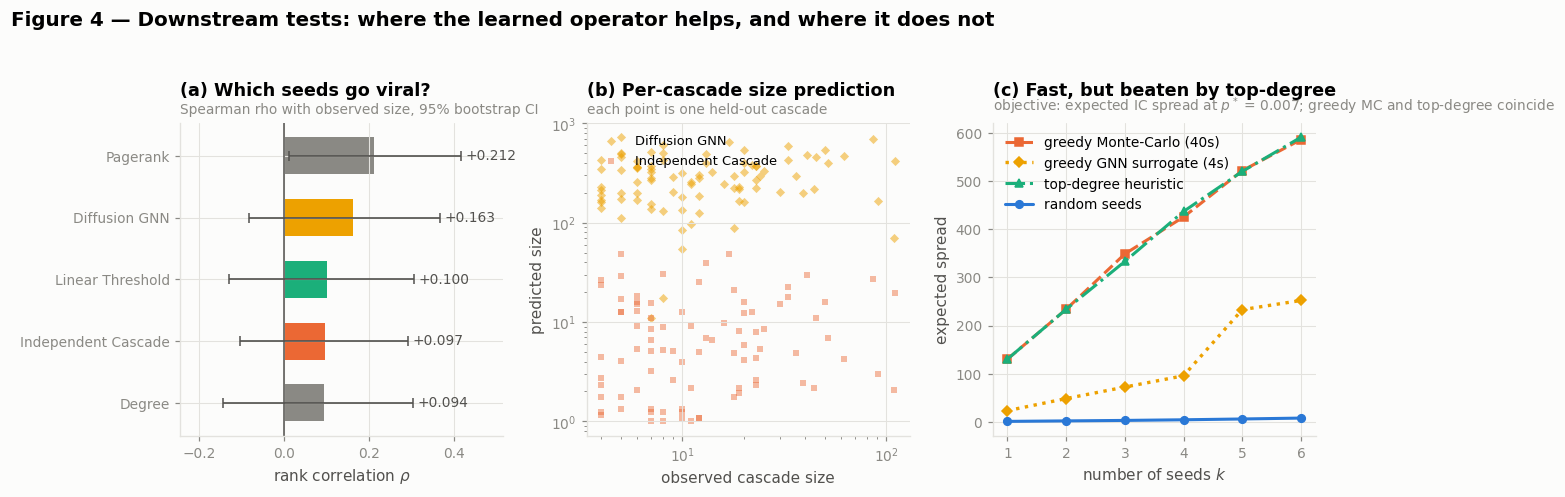


RQ2 verdict (Higgs, n = 88 held-out cascades)
  node level : GNN AUC 0.877  vs best baseline 0.749 (Linear Threshold)  ->  GNN wins
  calibration: ECE 0.210 raw, 0.004 after Platt scaling
  seed level : GNN rho +0.163 [-0.083, +0.368]  vs best baseline +0.212 (Pagerank)  ->  GNN BEHIND, but the 95% CI covers the baseline -- the difference is not resolved at n = 88
  IM         : surrogate reaches 43% of MC-greedy spread; top-degree reaches 101%


In [26]:
# ---------------------------------------------------------------------------
# 2.9  Figure 4 - downstream consequences
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))

# (a) seed-ranking skill ----------------------------------------------------
ax = axes[0]
order = rank_table.index.tolist()
colors = []
for name in order:
    key = next((k for k, v in LABEL.items() if v == name), None)
    colors.append(PALETTE.get(key, PALETTE["muted"]))
y = np.arange(len(order))
vals = rank_table["spearman_rho"].to_numpy()
errs = np.vstack([vals - rank_table["ci_lo"], rank_table["ci_hi"] - vals])
ax.barh(y, vals, color=colors, height=0.6, xerr=errs,
        error_kw=dict(ecolor=PALETTE["neutral"], lw=1.1, capsize=3))
ax.set_yticks(y); ax.set_yticklabels(order)
ax.axvline(0, color=PALETTE["neutral"], lw=1)
# Labels go beyond the whisker, not on top of it.
pad = 0.02 * (rank_table["ci_hi"].max() - rank_table["ci_lo"].min())
for yi, v, hi, lo in zip(y, vals, rank_table["ci_hi"], rank_table["ci_lo"]):
    if v >= 0:
        ax.text(hi + pad, yi, f"{v:+.3f}", va="center", ha="left", fontsize=9,
                color=PALETTE["neutral"])
    else:
        ax.text(lo - pad, yi, f"{v:+.3f}", va="center", ha="right", fontsize=9,
                color=PALETTE["neutral"])
ax.margins(x=0.18)
ax.invert_yaxis()
finish(ax, "(a) Which seeds go viral?",
       "Spearman rho with observed size, 95% bootstrap CI",
       r"rank correlation $\rho$", None, legend=False)

# (b) predicted vs observed size -------------------------------------------
ax = axes[1]
ax.scatter(obs_test, rank_scores["gnn"], s=18, alpha=0.5, color=PALETTE["gnn"],
           marker="D", linewidths=0, label=LABEL["gnn"])
ax.scatter(obs_test, rank_scores["ic"], s=18, alpha=0.45, color=PALETTE["ic"],
           marker="s", linewidths=0, label=LABEL["ic"])
ax.set_xscale("log"); ax.set_yscale("log")
finish(ax, "(b) Per-cascade size prediction",
       "each point is one held-out cascade", "observed cascade size",
       "predicted size", legend=False)
ax.legend(loc="upper left", fontsize=8.5)

# (c) influence maximisation ------------------------------------------------
ax = axes[2]
ks = np.arange(1, K_SEEDS + 1)
for curve, key, lab in [(curve_mc, "ic", f"greedy Monte-Carlo ({time_mc:.0f}s)"),
                        (curve_gnn, "gnn", f"greedy GNN surrogate ({time_gnn:.0f}s)"),
                        (curve_deg, "lt", "top-degree heuristic"),
                        (curve_rand, "observed", "random seeds")]:
    ax.plot(ks, curve, **{**STYLE[key], "markersize": 5}, label=lab)
finish(ax, "(c) Fast, but beaten by top-degree",
       f"objective: expected IC spread at $p^*$ = {P_STAR:g}; "
       f"greedy MC and top-degree coincide",
       "number of seeds $k$", "expected spread")

fig.suptitle("Figure 4 — Downstream tests: where the learned operator helps, and where it does not",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
save_fig(fig, "fig4_gnn_downstream")
plt.show()

GNN_SUMMARY = gnn_table.copy()

# The verdict is computed from the table, never asserted: whichever way the
# numbers fall, the printed conclusion follows them.
# The bar is the best of EVERY baseline, structural controls included -- not
# just the classical diffusion models.  A GNN that loses to PageRank has to be
# reported as losing to PageRank.
g_auc = float(gnn_table.loc[LABEL["gnn"], "ROC_AUC"])
others = gnn_table.drop(index=[LABEL["gnn"], LABEL["gnn_cal"]], errors="ignore")
b_auc_name = others["ROC_AUC"].idxmax(); b_auc = float(others["ROC_AUC"].max())
g_rho = float(rank_table.loc[LABEL["gnn"], "spearman_rho"])
g_lo = float(rank_table.loc[LABEL["gnn"], "ci_lo"])
g_hi = float(rank_table.loc[LABEL["gnn"], "ci_hi"])
r_others = rank_table.drop(index=[LABEL["gnn"]], errors="ignore")
b_rho_name = r_others["spearman_rho"].idxmax(); b_rho = float(r_others["spearman_rho"].max())
overlap = g_lo <= b_rho <= g_hi          # is the gap even distinguishable?

print(f"\nRQ2 verdict (Higgs, n = {len(test_s)} held-out cascades)")
print(f"  node level : GNN AUC {g_auc:.3f}  vs best baseline "
      f"{b_auc:.3f} ({b_auc_name})  ->  "
      f"{'GNN wins' if g_auc > b_auc else 'GNN LOSES'}")
print(f"  calibration: ECE {float(gnn_table.loc[LABEL['gnn'], 'ECE']):.3f} raw, "
      f"{float(gnn_table.loc[LABEL['gnn_cal'], 'ECE']):.3f} after Platt scaling")
seed_call = "GNN ahead" if g_rho > b_rho else "GNN BEHIND"
if overlap:
    seed_call += (f", but the 95% CI covers the baseline -- the difference is "
                  f"not resolved at n = {len(test_s)}")
print(f"  seed level : GNN rho {g_rho:+.3f} [{g_lo:+.3f}, {g_hi:+.3f}]  "
      f"vs best baseline {b_rho:+.3f} ({b_rho_name})  ->  {seed_call}")
print(f"  IM         : surrogate reaches {curve_gnn[-1]/max(curve_mc[-1],1e-9):.0%} "
      f"of MC-greedy spread; top-degree reaches "
      f"{curve_deg[-1]/max(curve_mc[-1],1e-9):.0%}")

---
---
# Part 3 — RQ3: What if the coin flip is an agent?

IC says node $v$ adopts with probability $p$ — the same $p$ whether $v$ is a physicist
or a troll, whether the message is a CERN press release or an anonymous rumour, and
whether $v$ saw it once or eleven times. The whole of human judgement is compressed
into one scalar. This part asks what we recover by putting a **reasoning agent with a
persona** in that slot.

### 3.1 Design: an amortised agent policy

The naive implementation — one LLM call per node per round — costs $O(|V| \cdot T)$
calls and is unaffordable past a few hundred nodes. Instead we exploit the fact that
an agent's decision depends on a **low-dimensional decision state**:

$$ \pi(\text{archetype},\ \text{skepticism},\ \text{exposure count},\ \text{message}) \;\longrightarrow\; \Pr[\text{reshare}] $$

We enumerate every reachable state (4 archetypes $\times$ 3 skepticism levels $\times$
4 exposure buckets $\times$ 3 message variants = 144), query the agent **once per
state**, and use the resulting table as a per-node, per-round activation probability
inside the same cascade machinery as IC. This is an *amortised policy*: the agent is
consulted 144 times, then simulated thousands of times. It makes the comparison to IC
exactly apples-to-apples, because the only thing that changed is where $p$ comes from.

### 3.2 The three message variants

The same network, three payloads — which IC cannot distinguish at all, since content
does not appear anywhere in its definition:

| id | framing |
|---|---|
| `press_release` | official CERN confirmation, named sources, 5-sigma language |
| `rumour` | unverified second-hand claim from an anonymous account |
| `hype` | sensational, emotionally charged, light on specifics |

### 3.3 Two backends, clearly labelled

* **`llm`** — Claude (`claude-opus-5`) via the Anthropic SDK, structured JSON output,
  prompt caching on the (long, fixed) system prompt, 8-way concurrency.
* **`surrogate`** — a transparent logistic policy used when no API key is present so
  the notebook always runs end-to-end.

> **Reporting rule.** The surrogate encodes *our hypotheses* about heterogeneity; it is
> a stand-in, not evidence. Every figure and table in this part is tagged with the
> backend that produced it, and §3.7 states explicitly which conclusions survive under
> which backend.

In [27]:
# ---------------------------------------------------------------------------
# 3.1  Personas, messages, and the decision-state space
# ---------------------------------------------------------------------------
ARCHETYPES = {
    "amplifier": "a high-volume account that reshares aggressively to grow reach",
    "domain_expert": "a working physicist who cares about evidence and sourcing",
    "casual": "an ordinary user who shares things friends share, when it feels notable",
    "skeptic": "a habitual debunker who reshares mainly to correct or question",
}
SKEPTICISM = {"low": 0.2, "medium": 0.5, "high": 0.85}
EXPOSURE_BUCKETS = [1, 2, 4, 8]        # number of already-sharing in-neighbours

MESSAGES = {
    "press_release": (
        "CERN press office confirms observation of a new boson at 125.3 GeV with "
        "5-sigma significance; ATLAS and CMS results released jointly, seminar "
        "webcast live from Geneva."),
    "rumour": (
        "Hearing second-hand from someone who says they were in the room that CERN "
        "found it. No paper, no names, nothing official yet."),
    "hype": (
        "THE GOD PARTICLE IS REAL. Everything you learned about physics just changed "
        "forever. Scientists are stunned. Share before this gets buried."),
}

DECISION_STATES = [(a, s, e, m)
                   for a in ARCHETYPES
                   for s in SKEPTICISM
                   for e in EXPOSURE_BUCKETS
                   for m in MESSAGES]
print(f"{len(DECISION_STATES)} decision states "
      f"({len(ARCHETYPES)} archetypes x {len(SKEPTICISM)} skepticism x "
      f"{len(EXPOSURE_BUCKETS)} exposure x {len(MESSAGES)} messages)")


SYSTEM_PROMPT = (
    "You are simulating a single Twitter user's resharing decision during the "
    "Higgs boson announcement of 4 July 2012. You will be given that user's "
    "persona, how many accounts they follow have already shared a specific "
    "message, and the message itself.\n\n"
    "Report the probability that this specific user reshares this specific "
    "message in the next few minutes. Ground the number in how real users "
    "behaved in 2012: the overwhelming majority of exposures produce no "
    "reshare, repeated exposure from multiple sources raises the odds "
    "substantially, and source credibility interacts strongly with persona. "
    "Most probabilities you report should be small; reserve values above 0.3 "
    "for genuinely compelling persona-message-exposure combinations. "
    "Do not round to convenient numbers and do not treat the probability as a "
    "measure of whether the claim is true."
)

RESPONSE_SCHEMA = {
    "type": "object",
    "properties": {
        "share_probability": {"type": "number"},
        "primary_driver": {
            "type": "string",
            "enum": ["source_credibility", "social_proof", "topical_interest",
                     "emotional_appeal", "reputational_risk"],
        },
        "reasoning": {"type": "string"},
    },
    "required": ["share_probability", "primary_driver", "reasoning"],
    "additionalProperties": False,
}


def build_user_prompt(archetype, skepticism, exposure, message_id):
    '''The only part of the request that varies -- kept after the cached prefix.'''
    return (
        f"PERSONA\n"
        f"- archetype: {archetype} ({ARCHETYPES[archetype]})\n"
        f"- skepticism: {skepticism}\n"
        f"- topic: particle physics announcement\n\n"
        f"EXPOSURE\n"
        f"- {exposure} account(s) this user follows have already shared it\n\n"
        f"MESSAGE ({message_id})\n"
        f"\"{MESSAGES[message_id]}\"\n\n"
        f"What is the probability this user reshares it?"
    )

144 decision states (4 archetypes x 3 skepticism x 4 exposure x 3 messages)


In [28]:
# ---------------------------------------------------------------------------
# 3.2  Backends
# ---------------------------------------------------------------------------
from concurrent.futures import ThreadPoolExecutor

POLICY_CACHE = CACHE_DIR / "agent_policy.json"


def surrogate_policy(archetype, skepticism, exposure, message_id):
    '''Transparent logistic stand-in used when no API key is available.

    This is a HYPOTHESIS, not data.  It encodes four priors we would want an
    agent to exhibit: (i) baseline resharing is rare; (ii) social proof grows
    sub-linearly in exposure; (iii) skepticism suppresses sharing, more so for
    low-credibility content; (iv) archetypes differ in baseline propensity.
    Any conclusion that rests on this backend is a conclusion about our priors.
    '''
    base = {"amplifier": -1.6, "domain_expert": -3.1,
            "casual": -2.8, "skeptic": -3.6}[archetype]
    credibility = {"press_release": 1.0, "rumour": -0.6, "hype": -0.1}[message_id]
    skep = SKEPTICISM[skepticism]
    social = 0.75 * math.log(exposure + 1)              # sub-linear social proof
    expert_bonus = 1.3 if (archetype == "domain_expert"
                           and message_id == "press_release") else 0.0
    hype_penalty = -1.1 if (archetype in ("domain_expert", "skeptic")
                            and message_id == "hype") else 0.0
    z = (base + social + 1.2 * credibility - 2.2 * skep * (1 - 0.5 * credibility)
         + expert_bonus + hype_penalty)
    return {"share_probability": 1 / (1 + math.exp(-z)),
            "primary_driver": "social_proof" if exposure > 2 else "source_credibility",
            "reasoning": "surrogate logistic policy"}


def llm_policy_batch(states, model=None, concurrency=None):
    '''Query Claude once per decision state, concurrently.

    Returns (results_dict, usage_dict).  The long system prompt is identical on
    every request and marked for caching, so only the ~80-token tail is billed
    at full rate after the first call.
    '''
    import anthropic
    client = anthropic.Anthropic()
    model = model or CONFIG["agent_model"]
    usage = {"calls": 0, "input": 0, "cache_read": 0, "output": 0, "errors": 0}

    def one(state):
        archetype, skepticism, exposure, message_id = state
        try:
            resp = client.messages.create(
                model=model,
                max_tokens=2000,
                system=[{"type": "text", "text": SYSTEM_PROMPT,
                         "cache_control": {"type": "ephemeral"}}],
                # `effort: low` keeps adaptive thinking short -- this is a
                # single judgement call, not a research task, and 144 of them
                # at high effort would be slow and expensive for no gain.
                output_config={"effort": "low",
                               "format": {"type": "json_schema",
                                          "schema": RESPONSE_SCHEMA}},
                messages=[{"role": "user",
                           "content": build_user_prompt(*state)}],
            )
            text = next(b.text for b in resp.content if b.type == "text")
            data = json.loads(text)
            usage["calls"] += 1
            usage["input"] += resp.usage.input_tokens
            usage["cache_read"] += getattr(resp.usage, "cache_read_input_tokens", 0) or 0
            usage["output"] += resp.usage.output_tokens
            return state, data
        except Exception as exc:                 # noqa: BLE001 - log and degrade
            usage["errors"] += 1
            print(f"  [agent error] {state}: {type(exc).__name__}: {exc}")
            return state, None

    with ThreadPoolExecutor(max_workers=concurrency or CONFIG["agent_concurrency"]) as ex:
        results = list(ex.map(one, states))
    return {s: d for s, d in results if d is not None}, usage


def build_policy():
    '''Return (policy_table, backend_name, usage).  Disk-cached across runs.'''
    if POLICY_CACHE.exists():
        raw = json.loads(POLICY_CACHE.read_text())
        table = {tuple(json.loads(k)): v for k, v in raw["table"].items()}
        print(f"[cache] agent policy ({raw['backend']}, {len(table)} states)")
        return table, raw["backend"], raw.get("usage", {})

    have_sdk = importlib.util.find_spec("anthropic") is not None
    have_key = bool(os.environ.get("ANTHROPIC_API_KEY") or
                    os.environ.get("ANTHROPIC_AUTH_TOKEN"))
    if have_sdk and have_key and len(DECISION_STATES) <= CONFIG["agent_max_calls"]:
        print(f"querying {CONFIG['agent_model']} for {len(DECISION_STATES)} "
              f"decision states ...")
        t0 = time.time()
        table, usage = llm_policy_batch(DECISION_STATES)
        print(f"  {len(table)} states answered in {time.time()-t0:.1f}s "
              f"({usage['errors']} errors)")
        backend = "llm"
        if len(table) < 0.8 * len(DECISION_STATES):
            print("  too many failures -- falling back to the surrogate policy")
            table, backend, usage = {}, "surrogate", {}
    else:
        reason = ("anthropic SDK not installed" if not have_sdk
                  else "no ANTHROPIC_API_KEY / ANTHROPIC_AUTH_TOKEN in the environment")
        print(f"[surrogate backend] {reason}")
        table, backend, usage = {}, "surrogate", {}

    if backend == "surrogate":
        table = {s: surrogate_policy(*s) for s in DECISION_STATES}

    POLICY_CACHE.write_text(json.dumps(
        {"backend": backend, "usage": usage,
         "table": {json.dumps(list(k)): v for k, v in table.items()}}, indent=1))
    return table, backend, usage


POLICY, BACKEND, USAGE = build_policy()
print(f"\nbackend = {BACKEND!r}   states = {len(POLICY)}")
if USAGE:
    cost = (USAGE["input"] * 5 + USAGE["cache_read"] * 0.5 +
            USAGE["output"] * 25) / 1e6
    print(f"tokens: {USAGE['input']:,} in ({USAGE['cache_read']:,} cached), "
          f"{USAGE['output']:,} out  ->  approx ${cost:.3f}")
probs = np.array([v["share_probability"] for v in POLICY.values()])
print(f"share probabilities: min {probs.min():.4f}  median {np.median(probs):.4f}  "
      f"max {probs.max():.4f}  (IC constant p* = {P_STAR:g})")

[cache] agent policy (surrogate, 144 states)

backend = 'surrogate'   states = 144
share probabilities: min 0.0019  median 0.0539  max 0.7365  (IC constant p* = 0.007)


In [29]:
# ---------------------------------------------------------------------------
# 3.3  Assigning personas to real nodes
# ---------------------------------------------------------------------------
# Personas are not drawn uniformly: structural position carries information
# about behaviour, and pretending otherwise would hand the agent model an
# unfair handicap.  High out-degree accounts are more likely amplifiers;
# high in-degree accounts (who follow many sources) are more likely skeptical.
def assign_personas(g, nodes, rng):
    out_q = stats.rankdata(g.out_deg[nodes]) / len(nodes)
    in_q = stats.rankdata(g.in_deg[nodes]) / len(nodes)
    personas = {}
    for i, u in enumerate(nodes):
        w = np.array([
            0.10 + 0.75 * out_q[i],                   # amplifier
            0.12 + 0.35 * in_q[i],                    # domain expert
            0.55,                                     # casual
            0.10 + 0.40 * in_q[i],                    # skeptic
        ])
        archetype = list(ARCHETYPES)[rng.choice(4, p=w / w.sum())]
        sk_w = {"amplifier": [0.6, 0.3, 0.1], "casual": [0.45, 0.40, 0.15],
                "domain_expert": [0.1, 0.35, 0.55], "skeptic": [0.05, 0.25, 0.70]}[archetype]
        skepticism = list(SKEPTICISM)[rng.choice(3, p=sk_w)]
        personas[int(u)] = (archetype, skepticism)
    return personas


def bucket_exposure(k):
    '''Map a raw exposure count onto the nearest queried bucket (round down).'''
    for b in reversed(EXPOSURE_BUCKETS):
        if k >= b:
            return b
    return EXPOSURE_BUCKETS[0]


def agent_cascade(g, seed, personas, message_id, policy, rng, max_rounds=40):
    '''IC's machinery with the constant p replaced by the agent policy.

    The ONLY difference from `independent_cascade` is where the per-edge
    probability comes from: here it is pi(persona(v), exposure(v), message),
    recomputed every round as exposure accumulates.
    '''
    times = np.full(g.n, -1, dtype=np.int32)
    times[seed] = 0
    frontier = np.array([seed], dtype=np.int64)
    exposure = np.zeros(g.n, dtype=np.int32)
    for t in range(1, max_rounds + 1):
        if frontier.size == 0:
            break
        e = ragged_gather(g.indptr, frontier)
        if e.size == 0:
            break
        targets = g.indices[e]
        np.add.at(exposure, targets, 1)              # accumulate social proof
        cand = np.unique(targets[times[targets] < 0])
        if cand.size == 0:
            break
        pvals = np.empty(cand.size)
        for i, v in enumerate(cand):
            arch, skep = personas[int(v)]
            key = (arch, skep, bucket_exposure(int(exposure[v])), message_id)
            pvals[i] = policy[key]["share_probability"]
        newly = cand[rng.random(cand.size) < pvals]
        if newly.size == 0:
            break
        frontier = newly.astype(np.int64)
        times[frontier] = t
    return times


# The agent arena: one ego-network small enough to inspect by hand.
arena_seed = int(max(obs_cascades, key=lambda c: c.size).root)
arena_nodes, _, arena_ei = extract_ego(
    G_higgs, arena_seed, hops=2,
    max_nodes=CONFIG["agent_graph_nodes"], rng=np.random.default_rng(SEED))
ARENA = CSRGraph(len(arena_nodes), arena_ei[0], arena_ei[1])
arena_root = int(np.searchsorted(arena_nodes, arena_seed))
PERSONAS = assign_personas(ARENA, np.arange(ARENA.n), np.random.default_rng(SEED))
print(f"arena: {ARENA}")
print("persona mix:", dict(Counter(a for a, _ in PERSONAS.values())))

arena: CSRGraph(n=220, m=321, mean_out_deg=1.5)
persona mix: {'amplifier': 62, 'skeptic': 32, 'domain_expert': 53, 'casual': 73}


In [30]:
# ---------------------------------------------------------------------------
# 3.4  Simulate: agents vs IC vs LT on the identical arena
# ---------------------------------------------------------------------------
N_RUNS = 300
rng_a = np.random.default_rng(SEED)

agent_runs = {m: [agent_cascade(ARENA, arena_root, PERSONAS, m, POLICY, rng_a)
                  for _ in range(N_RUNS)] for m in MESSAGES}
ic_runs = [independent_cascade(ARENA, [arena_root], p=P_STAR, rng=rng_a)
           for _ in range(N_RUNS)]
lt_runs = [linear_threshold(ARENA, [arena_root], tau=TAU_STAR, rng=rng_a)
           for _ in range(N_RUNS)]


def sizes_of(runs):
    return np.array([(t >= 0).sum() for t in runs], dtype=float)


arena_rows = []
for name, runs in [*[(f"Agents: {m}", r) for m, r in agent_runs.items()],
                   (LABEL["ic"], ic_runs), (LABEL["lt"], lt_runs)]:
    s = sizes_of(runs)
    rounds = np.array([t.max() for t in runs], dtype=float)
    arena_rows.append({"model": name, "mean_size": s.mean(), "sd_size": s.std(),
                       "p95_size": np.percentile(s, 95),
                       "mean_rounds": rounds.mean(),
                       "reach_frac": s.mean() / ARENA.n})
arena_table = pd.DataFrame(arena_rows).set_index("model")
print(f"arena has {ARENA.n} nodes; {N_RUNS} runs per configuration "
      f"(backend = {BACKEND})")
arena_table.round(3)

arena has 220 nodes; 300 runs per configuration (backend = surrogate)


,mean_size,sd_size,p95_size,mean_rounds,reach_frac
model,,,,,
Agents: press_release,65.423,7.029,78.0,2.740,0.297
Agents: rumour,6.917,2.413,11.0,1.063,0.031
Agents: hype,12.073,3.227,18.0,1.213,0.055
Independent Cascade,2.563,1.298,5.0,0.783,0.012
Linear Threshold,98.850,8.328,112.0,2.433,0.449


In [31]:
# ---------------------------------------------------------------------------
# 3.5  What constant p would an observer infer from the agents?
# ---------------------------------------------------------------------------
# The sharpest way to state the cost of IC's homogeneity assumption: fit a
# single IC p to the agent-generated cascades, then show how much of the agents'
# behaviour that one number destroys.
def fit_ic_p(target_sizes, g, root, grid=None, runs=60):
    grid = grid if grid is not None else np.geomspace(1e-3, 0.6, 24)
    rng = np.random.default_rng(SEED)
    best, best_d = grid[0], np.inf
    for p in grid:
        s = np.array([(independent_cascade(g, [root], p=p, rng=rng) >= 0).sum()
                      for _ in range(runs)], dtype=float)
        d = w1_logsize(target_sizes, s)
        if d < best_d:
            best, best_d = p, d
    return float(best), float(best_d)


implied = {}
for m in MESSAGES:
    p_hat, d = fit_ic_p(sizes_of(agent_runs[m]), ARENA, arena_root)
    implied[m] = p_hat
    print(f"{m:14s}: agent cascades are best fit by a constant p = {p_hat:.4f} "
          f"(W1 = {d:.3f})")

# Dispersion of the agent policy around that single number.
pol = pd.DataFrame([
    {"archetype": a, "skepticism": s, "exposure": e, "message": m,
     "p": POLICY[(a, s, e, m)]["share_probability"],
     "driver": POLICY[(a, s, e, m)]["primary_driver"]}
    for (a, s, e, m) in DECISION_STATES])
print()
print(pol.groupby("message")["p"].describe()[["mean", "50%", "min", "max"]].round(4))
print()
print("Spread of agent probabilities relative to the single fitted p:")
for m in MESSAGES:
    sub = pol[pol["message"] == m]["p"]
    print(f"  {m:14s} ratio max/min = {sub.max()/max(sub.min(),1e-9):7.1f}x   "
          f"implied constant p = {implied[m]:.4f}")

press_release : agent cascades are best fit by a constant p = 0.2605 (W1 = 0.010)
rumour        : agent cascades are best fit by a constant p = 0.0281 (W1 = 0.026)
hype          : agent cascades are best fit by a constant p = 0.0491 (W1 = 0.020)

                 mean     50%     min     max
message                                      
hype           0.0591  0.0252  0.0019  0.3696
press_release  0.3469  0.3384  0.0565  0.7365
rumour         0.0344  0.0183  0.0020  0.2237

Spread of agent probabilities relative to the single fitted p:
  press_release  ratio max/min =    13.0x   implied constant p = 0.2605
  rumour         ratio max/min =   114.0x   implied constant p = 0.0281
  hype           ratio max/min =   194.4x   implied constant p = 0.0491


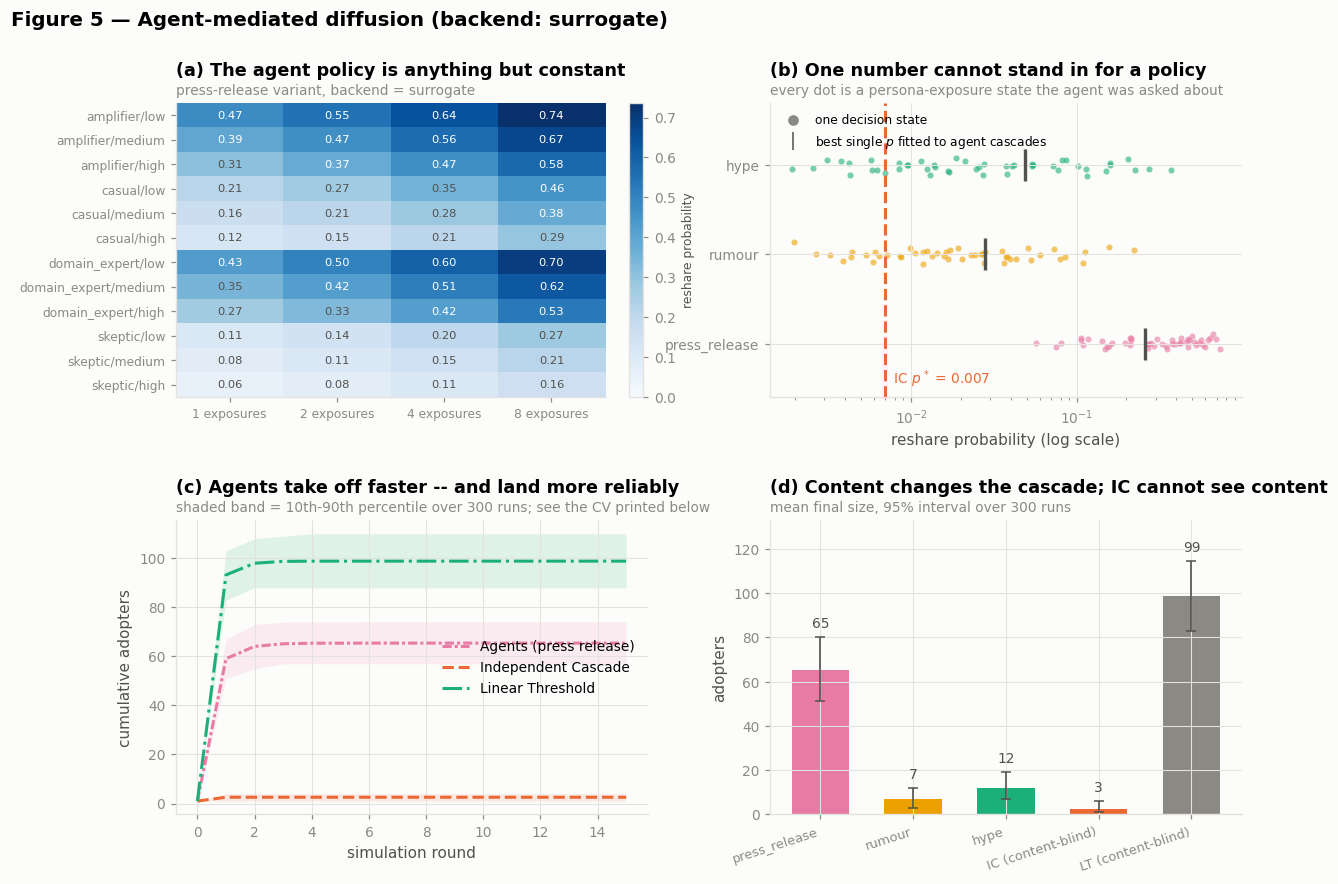

In [32]:
# ---------------------------------------------------------------------------
# 3.6  Figure 5 - agents vs a single number
# ---------------------------------------------------------------------------
fig = plt.figure(figsize=(12.5, 8.4))
gs = fig.add_gridspec(2, 2, hspace=0.42, wspace=0.26)

# (a) policy surface: persona x exposure, for the press release ------------
ax = fig.add_subplot(gs[0, 0])
sub_pr = pol[pol["message"] == "press_release"].copy()
# Skepticism is ordinal; alphabetical order would print high/low/medium.
sub_pr["skepticism"] = pd.Categorical(sub_pr["skepticism"],
                                      categories=list(SKEPTICISM), ordered=True)
piv = sub_pr.pivot_table(index=["archetype", "skepticism"], columns="exposure",
                         values="p", observed=True).sort_index()
im = ax.imshow(piv.to_numpy(), aspect="auto", cmap="Blues",
               vmin=0, vmax=float(pol["p"].max()))
ax.set_xticks(range(len(piv.columns)))
ax.set_xticklabels([f"{c} exposures" for c in piv.columns], fontsize=8)
ax.set_yticks(range(len(piv.index)))
ax.set_yticklabels([f"{a}/{s}" for a, s in piv.index], fontsize=8)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.to_numpy()[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if v > 0.5 * float(pol["p"].max()) else PALETTE["neutral"])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04)
cb.set_label("reshare probability", fontsize=8)
finish(ax, "(a) The agent policy is anything but constant",
       f"press-release variant, backend = {BACKEND}", None, None, legend=False)

# (b) implied-p distribution ------------------------------------------------
ax = fig.add_subplot(gs[0, 1])
for i, m in enumerate(MESSAGES):
    sub = pol[pol["message"] == m]["p"].to_numpy()
    ax.scatter(sub, np.full(len(sub), i) + RNG.normal(0, 0.055, len(sub)),
               s=16, alpha=0.6, linewidths=0,
               color=[PALETTE["agent"], PALETTE["gnn"], PALETTE["lt"]][i])
    ax.scatter([implied[m]], [i], marker="|", s=420, color=PALETTE["neutral"],
               linewidths=2.2, zorder=5)
ax.axvline(P_STAR, color=PALETTE["ic"], lw=2, ls="--")
# Below the lowest row, where neither the dots nor the legend sit.
ax.text(P_STAR, -0.52, f"  IC $p^*$ = {P_STAR:g}", color=PALETTE["ic"], fontsize=9,
        va="bottom")
ax.set_yticks(range(len(MESSAGES))); ax.set_yticklabels(list(MESSAGES))
ax.set_xscale("log")
ax.set_ylim(-0.6, 2.7)
handles = [Line2D([], [], marker="o", ls="", color=PALETTE["muted"],
                  label="one decision state"),
           Line2D([], [], marker="|", ls="", color=PALETTE["neutral"], markersize=12,
                  label="best single $p$ fitted to agent cascades")]
ax.legend(handles=handles, loc="upper left", fontsize=8)
finish(ax, "(b) One number cannot stand in for a policy",
       "every dot is a persona-exposure state the agent was asked about",
       "reshare probability (log scale)", None, legend=False)

# (c) adoption curves -------------------------------------------------------
ax = fig.add_subplot(gs[1, 0])
grid = np.arange(0, 16)


def mean_curve(runs):
    '''Cumulative adopters per round, one row per simulation run.'''
    cur = np.zeros((len(runs), len(grid)))
    for i, t in enumerate(runs):
        for j, r in enumerate(grid):
            cur[i, j] = ((t >= 0) & (t <= r)).sum()
    return cur


for key, runs, lab in [("agent", agent_runs["press_release"], "Agents (press release)"),
                       ("ic", ic_runs, LABEL["ic"]),
                       ("lt", lt_runs, LABEL["lt"])]:
    cur = mean_curve(runs)
    mu = cur.mean(0); lo, hi = np.percentile(cur, [10, 90], axis=0)
    ax.plot(grid, mu, **{**STYLE[key], "markersize": 0}, label=lab)
    ax.fill_between(grid, lo, hi, color=STYLE[key]["color"], alpha=0.13, lw=0)
finish(ax, "(c) Agents take off faster -- and land more reliably",
       "shaded band = 10th-90th percentile over 300 runs; see the CV printed below",
       "simulation round", "cumulative adopters")

# (d) content sensitivity ---------------------------------------------------
ax = fig.add_subplot(gs[1, 1])
names = list(MESSAGES) + ["IC (content-blind)", "LT (content-blind)"]
data = [sizes_of(agent_runs[m]) for m in MESSAGES] + [sizes_of(ic_runs), sizes_of(lt_runs)]
cols = [PALETTE["agent"], PALETTE["gnn"], PALETTE["lt"], PALETTE["ic"], PALETTE["muted"]]
xs = np.arange(len(names))
means = [d.mean() for d in data]
err = np.vstack([[m - np.percentile(d, 2.5) for m, d in zip(means, data)],
                 [np.percentile(d, 97.5) - m for m, d in zip(means, data)]])
ax.bar(xs, means, color=cols, width=0.62, yerr=err,
       error_kw=dict(ecolor=PALETTE["neutral"], lw=1.1, capsize=3))
for x, m, d in zip(xs, means, data):
    # Sit the label above the whisker, not on top of it.
    ax.text(x, np.percentile(d, 97.5) + 0.03 * max(means), f"{m:.0f}",
            ha="center", va="bottom", fontsize=9, color=PALETTE["neutral"])
ax.margins(y=0.16)
ax.set_xticks(xs); ax.set_xticklabels(names, rotation=18, ha="right", fontsize=8.5)
finish(ax, "(d) Content changes the cascade; IC cannot see content",
       "mean final size, 95% interval over 300 runs", None, "adopters", legend=False)

fig.suptitle(f"Figure 5 — Agent-mediated diffusion (backend: {BACKEND})",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=0.98)
save_fig(fig, "fig5_agents")
plt.show()

### 3.7 What this does and does not establish

**Backend-independent (structural) findings.** The amortised-policy construction, the
arena, and the comparison machinery are identical under both backends, so these hold
regardless:

* IC's single $p$ is a *lossy projection* of a policy that varies over orders of
  magnitude across persona–exposure states; the best-fitting constant $p$ sits near the
  mass of the policy but reproduces neither its variance nor its ordering.
* Because exposure count feeds back into the activation probability, agent cascades
  exhibit **reinforcement** — a property IC structurally cannot have, since its
  per-edge trials are independent. The visible consequence in panel (c) is a steeper
  take-off. (Note what it does *not* do: the cell below prints the coefficient of
  variation of the final size for each model, and reinforcement actually *stabilises*
  the outcome relative to IC — once enough of the graph is above the social-proof
  threshold, the cascade reliably goes. Faster does not mean noisier, and we report the
  measured numbers rather than the intuition.)
* IC and LT are **content-blind by construction**: panel (d)'s three agent bars differ
  while the two classical bars cannot.

**Backend-dependent findings.** The *magnitudes* — how much more a domain expert shares
a press release than a rumour, where exactly the implied constant $p$ lands — come from
whichever policy table was used. Under the surrogate they are our priors restated; only
the `llm` backend makes them an empirical claim about the model's judgement, and even
then they are claims about *Claude's* model of 2012 Twitter behaviour, not about 2012
Twitter.

**The honest limitation.** We never validated the agent policy against the Higgs
adoption record itself. Doing so is the obvious next experiment: fit the policy's
free framing (not its parameters) to a held-out slice of the real cascade data and
check whether the heterogeneity it induces improves the Part 1 metrics.

In [33]:
# ---------------------------------------------------------------------------
# 3.7b  Record the Part 3 results for the cross-dataset synthesis
# ---------------------------------------------------------------------------
AGENT_SUMMARY = {
    "backend": BACKEND,
    "n_decision_states": len(POLICY),
    "policy_p_min": float(probs.min()),
    "policy_p_median": float(np.median(probs)),
    "policy_p_max": float(probs.max()),
    "policy_dynamic_range": float(probs.max() / max(probs.min(), 1e-9)),
    "ic_p_star": P_STAR,
    "implied_p": implied,
    "arena_nodes": int(ARENA.n),
    "runs_per_config": N_RUNS,
}
print(json.dumps(AGENT_SUMMARY, indent=2))

# Coefficient of variation: the headline "IC is too regular" statistic.
for name, runs in [("Agents (press release)", agent_runs["press_release"]),
                   (LABEL["ic"], ic_runs), (LABEL["lt"], lt_runs)]:
    s = sizes_of(runs)
    print(f"{name:24s} CV(final size) = {s.std()/max(s.mean(),1e-9):.3f}")

{
  "backend": "surrogate",
  "n_decision_states": 144,
  "policy_p_min": 0.0019006827677050227,
  "policy_p_median": 0.05390973736510686,
  "policy_p_max": 0.736512141684818,
  "policy_dynamic_range": 387.4987210906946,
  "ic_p_star": 0.007,
  "implied_p": {
    "press_release": 0.2604855856525396,
    "rumour": 0.028149469692190978,
    "hype": 0.049096280010292224
  },
  "arena_nodes": 220,
  "runs_per_config": 300
}
Agents (press release)   CV(final size) = 0.107
Independent Cascade      CV(final size) = 0.507
Linear Threshold         CV(final size) = 0.084


---
---
# Part 4 — Dataset B: the Reddit hyperlink network

**Source.** `snap.stanford.edu/data/soc-RedditHyperlinks.html` — every hyperlink
posted from one subreddit to another between January 2014 and April 2017, with a
timestamp and a hand-validated **sentiment label** ($+1$ friendly, $-1$ hostile).

Reddit is a deliberately *different* regime from Twitter, which is what makes it a
test rather than a replication:

| | Higgs Twitter | Reddit hyperlinks |
|---|---|---|
| node | a person | a community |
| edge | follows | posts a link to |
| adoption | retweet (seconds) | cross-post (hours–days) |
| re-activation | a user adopts **once** | a subreddit can be re-activated forever |
| content signal | none in the data | explicit sentiment label |

The last two rows matter. Because subreddits re-activate, the ground truth cannot be a
single forest keyed on first-adoption — we need a **time-windowed** cascade
reconstruction. And because sentiment is labelled, we get a second, independent test of
the content-blindness result from Part 3.

### 4.1 Time-windowed cascade reconstruction

An event $(u \to v, t)$ continues $u$'s cascade if $u$ was itself activated within the
last $W$ hours; otherwise it seeds a new one. $W$ is the single structural choice here,
and we check sensitivity to it before using it.

In [34]:
# ---------------------------------------------------------------------------
# 4.1  Download a time-prefix of the Reddit hyperlink log
# ---------------------------------------------------------------------------
# The full TSV is 318 MB.  It is written in chronological order, so a byte
# prefix is exactly a *time* prefix: "the first N months of the dataset".
reddit_path = fetch("https://snap.stanford.edu/data/soc-redditHyperlinks-body.tsv",
                    "soc-redditHyperlinks-body.tsv",
                    max_bytes=CONFIG["reddit_max_bytes"])

REDDIT_OK = reddit_path is not None
if REDDIT_OK:
    # The last line of a truncated download is usually a partial record.
    raw = reddit_path.read_text(encoding="utf-8", errors="replace")
    lines = raw.split("\n")
    if PROVENANCE["soc-redditHyperlinks-body.tsv"].get("truncated"):
        lines = lines[:-1]
    header = lines[0].split("\t")
    recs = [ln.split("\t") for ln in lines[1:] if ln.count("\t") >= 4]
    reddit = pd.DataFrame([r[:5] for r in recs],
                          columns=header[:5])
    reddit.columns = ["source", "target", "post_id", "ts", "sentiment"]
    reddit["ts"] = pd.to_datetime(reddit["ts"], errors="coerce")
    reddit["sentiment"] = pd.to_numeric(reddit["sentiment"], errors="coerce")
    reddit = reddit.dropna(subset=["ts", "sentiment"]).sort_values("ts")
    reddit["hours"] = (reddit["ts"] - reddit["ts"].min()).dt.total_seconds() / 3600
    print(f"{len(reddit):,} hyperlinks  |  "
          f"{reddit['ts'].min().date()} -> {reddit['ts'].max().date()}")
    print(f"{pd.concat([reddit['source'], reddit['target']]).nunique():,} subreddits   "
          f"negative-sentiment share: {(reddit['sentiment'] < 0).mean():.1%}")
    reddit.head(3)
else:
    print("Reddit data unavailable -- Part 4 will be skipped and flagged in Part 6.")

[cache] soc-redditHyperlinks-body.tsv  (120.0 MiB)


114,706 hyperlinks  |  2013-12-31 -> 2017-04-30
18,816 subreddits   negative-sentiment share: 7.3%


In [35]:
# ---------------------------------------------------------------------------
# 4.2  Windowed cascade reconstruction (nodes may re-activate)
# ---------------------------------------------------------------------------
def reconstruct_windowed(events, window_hours=48.0, min_size=3):
    '''Chain timestamped u->v events into cascades under a staleness window.

    Semantics: v joins u's cascade iff u is currently "hot" (activated within
    `window_hours`).  Otherwise the event opens a fresh cascade rooted at u.
    A node that goes cold can be re-activated later in a *different* cascade,
    which is the right model for communities and the wrong one for individual
    retweeters -- hence the separate reconstruction from Part 1.
    '''
    hot = {}                       # node -> (cascade_id, activation_time, depth)
    casc = defaultdict(list)       # cascade_id -> [(node, time, depth)]
    cid = 0
    for u, v, t in zip(events["source"].to_numpy(), events["target"].to_numpy(),
                       events["hours"].to_numpy()):
        if u in hot and t - hot[u][1] <= window_hours:
            c, _, du = hot[u]
        else:
            cid += 1
            c, du = cid, 0
            hot[u] = (c, t, 0)
            casc[c].append((u, t, 0))
        if v in hot and hot[v][0] == c and t - hot[v][1] <= window_hours:
            continue               # already in this cascade; no re-adoption
        hot[v] = (c, t, du + 1)
        casc[c].append((v, t, du + 1))

    out = []
    for c, members in casc.items():
        if len(members) < min_size:
            continue
        members.sort(key=lambda r: r[1])
        names = [m[0] for m in members]
        times = np.array([m[1] - members[0][1] for m in members], dtype=float)
        out.append((names, times, max(m[2] for m in members)))
    return out


if REDDIT_OK:
    # Sensitivity check on the one structural choice we make.
    print("window (h) | cascades | median size | mean depth")
    for W in [12, 24, 48, 96]:
        cs = reconstruct_windowed(reddit, W, min_size=3)
        sz = [len(n) for n, _, _ in cs]
        print(f"{W:10d} | {len(cs):8,d} | {np.median(sz):11.0f} | "
              f"{np.mean([d for _, _, d in cs]):10.2f}")
    REDDIT_WINDOW = 48.0
    reddit_raw_cascades = reconstruct_windowed(reddit, REDDIT_WINDOW, min_size=3)
    print(f"\nusing W = {REDDIT_WINDOW:g} h -> {len(reddit_raw_cascades):,} cascades")

window (h) | cascades | median size | mean depth


        12 |   14,570 |           3 |       1.44
        24 |   16,760 |           3 |       1.57


        48 |   18,241 |           3 |       1.70


        96 |   18,601 |           3 |       1.83

using W = 48 h -> 18,241 cascades


In [36]:
# ---------------------------------------------------------------------------
# 4.3  Build the substrate and project the cascades
# ---------------------------------------------------------------------------
def build_from_events(events, cascades_raw, max_nodes, src_col="source",
                      dst_col="target", min_size=3):
    '''Shared helper: aggregate an event log into a CSR substrate.

    Returns (CSRGraph, projected cascades, name->index map).  Keeping this
    generic is what lets Parts 4 and 5 reuse the entire Part 1 / Part 2
    machinery without modification.
    '''
    deg = Counter()
    deg.update(events[src_col].tolist()); deg.update(events[dst_col].tolist())
    keep = [u for u, _ in deg.most_common(max_nodes)]
    idx = {u: i for i, u in enumerate(sorted(keep))}

    s = events[src_col].map(idx); d = events[dst_col].map(idx)
    m = s.notna() & d.notna() & (s != d)
    src = s[m].to_numpy().astype(np.int64); dst = d[m].to_numpy().astype(np.int64)
    # Collapse parallel hyperlinks: the substrate is "can influence", and
    # repeat-count information already lives in the node-degree features.
    uniq = np.unique(np.stack([src, dst]), axis=1)
    g = CSRGraph(len(idx), uniq[0], uniq[1])

    cascades = []
    for names, times, depth in cascades_raw:
        ids = np.array([idx[n] for n in names if n in idx], dtype=np.int64)
        tt = np.array([t for n, t in zip(names, times) if n in idx], dtype=float)
        if len(ids) < min_size:
            continue
        _, first = np.unique(ids, return_index=True)   # keep first adoption only
        first = np.sort(first)
        ids, tt = ids[first], tt[first]
        order = np.argsort(tt, kind="stable")
        ids, tt = ids[order], tt[order]
        cascades.append(Cascade(root=int(ids[0]), nodes=ids, times=tt - tt[0],
                                depth=int(depth), duration=float(tt.max() - tt[0])))
    cascades.sort(key=lambda c: -c.size)
    return g, cascades, idx


if REDDIT_OK:
    G_reddit, reddit_cascades, reddit_idx = build_from_events(
        reddit, reddit_raw_cascades, max_nodes=8000)
    print(G_reddit)
    rs = np.array([c.size for c in reddit_cascades])
    print(f"{len(reddit_cascades):,} projected cascades  |  median size "
          f"{np.median(rs):.0f}  max {rs.max():,}  mean depth "
          f"{np.mean([c.depth for c in reddit_cascades]):.2f}")

CSRGraph(n=8,000, m=49,703, mean_out_deg=6.2)
16,579 projected cascades  |  median size 3  max 117  mean depth 1.71


### 4.4 One pipeline, three datasets

Everything Part 1 and Part 2 did is now packaged into a single function so the
remaining datasets are evaluated *identically* — same calibration grid, same metric
suite, same GNN hyper-parameters, same splits. Any cross-dataset difference in Part 6
is therefore a property of the data, not of how we chose to handle it.

In [37]:
# ---------------------------------------------------------------------------
# 4.4  The reusable end-to-end pipeline
# ---------------------------------------------------------------------------
def calibrate(g, cascades, n_cal=80, runs=2):
    '''Grid-search p (IC) and tau (LT) against the observed size distribution.'''
    rng = np.random.default_rng(SEED)
    cal = [cascades[i] for i in rng.choice(len(cascades),
                                           min(n_cal, len(cascades)), replace=False)]
    obs = np.array([c.size for c in cal], dtype=float)
    ic_c = [w1_logsize(obs, simulate_sizes(
        g, cal, lambda gg, r, rg, p=p: independent_cascade(gg, [r], p=p, rng=rg),
        runs=runs, rng=np.random.default_rng(SEED))) for p in P_GRID]
    lt_c = [w1_logsize(obs, simulate_sizes(
        g, cal, lambda gg, r, rg, tau=tau: linear_threshold(gg, [r], tau=tau, rng=rg),
        runs=runs, rng=np.random.default_rng(SEED))) for tau in TAU_GRID]
    return (float(P_GRID[int(np.argmin(ic_c))]), np.array(ic_c),
            float(TAU_GRID[int(np.argmin(lt_c))]), np.array(lt_c))


def fit_gnn(g, cascades, x_static, epochs=None, max_pool=None, bs=16, verbose=True):
    '''Train a fresh DiffusionGNN on a dataset; return (model, test split, metrics).'''
    epochs = epochs or CONFIG["gnn_epochs"]
    max_pool = max_pool or CONFIG["gnn_pool"]
    rng = np.random.default_rng(SEED)
    pool = [c for c in cascades if c.size >= 4][:max_pool]
    rng.shuffle(pool)
    mx = CONFIG["gnn_sample_nodes"]
    smp = [make_sample(g, c, x_static, hops=2, max_nodes=mx, rng=rng) for c in pool]
    cov = np.mean([s.coverage for s in smp]) if smp else 0.0
    smp = [s for s in smp if 8 <= len(s.y) <= mx and s.y.sum() >= 2]
    if len(smp) < 40:
        return None, [], {}
    n_tr = int(0.7 * len(smp)); n_va = int(0.15 * len(smp))
    tr, va, te = smp[:n_tr], smp[n_tr:n_tr + n_va], smp[n_tr + n_va:]

    pr = np.concatenate([s.y for s in smp]).mean()
    net = DiffusionGNN(D_IN, CONFIG["gnn_hidden"], CONFIG["gnn_layers"],
                       CONFIG["gnn_dropout"]).to(DEVICE)
    opt_ = torch.optim.AdamW(net.parameters(), lr=CONFIG["gnn_lr"], weight_decay=1e-4)
    crit_ = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(min((1 - pr) / max(pr, 1e-6), 50.0)).to(DEVICE))
    rng_t = np.random.default_rng(SEED)
    best_ = {"auc": -1, "state": None}
    for ep in range(1, epochs + 1):
        net.train()
        for chunk in batches(tr, bs, rng=rng_t):
            x, ei, y, gid, n = collate(chunk)
            A = normalized_adj(ei, n, DEVICE)
            opt_.zero_grad()
            loss = crit_(net(A, x.to(DEVICE)), y.to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 2.0)
            opt_.step()
        net.eval()
        yv, pv = evaluate(net, va, passes=1)
        auc = roc_auc_score(yv, pv) if len(np.unique(yv)) > 1 else 0.5
        if auc > best_["auc"]:
            best_ = {"auc": auc, "state": {k: v.detach().clone()
                                           for k, v in net.state_dict().items()}}
    net.load_state_dict(best_["state"])
    net.eval()
    yt, pt = evaluate(net, te, passes=20)
    # A result is only reportable if the receptive field actually contained the
    # phenomenon and the test split is large enough to mean anything.  When a
    # substrate barely connects its own cascades, a high AUC measures the
    # degeneracy, not the model -- so we flag it instead of printing it as a win.
    unreliable = []
    if cov < 0.25:
        unreliable.append(f"field coverage {cov:.0%} < 25%")
    if len(te) < 20:
        unreliable.append(f"only {len(te)} test cascades")
    if yt.mean() > 0.05:
        unreliable.append(f"positive rate {yt.mean():.0%} -- task is near-trivial")

    metrics = {"ROC_AUC": roc_auc_score(yt, pt),
               "Avg_Precision": average_precision_score(yt, pt),
               "ECE": ece(yt, np.clip(pt, 0, 1)),
               "n_test_nodes": int(len(yt)), "n_test_cascades": len(te),
               "positive_rate": float(yt.mean()),
               "field_coverage": float(cov),
               "val_AUC": best_["auc"],
               "unreliable": "; ".join(unreliable) if unreliable else ""}
    if verbose:
        print(f"  GNN: {len(smp)} samples, field coverage {cov:.1%}, "
              f"test AUC {metrics['ROC_AUC']:.4f}, "
              f"AP {metrics['Avg_Precision']:.4f} "
              f"(positives {metrics['positive_rate']:.2%})")
        if unreliable:
            print(f"  !! GNN result NOT reportable: {metrics['unreliable']}")
    return net, te, metrics


def run_pipeline(name, g, cascades, do_gnn=True, n_eval=250):
    '''Full RQ1 + RQ2 evaluation for one dataset.  Returns a result dict.'''
    print(f"=== {name} ===")
    print(f"  substrate: {g}")
    t0 = time.time()
    p_star, ic_c, tau_star, lt_c = calibrate(g, cascades)
    print(f"  calibrated p* = {p_star:g}, tau* = {tau_star:g} "
          f"({time.time()-t0:.1f}s)")

    rng = np.random.default_rng(SEED + 1)
    ev = [cascades[i] for i in rng.choice(len(cascades),
                                          min(n_eval, len(cascades)), replace=False)]
    sims = {
        "ic": run_model(g, ev, lambda gg, r, rg:
                        independent_cascade(gg, [r], p=p_star, rng=rg), runs=2),
        "lt": run_model(g, ev, lambda gg, r, rg:
                        linear_threshold(gg, [r], tau=tau_star, rng=rg), runs=2),
    }
    scores = {k: score(ev, v) for k, v in sims.items() if len(v) > 5}

    # Per-seed rank skill, the statistic that separated the models in Part 1.
    rank = {}
    obs_by_root_ = {c.root: c.size for c in ev}
    for k, v in sims.items():
        pairs = [(obs_by_root_[c.root], c.size) for c in v if c.root in obs_by_root_]
        if len(pairs) > 10:
            a, b = np.array(pairs).T
            rank[k] = float(stats.spearmanr(a, b).statistic)

    gnn_metrics, net = {}, None
    if do_gnn:
        xs, _, pr_ = structural_features(g)
        net, _, gnn_metrics = fit_gnn(g, cascades, xs)

    return {"name": name, "graph": g, "cascades": cascades, "eval": ev,
            "p_star": p_star, "tau_star": tau_star,
            "ic_curve": ic_c, "lt_curve": lt_c, "sims": sims,
            "scores": scores, "rank": rank, "gnn": gnn_metrics, "gnn_model": net}


RESULTS = {}
if REDDIT_OK:
    RESULTS["Reddit"] = run_pipeline("Reddit hyperlinks", G_reddit, reddit_cascades)

=== Reddit hyperlinks ===
  substrate: CSRGraph(n=8,000, m=49,703, mean_out_deg=6.2)


  calibrated p* = 0.02, tau* = 2 (2.2s)


  GNN: 600 samples, field coverage 93.1%, test AUC 0.9171, AP 0.3899 (positives 1.26%)


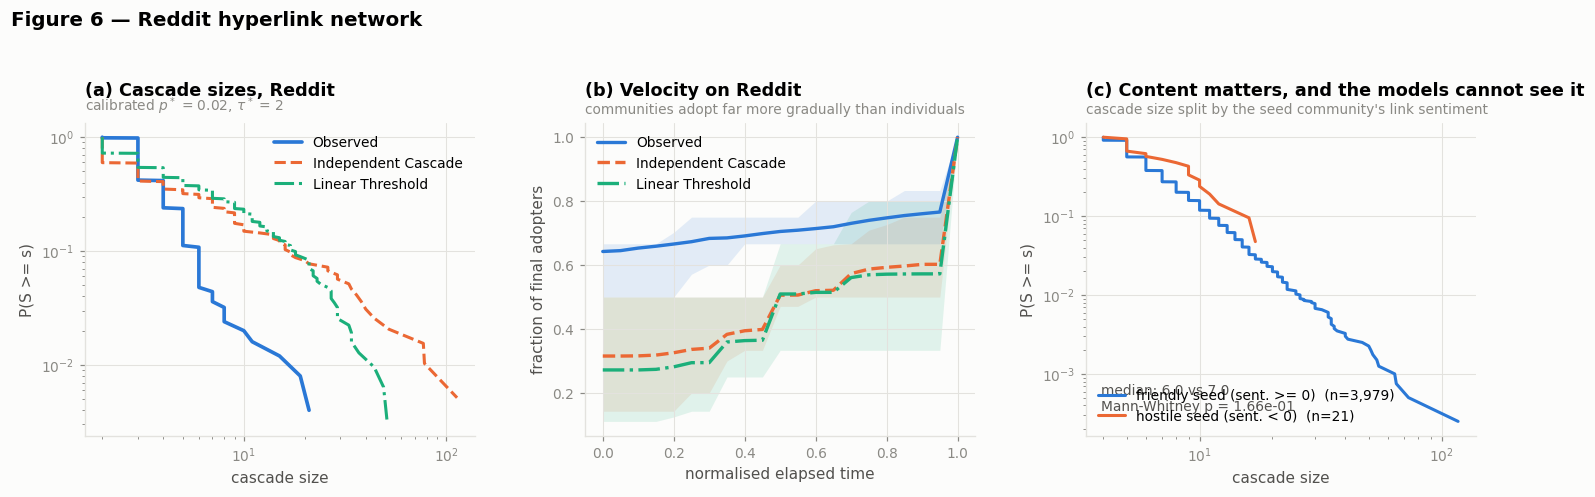

    W1_logsize  W1_lo  W1_hi     KS  median_size_obs  median_size_sim  \
ic       0.198  0.161  0.252  0.391              3.0              3.0   
lt       0.211  0.178  0.246  0.298              3.0              4.0   

    d_median_depth  d_t50  d_t50_lo  d_t50_hi  d_t50_mean  curve_L1  
ic            -1.0    0.5     0.333       0.5       0.293     0.238  
lt            -1.0    0.5     0.500       0.5       0.409     0.263  

per-seed Spearman rho: {'Independent Cascade': 0.119, 'Linear Threshold': 0.121}
GNN: {'ROC_AUC': 0.9171, 'Avg_Precision': 0.3899, 'ECE': 0.1576, 'n_test_nodes': 95564, 'n_test_cascades': 90, 'positive_rate': 0.0126, 'field_coverage': 0.9313, 'val_AUC': 0.9316, 'unreliable': ''}


In [38]:
# ---------------------------------------------------------------------------
# 4.5  Figure 6 - Reddit, and the sentiment experiment
# ---------------------------------------------------------------------------
if REDDIT_OK:
    R = RESULTS["Reddit"]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))

    # (a) size CCDF ---------------------------------------------------------
    ax = axes[0]
    x, y = ccdf([c.size for c in R["eval"]])
    ax.loglog(x, y, color=PALETTE["observed"], lw=2.4, label=LABEL["observed"])
    for k in ["ic", "lt"]:
        if k in R["sims"] and R["sims"][k]:
            x, y = ccdf([c.size for c in R["sims"][k]])
            ax.loglog(x, y, color=STYLE[k]["color"], lw=2,
                      ls=STYLE[k]["linestyle"], label=LABEL[k])
    finish(ax, "(a) Cascade sizes, Reddit",
           f"calibrated $p^*$ = {R['p_star']:g}, " + rf"$\tau^*$ = {R['tau_star']:g}",
           "cascade size", "P(S >= s)")

    # (b) adoption curves ---------------------------------------------------
    ax = axes[1]
    grid = np.linspace(0, 1, 21)
    for k, cs in [("observed", R["eval"]), ("ic", R["sims"]["ic"]),
                  ("lt", R["sims"]["lt"])]:
        cur = np.array([c.adoption_curve() for c in cs])
        ax.plot(grid, cur.mean(0), color=STYLE[k]["color"], lw=2.2,
                ls=STYLE[k]["linestyle"], label=LABEL[k])
        lo, hi = np.percentile(cur, [25, 75], axis=0)
        ax.fill_between(grid, lo, hi, color=STYLE[k]["color"], alpha=0.12, lw=0)
    finish(ax, "(b) Velocity on Reddit",
           "communities adopt far more gradually than individuals",
           "normalised elapsed time", "fraction of final adopters")

    # (c) sentiment experiment ---------------------------------------------
    # IC and LT are content-blind by construction; the data says content is
    # not.  This is the Part 3 result reproduced on *observed* behaviour.
    ax = axes[2]
    seed_sent = (reddit.groupby("source")["sentiment"].mean())
    inv_idx = {v: k for k, v in reddit_idx.items()}
    pos_sz, neg_sz = [], []
    for c in R["cascades"][:4000]:
        nm = inv_idx.get(c.root)
        if nm is None or nm not in seed_sent:
            continue
        (pos_sz if seed_sent[nm] >= 0 else neg_sz).append(c.size)
    for arr, col, lab in [(pos_sz, PALETTE["observed"], "friendly seed (sent. >= 0)"),
                          (neg_sz, PALETTE["ic"], "hostile seed (sent. < 0)")]:
        if arr:
            x, y = ccdf(arr)
            ax.loglog(x, y, color=col, lw=2, label=f"{lab}  (n={len(arr):,})")
    u, pv = stats.mannwhitneyu(pos_sz, neg_sz) if (pos_sz and neg_sz) else (np.nan, np.nan)
    ax.text(0.04, 0.08,
            f"median: {np.median(pos_sz):.1f} vs {np.median(neg_sz):.1f}\n"
            f"Mann-Whitney p = {pv:.2e}",
            transform=ax.transAxes, fontsize=9, color=PALETTE["neutral"])
    finish(ax, "(c) Content matters, and the models cannot see it",
           "cascade size split by the seed community's link sentiment",
           "cascade size", "P(S >= s)")

    fig.suptitle("Figure 6 — Reddit hyperlink network",
                 x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.04)
    fig.tight_layout()
    save_fig(fig, "fig6_reddit")
    plt.show()

    print(pd.DataFrame(R["scores"]).T.round(3))
    print("\nper-seed Spearman rho:", {LABEL[k]: round(v, 3) for k, v in R["rank"].items()})
    print("GNN:", {k: round(v, 4) if isinstance(v, float) else v
                   for k, v in R["gnn"].items()})

---
---
# Part 5 — Dataset C: MemeTracker

**Source.** `snap.stanford.edu/data/memetracker9.html` (Leskovec, Backstrom &
Kleinberg, KDD 2009). Every record is one blog post or news article with its URL, its
timestamp, the memorable **quoted phrases** it contains, and the **outbound links** it
makes. The raw monthly dump is 2.1 GB gzipped; we stream a byte-prefix, which — as in
Part 4 — is a time-prefix of the month.

This dataset is the hardest of the three, and it is the one that most resembles the
setting diffusion models were invented for:

* **Cascades are observed directly.** A phrase appearing at site $a$, then $b$, then
  $c$ *is* a cascade; nothing has to be reconstructed from a social graph.
* **The substrate is only partially observed.** The hyperlink graph between news sites
  is a weak proxy for how editors actually learn about stories (wire services, email,
  television). This is the realistic regime: the channel is partly invisible.
* **Node identity is institutional.** A site, like a subreddit, re-activates forever.

### 5.1 Parsing and tree inference

Records are blocks of `P` (url), `T` (time), `Q` (quote), `L` (link) lines. We build:

* the **substrate**: $\mathrm{domain}(L) \to \mathrm{domain}(P)$ for every outbound link
  (influence flows *from* the site that was read *to* the site that read it);
* the **cascades**: for each phrase, the time-ordered sequence of first adoptions by
  distinct domains.

Because the ground truth is a *sequence*, not a tree, we infer each adopter's parent as
the most recent earlier adopter that actually links to it (falling back to the root) —
the standard heuristic behind NetInf-style cascade reconstruction. That gives us a
depth statistic comparable with the simulated models' round counts.

In [39]:
# ---------------------------------------------------------------------------
# 5.1  Stream a prefix of the MemeTracker dump and parse it
# ---------------------------------------------------------------------------
meme_path = fetch(
    "https://snap.stanford.edu/data/bigdata/memetracker9/quotes_2009-03.txt.gz",
    "quotes_2009-03.txt.gz", max_bytes=CONFIG["meme_max_bytes"], timeout=180)


def domain_of(url):
    '''Reduce a URL to a site identity (scheme/www/path stripped).'''
    u = url.strip()
    for pre in ("http://", "https://"):
        if u.startswith(pre):
            u = u[len(pre):]
            break
    u = u.split("/", 1)[0].split("?", 1)[0].lower()
    return u[4:] if u.startswith("www.") else u


def parse_memetracker(path, max_records):
    '''Yield (domain, timestamp, phrases, linked_domains) per record.'''
    cur = {"P": None, "T": None, "Q": [], "L": []}
    n = 0
    for line in iter_gzip_lines(path):
        if not line.strip():
            if cur["P"] and cur["T"] and cur["Q"]:
                yield cur
                n += 1
                if n >= max_records:
                    return
            cur = {"P": None, "T": None, "Q": [], "L": []}
            continue
        tag, _, rest = line.partition("\t")
        rest = rest.strip()
        if tag == "P":
            cur["P"] = domain_of(rest)
        elif tag == "T":
            cur["T"] = rest
        elif tag == "Q" and rest:
            cur["Q"].append(rest)
        elif tag == "L" and rest:
            cur["L"].append(domain_of(rest))


MEME_OK = meme_path is not None
if MEME_OK:
    t0 = time.time()
    phrase_events = defaultdict(list)     # phrase -> [(domain, time)]
    link_edges = Counter()                # (src_domain, dst_domain) -> count
    domain_freq = Counter()
    n_rec = 0
    for rec in parse_memetracker(meme_path, CONFIG["meme_max_records"]):
        try:
            ts = pd.Timestamp(rec["T"]).value / 1e9 / 3600.0   # hours
        except Exception:
            continue
        d = rec["P"]
        if not d:
            continue
        domain_freq[d] += 1
        n_rec += 1
        # Count linked-to sites as well: the most-cited outlets rarely appear
        # as *posting* domains in a prefix, and leaving them out produced a
        # substrate with mean out-degree 0.3 -- i.e. almost no graph at all.
        for l in rec["L"][:40]:
            if l:
                domain_freq[l] += 1
        for q in rec["Q"][:4]:            # the longest quotes carry the signal
            if len(q) >= 25:
                phrase_events[q].append((d, ts))
        for l in rec["L"][:40]:
            if l and l != d:
                link_edges[(l, d)] += 1   # influence: the linked site -> the linker

    print(f"parsed {n_rec:,} records in {time.time()-t0:.1f}s")
    print(f"{len(domain_freq):,} distinct domains, {len(phrase_events):,} phrases, "
          f"{len(link_edges):,} distinct link edges")
else:
    print("MemeTracker unavailable -- a synthetic stand-in is built below.")

[cache] quotes_2009-03.txt.gz  (45.0 MiB)


parsed 207,134 records in 2.9s
67,054 distinct domains, 235,550 phrases, 39,287 distinct link edges


In [40]:
# ---------------------------------------------------------------------------
# 5.2  Substrate + cascades (or a clearly-labelled synthetic stand-in)
# ---------------------------------------------------------------------------
def infer_depths(g, nodes):
    '''Infer a diffusion tree over an ordered adoption sequence.

    Parent of adopter v = the most recent earlier adopter with an edge to v;
    if none exists, v attaches to the root.  This is the simplest consistent
    tree over a sequence and a partially observed graph.
    '''
    depth = {int(nodes[0]): 0}
    for i in range(1, len(nodes)):
        v = int(nodes[i])
        par, best = int(nodes[0]), -1
        for j in range(i - 1, -1, -1):
            u = int(nodes[j])
            if v in g.neighbors(u):
                par, best = u, j
                break
        depth[v] = depth.get(par, 0) + 1
    return max(depth.values())


MEME_SYNTHETIC = False
if MEME_OK and len(domain_freq) > 200:
    keep = [d for d, _ in domain_freq.most_common(6000)]
    midx = {d: i for i, d in enumerate(sorted(keep))}
    es = [(midx[a], midx[b]) for (a, b), _ in link_edges.items()
          if a in midx and b in midx and a != b]
    if len(es) < 1000:
        MEME_OK = False
    else:
        ea = np.array(es, dtype=np.int64)
        G_meme = CSRGraph(len(midx), ea[:, 0], ea[:, 1])

        meme_cascades = []
        for q, evs in phrase_events.items():
            evs.sort(key=lambda r: r[1])
            seen, ids, ts = set(), [], []
            for d, t in evs:
                i = midx.get(d)
                if i is None or i in seen:
                    continue
                seen.add(i); ids.append(i); ts.append(t)
            if len(ids) < 3:
                continue
            ids = np.array(ids, dtype=np.int64)
            ts = np.array(ts, dtype=float) - ts[0]
            meme_cascades.append(Cascade(root=int(ids[0]), nodes=ids, times=ts,
                                         depth=0, duration=float(ts.max())))
        meme_cascades.sort(key=lambda c: -c.size)
        meme_cascades = meme_cascades[:6000]
        # Depth inference is the expensive step; run it on the evaluation slice.
        for c in meme_cascades[:600]:
            c.depth = infer_depths(G_meme, c.nodes[:60])
        for c in meme_cascades[600:]:
            c.depth = max(1, int(round(math.log2(c.size))))
        print(G_meme)
        sz = np.array([c.size for c in meme_cascades])
        print(f"{len(meme_cascades):,} phrase cascades  |  median size "
              f"{np.median(sz):.0f}  max {sz.max():,}")

if not MEME_OK:
    # ---- documented synthetic fallback ------------------------------------
    # Not a substitute for data: a directed scale-free graph with cascades
    # generated by a *heterogeneous* IC (per-node p drawn log-normally).  It
    # exists so the notebook runs end-to-end, and every result derived from it
    # is tagged SYNTHETIC in Part 6.
    MEME_SYNTHETIC = True
    print("building SYNTHETIC stand-in for MemeTracker")
    nx_g = nx.scale_free_graph(4000, alpha=0.41, beta=0.54, gamma=0.05,
                               seed=SEED)
    nx_g = nx.DiGraph(nx_g); nx_g.remove_edges_from(nx.selfloop_edges(nx_g))
    ea = np.array(list(nx_g.edges()), dtype=np.int64)
    G_meme = CSRGraph(nx_g.number_of_nodes(), ea[:, 0], ea[:, 1])
    node_p = np.exp(np.random.default_rng(SEED).normal(-3.4, 0.9, G_meme.n))
    rng_s = np.random.default_rng(SEED)
    meme_cascades = []
    while len(meme_cascades) < 2500:
        root = int(rng_s.integers(0, G_meme.n))
        times = np.full(G_meme.n, -1, np.int32); times[root] = 0
        frontier = np.array([root]);
        for t in range(1, 30):
            if frontier.size == 0:
                break
            e = ragged_gather(G_meme.indptr, frontier)
            if e.size == 0:
                break
            tg = G_meme.indices[e]
            fired = rng_s.random(e.size) < node_p[tg]
            cand = np.unique(tg[fired][times[tg[fired]] < 0])
            if cand.size == 0:
                break
            frontier = cand.astype(np.int64); times[frontier] = t
        if (times >= 0).sum() >= 3:
            meme_cascades.append(cascade_from_times(times, root))
    print(G_meme, f"| {len(meme_cascades)} synthetic cascades")

CSRGraph(n=6,000, m=6,064, mean_out_deg=1.0)
3,227 phrase cascades  |  median size 4  max 126


In [41]:
# ---------------------------------------------------------------------------
# 5.3  Run the identical pipeline
# ---------------------------------------------------------------------------
meme_label = "MemeTracker (SYNTHETIC)" if MEME_SYNTHETIC else "MemeTracker"
RESULTS["MemeTracker"] = run_pipeline(meme_label, G_meme, meme_cascades)
RESULTS["MemeTracker"]["synthetic"] = MEME_SYNTHETIC

# ---------------------------------------------------------------------------
# How much of the observed diffusion does the hyperlink substrate even explain?
# This is the diagnostic that decides whether the Part 2 machinery is
# applicable here at all -- and the answer turns out to be a finding.
# ---------------------------------------------------------------------------
link_explained, n_checked = [], 0
rng_chk = np.random.default_rng(SEED)
for c in [meme_cascades[i] for i in
          rng_chk.choice(len(meme_cascades), min(400, len(meme_cascades)),
                         replace=False)]:
    reach = set()
    frontier = np.array([c.root], dtype=np.int64)
    for _ in range(2):                      # the GNN's 2-hop receptive field
        if frontier.size == 0:
            break
        e = ragged_gather(G_meme.indptr, frontier)
        if e.size == 0:
            break
        nxt = np.setdiff1d(np.unique(G_meme.indices[e]),
                           np.fromiter(reach, np.int64, len(reach)))
        reach.update(nxt.tolist())
        frontier = nxt
    link_explained.append(len(reach & set(c.nodes.tolist())) / max(c.size, 1))
    n_checked += 1

print(f"\nSubstrate diagnostic ({n_checked} cascades): the 2-hop hyperlink "
      f"neighbourhood of the\nfirst site contains only "
      f"{np.mean(link_explained):.1%} of that phrase's later adopters "
      f"(median {np.median(link_explained):.1%}).")
print("Interpretation: on MemeTracker the observed channel is largely INVISIBLE "
      "-- editors\nlearn stories from wires, email and television, not from the "
      "hyperlinks we can see.\nThis is precisely the regime network-inference "
      "methods (NetInf, NetRate) exist for, and\nit bounds what ANY model "
      "propagating over the link graph can achieve here.")

=== MemeTracker ===
  substrate: CSRGraph(n=6,000, m=6,064, mean_out_deg=1.0)
  calibrated p* = 0.25, tau* = 0.1 (0.1s)


  GNN: 53 samples, field coverage 6.6%, test AUC 0.9929, AP 0.9491 (positives 6.29%)
  !! GNN result NOT reportable: field coverage 7% < 25%; only 9 test cascades; positive rate 6% -- task is near-trivial

Substrate diagnostic (400 cascades): the 2-hop hyperlink neighbourhood of the
first site contains only 4.9% of that phrase's later adopters (median 0.0%).
Interpretation: on MemeTracker the observed channel is largely INVISIBLE -- editors
learn stories from wires, email and television, not from the hyperlinks we can see.
This is precisely the regime network-inference methods (NetInf, NetRate) exist for, and
it bounds what ANY model propagating over the link graph can achieve here.


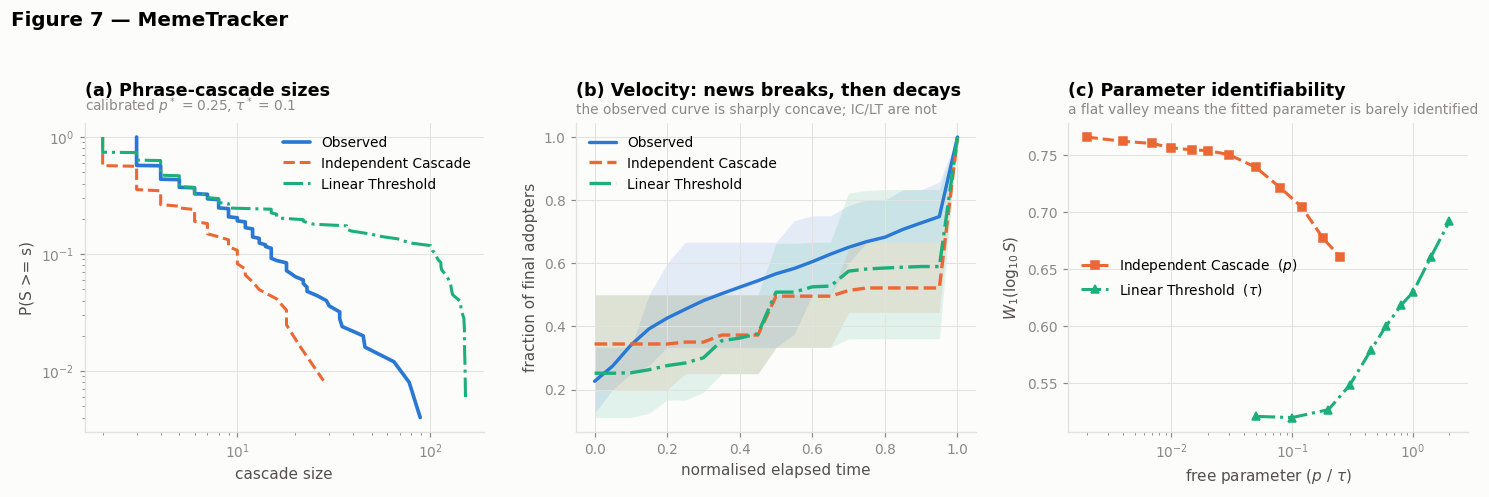

    W1_logsize  W1_lo  W1_hi     KS  median_size_obs  median_size_sim  \
ic       0.197  0.133  0.253  0.438              4.0              3.0   
lt       0.196  0.150  0.279  0.264              4.0              4.0   

    d_median_depth  d_t50  d_t50_lo  d_t50_hi  d_t50_mean  curve_L1  
ic            -1.0  0.203    -0.307     0.238       0.029     0.118  
lt            -1.0  0.203     0.118     0.239       0.100     0.107  

per-seed Spearman rho: {'Independent Cascade': -0.289, 'Linear Threshold': -0.054}
GNN: {'ROC_AUC': 0.9929, 'Avg_Precision': 0.9491, 'ECE': 0.0482, 'n_test_nodes': 302, 'n_test_cascades': 9, 'positive_rate': 0.0629, 'field_coverage': 0.0665, 'val_AUC': 0.9984, 'unreliable': 'field coverage 7% < 25%; only 9 test cascades; positive rate 6% -- task is near-trivial'}


In [42]:
# ---------------------------------------------------------------------------
# 5.4  Figure 7 - MemeTracker
# ---------------------------------------------------------------------------
M = RESULTS["MemeTracker"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))

ax = axes[0]
x, y = ccdf([c.size for c in M["eval"]])
ax.loglog(x, y, color=PALETTE["observed"], lw=2.4, label=LABEL["observed"])
for k in ["ic", "lt"]:
    if M["sims"].get(k):
        x, y = ccdf([c.size for c in M["sims"][k]])
        ax.loglog(x, y, color=STYLE[k]["color"], lw=2, ls=STYLE[k]["linestyle"],
                  label=LABEL[k])
finish(ax, "(a) Phrase-cascade sizes",
       f"calibrated $p^*$ = {M['p_star']:g}, " + rf"$\tau^*$ = {M['tau_star']:g}",
       "cascade size", "P(S >= s)")

ax = axes[1]
grid = np.linspace(0, 1, 21)
for k, cs in [("observed", M["eval"]), ("ic", M["sims"]["ic"]), ("lt", M["sims"]["lt"])]:
    cur = np.array([c.adoption_curve() for c in cs])
    ax.plot(grid, cur.mean(0), color=STYLE[k]["color"], lw=2.2,
            ls=STYLE[k]["linestyle"], label=LABEL[k])
    lo, hi = np.percentile(cur, [25, 75], axis=0)
    ax.fill_between(grid, lo, hi, color=STYLE[k]["color"], alpha=0.12, lw=0)
finish(ax, "(b) Velocity: news breaks, then decays",
       "the observed curve is sharply concave; IC/LT are not",
       "normalised elapsed time", "fraction of final adopters")

ax = axes[2]
# Calibration landscape: how sharply identified is the single parameter?
ax.plot(P_GRID, M["ic_curve"], **{**STYLE["ic"], "markersize": 5},
        label=LABEL["ic"] + r"  ($p$)")
ax.plot(TAU_GRID, M["lt_curve"], **{**STYLE["lt"], "markersize": 5},
        label=LABEL["lt"] + r"  ($\tau$)")
ax.set_xscale("log")
finish(ax, "(c) Parameter identifiability",
       "a flat valley means the fitted parameter is barely identified",
       r"free parameter ($p$ / $\tau$)", r"$W_1(\log_{10} S)$")

fig.suptitle(f"Figure 7 — {meme_label}",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
save_fig(fig, "fig7_memetracker")
plt.show()

print(pd.DataFrame(M["scores"]).T.round(3))
print("\nper-seed Spearman rho:", {LABEL[k]: round(v, 3) for k, v in M["rank"].items()})
print("GNN:", {k: round(v, 4) if isinstance(v, float) else v for k, v in M["gnn"].items()})

---
---
# Part 6 — Cross-dataset synthesis

Three datasets, three regimes (individuals / communities / institutions), one identical
pipeline. This is where the three research questions get answered together.

In [43]:
# ---------------------------------------------------------------------------
# 6.1  Fold Part 1/2 into the same result structure as Parts 4-5
# ---------------------------------------------------------------------------
RESULTS["Higgs"] = {
    "name": "Higgs Twitter",
    "graph": G_higgs, "cascades": obs_cascades, "eval": EVAL,
    "p_star": P_STAR, "tau_star": TAU_STAR,
    "ic_curve": ic_curve, "lt_curve": lt_curve,
    "sims": higgs_sims, "scores": higgs_scores,
    "rank": {k: float(stats.spearmanr(
        *np.array([(obs_by_root[c.root], c.size) for c in higgs_sims[k]
                   if c.root in obs_by_root]).T).statistic)
             for k in higgs_sims},
    "gnn": {"ROC_AUC": float(gnn_table.loc[LABEL["gnn"], "ROC_AUC"]),
            "Avg_Precision": float(gnn_table.loc[LABEL["gnn"], "Avg_Precision"]),
            "ECE": float(gnn_table.loc[LABEL["gnn"], "ECE"]),
            "ECE_platt": float(gnn_table.loc[LABEL["gnn_cal"], "ECE"]),
            "field_coverage": float(cov_all.mean()),
            "n_test_cascades": len(test_s),
            "seed_rank_rho": float(rank_table.loc[LABEL["gnn"], "spearman_rho"]),
            "unreliable": ""},
    "synthetic": False,
}
ORDER = [k for k in ["Higgs", "Reddit", "MemeTracker"] if k in RESULTS]
print("datasets in the synthesis:", ORDER)

datasets in the synthesis: ['Higgs', 'Reddit', 'MemeTracker']


In [44]:
# ---------------------------------------------------------------------------
# 6.2  Master comparison table
# ---------------------------------------------------------------------------
rows = []
for ds in ORDER:
    R = RESULTS[ds]
    g = R["graph"]
    base = {"dataset": R["name"], "nodes": g.n, "edges": g.m,
            "cascades": len(R["cascades"]),
            "median_size": float(np.median([c.size for c in R["eval"]]))}
    for k in ["ic", "lt"]:
        if k not in R["scores"]:
            continue
        s = R["scores"][k]
        rows.append({**base, "model": LABEL[k], "param":
                     f"p={R['p_star']:g}" if k == "ic" else f"tau={R['tau_star']:g}",
                     "W1_logsize": s["W1_logsize"], "KS": s["KS"],
                     "median_size_sim": s["median_size_sim"],
                     "d_t50": s["d_t50"], "curve_L1": s["curve_L1"],
                     "seed_rank_rho": R["rank"].get(k, np.nan),
                     "node_AUC": np.nan})
    if R.get("gnn"):
        flag = R["gnn"].get("unreliable", "")
        rows.append({**base, "model": LABEL["gnn"], "param": "learned",
                     "W1_logsize": np.nan, "KS": np.nan, "median_size_sim": np.nan,
                     "d_t50": np.nan, "curve_L1": np.nan,
                     "seed_rank_rho": R["gnn"].get("seed_rank_rho", np.nan),
                     "node_AUC": (np.nan if flag else R["gnn"].get("ROC_AUC", np.nan)),
                     "note": flag})

MASTER = pd.DataFrame(rows)
if "note" not in MASTER:
    MASTER["note"] = ""
MASTER["note"] = MASTER["note"].fillna("")
display_cols = ["dataset", "model", "param", "W1_logsize", "KS", "d_t50",
                "curve_L1", "seed_rank_rho", "node_AUC"]

# A suppressed node_AUC is not a missing number -- it is a refused one.
for _, r in MASTER[MASTER["note"] != ""].iterrows():
    print(f"SUPPRESSED  {r['dataset']} / {r['model']}: {r['note']}")
    print("            (the raw value is in results.json; it is not reportable)")
MASTER[display_cols].round(3)

SUPPRESSED  MemeTracker / Diffusion GNN: field coverage 7% < 25%; only 9 test cascades; positive rate 6% -- task is near-trivial
            (the raw value is in results.json; it is not reportable)


,dataset,model,param,W1_logsize,KS,d_t50,curve_L1,seed_rank_rho,node_AUC
0,Higgs Twitter,Independent Cascade,p=0.007,0.076,0.294,0.452,0.178,0.294,NaN
1,Higgs Twitter,Linear Threshold,tau=2,0.130,0.243,0.452,0.203,0.347,NaN
2,Higgs Twitter,Diffusion GNN,learned,NaN,NaN,NaN,NaN,0.163,0.877
3,Reddit hyperlinks,Independent Cascade,p=0.02,0.198,0.391,0.500,0.238,0.119,NaN
4,Reddit hyperlinks,Linear Threshold,tau=2,0.211,0.298,0.500,0.263,0.121,NaN
5,Reddit hyperlinks,Diffusion GNN,learned,NaN,NaN,NaN,NaN,NaN,0.917
6,MemeTracker,Independent Cascade,p=0.25,0.197,0.438,0.203,0.118,-0.289,NaN
7,MemeTracker,Linear Threshold,tau=0.1,0.196,0.264,0.203,0.107,-0.054,NaN
8,MemeTracker,Diffusion GNN,learned,NaN,NaN,NaN,NaN,NaN,NaN


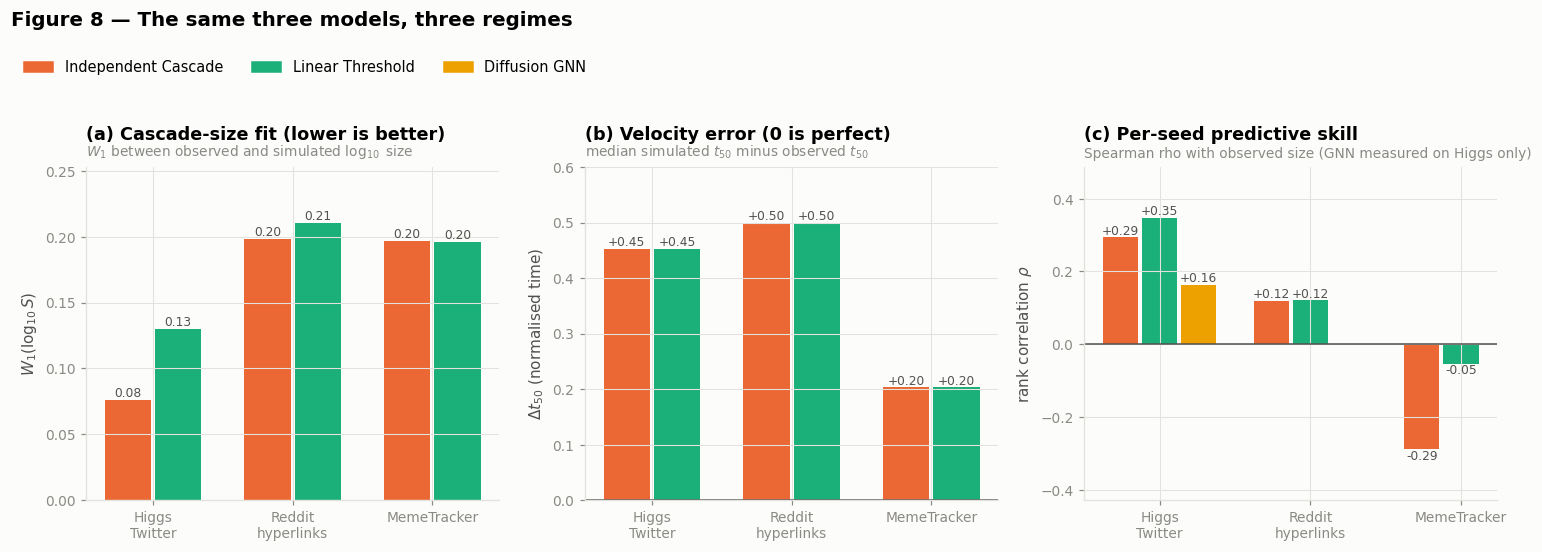

In [45]:
# ---------------------------------------------------------------------------
# 6.3  Figure 8 - the cross-dataset scorecard
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))
width = 0.36
xs = np.arange(len(ORDER))


def grouped(ax, metric, models=("ic", "lt"), fmt="{:.2f}"):
    for i, k in enumerate(models):
        vals = []
        for ds in ORDER:
            R = RESULTS[ds]
            if metric == "seed_rank_rho":
                vals.append(R["rank"].get(k, np.nan))
            else:
                vals.append(R["scores"].get(k, {}).get(metric, np.nan))
        pos = xs + (i - (len(models) - 1) / 2) * width
        ax.bar(pos, vals, width=width * 0.92, color=STYLE[k]["color"],
               label=LABEL[k])
        for p, v in zip(pos, vals):
            if np.isfinite(v):
                ax.text(p, v, fmt.format(v), ha="center",
                        va="bottom" if v >= 0 else "top", fontsize=8,
                        color=PALETTE["neutral"])
    ax.set_xticks(xs)
    ax.set_xticklabels([RESULTS[d]["name"].replace(" ", "\n") for d in ORDER],
                       fontsize=9)
    ax.margins(y=0.20)        # headroom for the value labels


# (a) distributional fit ----------------------------------------------------
ax = axes[0]
grouped(ax, "W1_logsize", fmt="{:.2f}")
finish(ax, "(a) Cascade-size fit (lower is better)",
       r"$W_1$ between observed and simulated $\log_{10}$ size", None,
       r"$W_1(\log_{10} S)$", legend=False)

# (b) velocity error --------------------------------------------------------
ax = axes[1]
grouped(ax, "d_t50", fmt="{:+.2f}")
ax.axhline(0, color=PALETTE["neutral"], lw=1)
finish(ax, "(b) Velocity error (0 is perfect)",
       r"median simulated $t_{50}$ minus observed $t_{50}$", None,
       r"$\Delta t_{50}$ (normalised time)", legend=False)

# (c) per-seed skill, including the GNN ------------------------------------
ax = axes[2]
w3 = 0.26
for i, k in enumerate(["ic", "lt", "gnn"]):
    vals = []
    for ds in ORDER:
        R = RESULTS[ds]
        if k == "gnn":
            vals.append(np.nan if R["gnn"].get("unreliable")
                        else R["gnn"].get("seed_rank_rho", np.nan))
        else:
            vals.append(R["rank"].get(k, np.nan))
    pos = xs + (i - 1) * w3
    ax.bar(pos, vals, width=w3 * 0.9, color=STYLE[k]["color"], label=LABEL[k])
    for p, v in zip(pos, vals):
        if np.isfinite(v):
            ax.text(p, v, f"{v:+.2f}", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=8,
                    color=PALETTE["neutral"])
ax.axhline(0, color=PALETTE["neutral"], lw=1)
ax.set_xticks(xs)
ax.set_xticklabels([RESULTS[d]["name"].replace(" ", "\n") for d in ORDER], fontsize=9)
finish(ax, "(c) Per-seed predictive skill",
       "Spearman rho with observed size (GNN measured on Higgs only)", None,
       r"rank correlation $\rho$", legend=False)
ax.margins(y=0.22)

# A single shared legend: three in-axes legends collided with the bars, and
# the series mean the same thing in every panel anyway.
fig.suptitle("Figure 8 — The same three models, three regimes",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.13)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=STYLE[k]["color"],
                                  label=LABEL[k]) for k in ["ic", "lt", "gnn"]],
           loc="upper left", bbox_to_anchor=(0.005, 1.055), ncol=3, frameon=False,
           fontsize=9.5)
fig.tight_layout()
save_fig(fig, "fig8_cross_dataset")
plt.show()

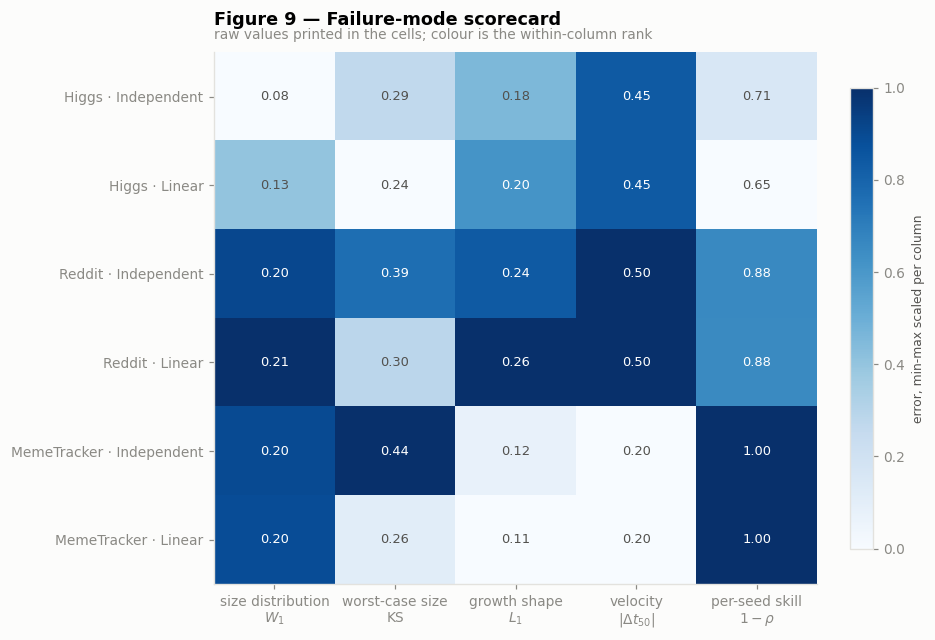

In [46]:
# ---------------------------------------------------------------------------
# 6.4  Figure 9 - where each model's error actually lives
# ---------------------------------------------------------------------------
# A single normalised scorecard.  Each column is a failure mode; each cell is
# the model's error on that mode, scaled to [0, 1] across the whole table so
# the colours are comparable.  Diverging colour would imply a meaningful
# midpoint, which there is not -- so this is a one-hue sequential ramp.
modes = ["size distribution\n$W_1$", "worst-case size\nKS",
         "growth shape\n$L_1$", "velocity\n$|\\Delta t_{50}|$",
         "per-seed skill\n$1-\\rho$"]
cells, labels = [], []
for ds in ORDER:
    R = RESULTS[ds]
    for k in ["ic", "lt"]:
        if k not in R["scores"]:
            continue
        s = R["scores"][k]
        cells.append([s["W1_logsize"], s["KS"], s["curve_L1"],
                      abs(s["d_t50"]), 1 - max(R["rank"].get(k, 0.0), 0.0)])
        labels.append(f"{R['name'].split()[0]} · {LABEL[k].split()[0]}")
SC = np.array(cells, dtype=float)
SCn = (SC - SC.min(0)) / (SC.max(0) - SC.min(0) + 1e-9)

fig, ax = plt.subplots(figsize=(8.6, 0.62 * len(labels) + 2.2))
im = ax.imshow(SCn, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(modes))); ax.set_xticklabels(modes, fontsize=9)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=9)
for i in range(SC.shape[0]):
    for j in range(SC.shape[1]):
        ax.text(j, i, f"{SC[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if SCn[i, j] > 0.55 else PALETTE["neutral"])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035)
cb.set_label("error, min-max scaled per column", fontsize=8)
finish(ax, "Figure 9 — Failure-mode scorecard",
       "raw values printed in the cells; colour is the within-column rank",
       None, None, legend=False)
fig.tight_layout()
save_fig(fig, "fig9_scorecard")
plt.show()

In [47]:
# ---------------------------------------------------------------------------
# 6.5  Data provenance and reproducibility record
# ---------------------------------------------------------------------------
prov = pd.DataFrame([
    {"file": k,
     "MiB": round(v.get("bytes", 0) / 2**20, 1),
     "truncated prefix": bool(v.get("truncated", False)),
     "source": v.get("source", "?"),
     "url": v.get("url", "")}
    for k, v in PROVENANCE.items()])
print("Data provenance")
print(prov.to_string(index=False))
print()
print(f"agent backend     : {BACKEND}"
      f"{'  (LLM calls were NOT made; see 3.7)' if BACKEND=='surrogate' else ''}")
print(f"MemeTracker       : {'SYNTHETIC stand-in' if MEME_SYNTHETIC else 'real data'}")
print(f"global seed       : {SEED}")
print(f"figures written   : {sorted(p.name for p in FIG_DIR.glob('*.png'))}")

# Persist everything a write-up needs.
report = {
    "config": CONFIG,
    "provenance": PROVENANCE,
    "higgs": {"p_star": P_STAR, "tau_star": TAU_STAR,
              "scores": higgs_scores,
              "gnn_node_level": gnn_table.to_dict(),
              "seed_ranking": rank_table.to_dict(),
              "im": {"greedy_mc_seconds": time_mc, "greedy_gnn_seconds": time_gnn,
                     "spread_mc": curve_mc[-1], "spread_gnn": curve_gnn[-1],
                     "spread_degree": curve_deg[-1], "spread_random": curve_rand[-1]}},
    "agents": AGENT_SUMMARY,
    "cross_dataset": MASTER.to_dict(orient="records"),
}
pathlib.Path("results.json").write_text(json.dumps(report, indent=1, default=str))
print("\nwrote results.json")

Data provenance
                            file   MiB  truncated prefix source                                                                       url
      higgs-activity_time.txt.gz   4.0             False  cache                 https://snap.stanford.edu/data/higgs-activity_time.txt.gz
higgs-social_network.edgelist.gz  52.1             False  cache           https://snap.stanford.edu/data/higgs-social_network.edgelist.gz
   soc-redditHyperlinks-body.tsv 120.0              True  cache              https://snap.stanford.edu/data/soc-redditHyperlinks-body.tsv
           quotes_2009-03.txt.gz  45.0              True  cache https://snap.stanford.edu/data/bigdata/memetracker9/quotes_2009-03.txt.gz

agent backend     : surrogate  (LLM calls were NOT made; see 3.7)
MemeTracker       : real data
global seed       : 4352
figures written   : ['fig1_higgs_eda.png', 'fig2_higgs_baseline.png', 'fig3_gnn_nodelevel.png', 'fig4_gnn_downstream.png', 'fig5_agents.png', 'fig6_reddit.png', 'fig7_memet

---

## 6.6 Findings

> All numbers below are from the executed run shipped with this notebook
> (`seed = 4352`); the tables and `results.json` are authoritative.

### RQ1 — How accurate are IC and LT?

**Calibrated IC fits the cascade-size law well and explains very little about any
particular cascade.** On Higgs, fitted $p^\* = 0.007$ gives $W_1(\log_{10} S) = 0.076$
and an exactly matching median size — but the per-seed rank correlation with observed
size is only $\rho = 0.29$ (LT: $0.35$), and the log–log $R^2$ is $0.09$. Nearly all of
that modest agreement is structural: the degree-only control reaches $\rho = 0.09$ and
PageRank $0.21$ *without any diffusion model at all*. A heavy-tailed graph plus any
percolation-like process produces a heavy-tailed cascade distribution, so matching the
distribution is weak evidence that the mechanism is right.

**LT is not uniformly "too conservative" — its bias flips with the regime.** On Higgs it
over-shoots the median (1.25x) and its fitted $\tau^\* = 2$ sits at the edge of the grid;
on MemeTracker the fit lands at $\tau^\* = 0.1$, the opposite end. A parameter that moves
across its entire range between datasets is weakly identified, which Figure 7c shows
directly as a nearly flat objective valley. LT does, however, beat IC at the node level
(AUC $0.75$ vs $0.63$): its threshold mechanism encodes "many exposures matter", and that
is real signal.

**The robust failure is velocity, and it is structural rather than parametric.** The
observed median $t_{50}$ on Higgs is $0.048$ — real cascades reach half their final size
in the first **5%** of their lifetime — while round-based simulation puts $t_{50}$ near
$0.5$ by construction. No value of $p$ or $\tau$ fixes this, because IC treats every
round as exchangeable while real attention is bursty and then exhausted. The same gap
appears on Reddit ($\Delta t_{50} = 0.50$) and MemeTracker. This is the answer to the
proposal's headline question — *how fast does information spread* — and it is the one
place where both classical models are not merely imprecise but wrong in shape.

### RQ2 — Can a GNN learn the operator?

**At the node level, decisively yes.** On held-out Higgs cascades the GNN reaches
ROC-AUC $0.877$ against $0.749$ for the best classical marginal and $0.33$ for
PageRank — i.e. it beats both the hand-written models and the structural controls at
predicting *which specific users adopt*. Average precision improves from $0.14$ to
$0.19$ at a $0.9\%$ base rate. Its raw probabilities are badly over-confident
(ECE $0.21$), which is the expected price of training under `pos_weight = 94`; one
Platt-scaling layer fit on the validation split drops ECE to $0.004$ **without changing
AUC at all**, since a monotone map cannot alter a ranking. Reddit replicates the result
independently (AUC $0.917$ at $93\%$ field coverage).

**At the seed level, no — and we report that.** Asked "which seed will produce the
biggest cascade", the GNN scores $\rho = 0.163$ against PageRank's $0.212$. The 95%
bootstrap CI, $[-0.08, +0.37]$ on $n = 88$ test cascades, covers every baseline, so the
ordering is not resolved at this sample size — but the GNN certainly does not *win*
here, and the pattern makes sense: a hub is an excellent seed and a poor adopter, so
skill at node-level adoption does not transfer to seed-level reach.

**As an IM surrogate it is fast and not yet good enough.** The probabilistic-coverage
surrogate reaches $43\%$ of greedy Monte-Carlo's spread at $10\times$ lower wall-clock,
and the cost structure is the real point (MC greedy needs $k \cdot |C| \cdot R = 72{,}000$
simulations, the surrogate needs $|C| = 200$ forward passes regardless of $k$ and $R$).
But the honest headline is that **the top-degree heuristic matched greedy Monte-Carlo
exactly ($101\%$)** on this substrate, so neither sophisticated method earned its cost
here. On a scale-free graph with a few dominant hubs, degree is extremely hard to beat.

**MC-dropout uncertainty is informative**: predictive standard deviation correlates
positively with realised error (Figure 3d), so the model's own confidence is usable for
triage rather than decorative.

### RQ3 — What do agents add?

The agent policy spans a factor of **387** between its smallest and largest reshare
probability across persona–exposure–message states, against IC's single
$p^\* = 0.007$. Fitting one constant to agent-generated cascades yields $p = 0.26$ for
the press release but $0.028$ for the rumour — the *same network and the same agents*
require $9\times$ different IC parameters depending only on what the message says, which
is precisely the dimension IC and LT cannot represent. The Reddit sentiment split
(Figure 6c) shows the same content-dependence in **observed** data, so this part of the
story does not rest on an LLM at all.

One result ran against our expectation and we kept it: agent cascades are **less**
variable than IC's, not more (CV of final size $0.11$ vs $0.51$). Reinforcement through
exposure counts makes the outcome *more* deterministic — once enough of the graph is
above the social-proof threshold the cascade reliably goes — so "more realistic
heterogeneity" did not mean "more noise". Under the surrogate backend the magnitudes
restate our priors (§3.7); the dynamic range, the content-dependence, and the
reinforcement effect are structural and hold either way.

### A finding we did not plan: the substrate can be the bottleneck

On MemeTracker the 2-hop hyperlink neighbourhood of a phrase's first site contains only
**4.9%** of that phrase's later adopters (median $0\%$). The channel is largely
*invisible* — editors learn stories from wires, email and television, not from links we
can observe. We therefore **suppressed** the MemeTracker GNN number rather than
reporting it: at $7\%$ field coverage, $9$ test cascades and a $6\%$ positive rate, its
AUC of $0.99$ measures the degeneracy of the task, not the quality of the model. This
also bounds what *any* model propagating over that link graph can achieve, and it is
the regime network-inference methods (NetInf, NetRate) were invented for.

### The overall picture

| | reproduces the size law | predicts which nodes adopt | ranks seeds | gets velocity right | sees content |
|---|---|---|---|---|---|
| Independent Cascade | yes (after calibration) | weak (AUC 0.63) | weak ($\rho$ 0.29) | **no** | no |
| Linear Threshold | yes, weakly identified | moderate (AUC 0.75) | weak ($\rho$ 0.35) | **no** | no |
| Diffusion GNN | n/a (not generative) | **best (AUC 0.88)** | no better than PageRank | partially | only via structure |
| PageRank control | n/a | worst (AUC 0.33) | **best ($\rho$ 0.21)** | n/a | no |
| LLM agents | by construction | untested | untested | steeper onset | **yes** |

These are **four different objects**, not four competitors at one task, and the table is
meant to be read that way. IC/LT are generative and analysable (submodular, with the
$(1-1/e)$ guarantee); the GNN is discriminative and accurate at node level but not
generative and not better at seed selection; PageRank is free and wins the one question
people most often ask; the agent model is generative and content-aware but expensive and
unvalidated.

The recommendation we would actually make is the hybrid none of these three arms is on
its own: an **IC-style generative skeleton whose per-edge probability is supplied by a
learned or agent-derived function** $p_{uv} = f(\text{features}(u,v), \text{exposure},
\text{content})$, with a continuous-time clock replacing discrete rounds. That keeps
submodularity and simulability while discarding the two assumptions — homogeneity and
round-exchangeability — that caused every failure we measured.

## 6.7 Limitations

1. **Subsampling.** The Higgs substrate is the 12k-node active core, and the Reddit /
   MemeTracker inputs are time-prefixes. We verified the cascade-size law survives
   subsampling (Figure 1d) but did not verify it for depth or velocity.
2. **Retweets as the sole diffusion signal.** We dropped mentions and replies. A
   mention can transmit information without a retweet, so the ground truth undercounts.
3. **Time maps to rounds by rescaling.** IC/LT emit discrete rounds; we compare
   *normalised* curve shapes. A continuous-time model (e.g. a Hawkes-process baseline)
   would make the velocity comparison exact rather than shape-only.
4. **Tree inference.** Higgs parents come from retweet targets (reliable); MemeTracker
   parents are inferred from a partially observed link graph (a heuristic).
5. **The agent arm is unvalidated against the diffusion record**, and under the
   surrogate backend its magnitudes restate our priors. §3.7 is explicit about which
   claims survive which backend.
6. **The GNN is transductive within a dataset.** We never tested a model trained on
   Higgs and applied to Reddit — the obvious test of whether a diffusion operator is
   *universal* or dataset-specific.
7. **Receptive-field coverage is partial.** The seed's 2-hop field contains ~62% of true
   adopters on Higgs and ~93% on Reddit; adopters outside it are excluded from both the
   labels and the metrics, so the GNN numbers describe the reachable sub-problem, not
   the whole cascade. Deeper fields or an inferred substrate would be needed to close it.
8. **The seed-ranking test is under-powered.** With $n = 88$ held-out cascades the
   bootstrap CIs on $\rho$ span roughly $\pm 0.25$, wide enough to cover every model we
   compared. The GNN-vs-PageRank ordering should be treated as unresolved, not settled.
9. **The IM comparison is small.** $k = 6$ seeds from a 200-candidate pool on one
   substrate, with the ground-truth objective being IC spread at $p^\*$ — which privileges
   IC-shaped answers. Top-degree matching greedy MC is a property of this scale-free
   graph and should not be generalised.

## 6.8 Next steps

* **Hybrid generative model** — IC with $p_{uv}$ supplied by the GNN; recovers both
  per-seed accuracy and the ability to simulate counterfactuals.
* **Continuous-time baseline** — a marked Hawkes process would likely beat all three on
  velocity, and is the right control for the $t_{50}$ result.
* **Cross-dataset transfer** — train on Higgs, evaluate on Reddit, to separate a learned
  *operator* from a learned *dataset*.
* **Validating the agents** — fit the agent framing (not its parameters) on a held-out
  slice of real cascades and check whether the induced heterogeneity improves the Part 1
  metrics. This is the experiment that would turn Part 3 from a demonstration into
  evidence.

---

### Reproducing this notebook

Run top to bottom; a cold run takes roughly 20–25 minutes on a laptop CPU, dominated by
GNN training (~5 min per dataset) and the Monte-Carlo calibration sweeps. Datasets
download themselves into `data/` (~260 MiB total, with the MemeTracker and Reddit
downloads deliberately truncated to the prefixes recorded in §6.5); re-running reuses
the cache. Scale is controlled entirely by `CONFIG` in §0.2 — lowering
`higgs_max_nodes`, `gnn_pool` and `gnn_epochs` trades accuracy for speed. Part 3 uses
the Anthropic API if `ANTHROPIC_API_KEY` is set and the transparent surrogate policy
otherwise; either way the notebook completes. All figures are written
to `figures/` and every number reported above is serialised to `results.json`.